### init

In [1]:
import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [2]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [3.2489276324892766, 2.0079477038671003]


### with old dataset and all 16bit

In [ ]:
api = wandb.Api()
results = []
# t_run = tqdm(api.sweep("ddold/subspace_bezier_length_dnn/taa7hglw").runs)
for s in ["yqlk3puv",]:
# for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

yqlk3puv:   0%|          | 0/96 [00:00<?, ?it/s, major-sweep-90]    

yqlk3puv: 100%|██████████| 96/96 [00:00<00:00, 347.09it/s, glowing-sweep-1]   


,Id,NumSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,kz2axb5d,2,16,0.01,boolq,19.841238,0.889375,0.886813,0.289062,0.292969
1,5yzv7v76,2,8,0.01,boolq,19.822430,0.885937,0.883388,0.298828,0.300781
2,bmfwlzr3,2,4,0.01,boolq,19.825733,0.882500,0.880325,0.289062,0.292969
3,kddkh5rk,2,1,0.01,boolq,19.841034,0.884375,0.881288,0.292969,0.294922
4,ogy1fd4y,0,16,0.00,boolq,0.000000,0.888438,0.888437,0.289062,0.289062
...,...,...,...,...,...,...,...,...,...,...
91,40ndqj5o,0,1,0.01,obqa,0.000000,0.894000,0.894000,0.392578,0.392578
92,uabqy14s,0,16,0.01,winogrande_m,0.000000,0.776667,0.776667,0.828125,0.828125
93,bdpj3rs1,0,8,0.01,winogrande_m,0.000000,0.759167,0.759167,0.878906,0.878906
94,lrs0s3bk,0,4,0.01,winogrande_m,0.000000,0.770000,0.770000,0.820312,0.820312


In [89]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,NumSpace,Seed,WeightDecay,Dataset,,,,,


In [90]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")

Unique configuartions: 
NumSpace [2 0]
Seed [16  8  4  1]
WeightDecay [0.01 0.  ]
Dataset ['boolq' 'ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['NumSpace', 'WeightDecay', 'Dataset'] configs


In [91]:
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [92]:
# Reference accuracy values from table
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}


#### acc

/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From 

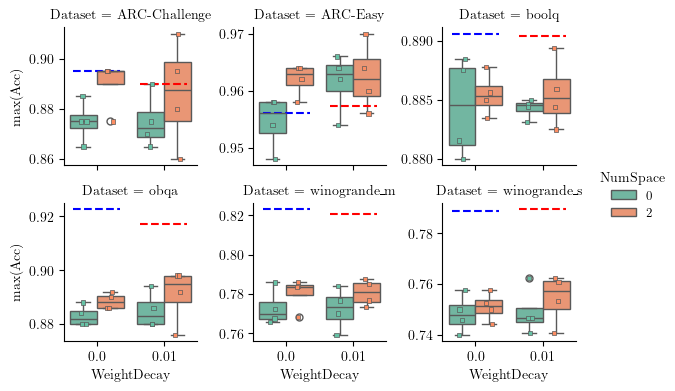

In [ ]:

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )

g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

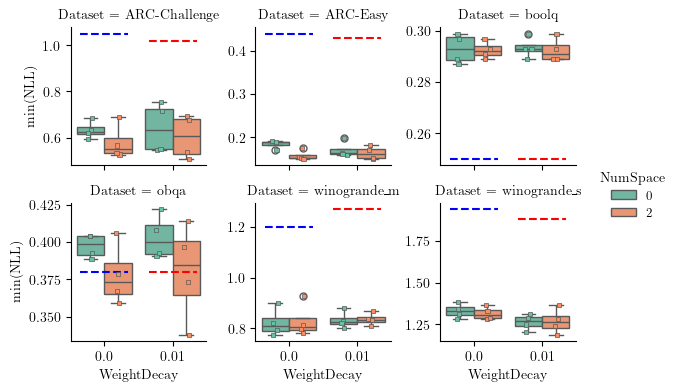

In [ ]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with lora for lmhead and 32bit lora and new dataset

In [10]:
api = wandb.Api()
results = []
for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # drop runs with k>0 because of error in those runs
        if run.config['curve_params']['k'] == 0:
            res = dict(Id=run.id,
                        CurveSpace=run.config['curve_params']['k'],
                        Seed=run.config['rng_seed'],
                        WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                        Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                        bezierLength=run.summary.get('Curve length', 0),
                        acc_max=run.summary['final_acc_max'],
                        acc_mean=run.summary['final_acc_mean'],
                        nll_min=run.summary['final_loss_min'],
                        nll_mean=run.summary['final_loss_mean'],
                )
            results.append(res)

for s in ["0lqp05qb",]: # with lora for lmhead and 32bit lora and new dataset and no bias learning
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)


df = pd.DataFrame(results)
df

vj9z5em9:   0%|          | 0/96 [00:00<?, ?it/s, amber-sweep-67]   

0lqp05qb: 100%|██████████| 48/48 [00:00<00:00, 381.35it/s, glorious-sweep-1]


,Id,CurveSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,z51vrw9d,0,16,0.00,ARC-Easy,0.000000,0.956000,0.9560,0.271484,0.271484
1,ly92c21c,0,8,0.00,ARC-Easy,0.000000,0.958000,0.9580,0.269531,0.269531
2,t1ys9evr,0,4,0.00,ARC-Easy,0.000000,0.960000,0.9600,0.308594,0.308594
3,9581cv0o,0,1,0.00,ARC-Easy,0.000000,0.952000,0.9520,0.269531,0.269531
4,lwra1vhw,0,16,0.00,ARC-Challenge,0.000000,0.885000,0.8850,0.980469,0.980469
...,...,...,...,...,...,...,...,...,...,...
91,ybzhhopf,2,1,0.01,winogrande_s,2323.270752,0.770833,0.7586,1.140625,1.375000
92,8b40jvf1,2,16,0.01,winogrande_m,2322.336426,0.782500,0.7709,0.800781,0.929688
93,0hw1ze77,2,8,0.01,winogrande_m,2322.122070,0.785833,0.7764,0.820312,0.976562
94,uo0yf7tt,2,4,0.01,winogrande_m,2322.653809,0.787500,0.7789,0.804688,0.898438


In [11]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Seed,WeightDecay,Dataset,,,,,


In [12]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [0 2]
Seed [16  8  4  1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

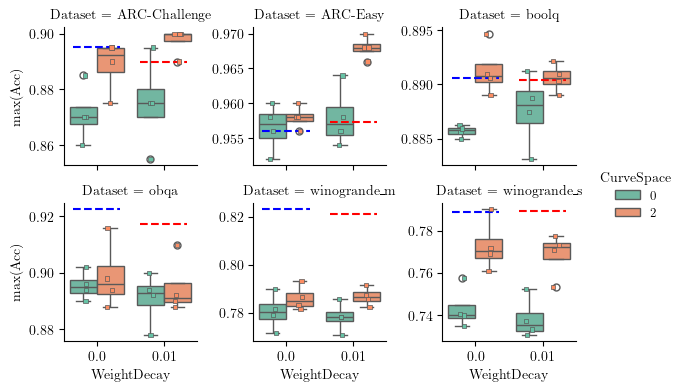

In [13]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

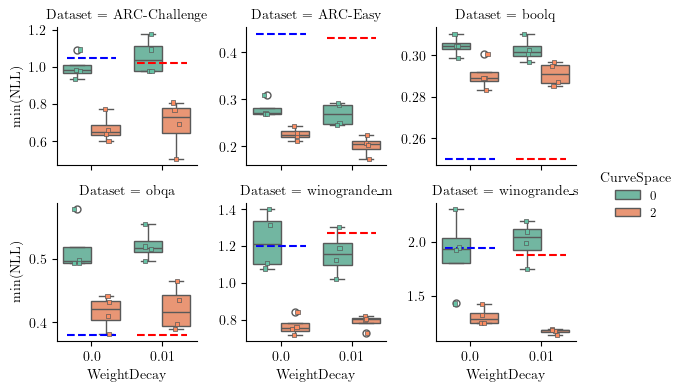

In [14]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### only curve compare with longer training 100_000 steps and different jitter and two new seeds

In [48]:
api = wandb.Api()
results = []
for s in ["tfpynhck",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

tfpynhck: 100%|██████████| 72/72 [00:00<00:00, 437.35it/s, devout-sweep-1]        


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xpz4zlz3,2,5.0,7,0.01,ARC-Easy,11583.458984,0.296000,0.254560,1.382812,1.390625
1,u3ecxkwz,2,5.0,6,0.01,ARC-Easy,11584.446289,0.956000,0.938560,0.203125,0.277344
2,yzwme8xu,2,5.0,4,0.01,ARC-Easy,11584.413086,0.282000,0.253280,1.382812,1.390625
3,vpow0gs8,2,5.0,1,0.01,ARC-Easy,11587.439453,0.316000,0.268320,1.398438,1.445312
4,gy40kqo3,2,5.0,7,0.01,ARC-Challenge,11583.307617,0.860000,0.829600,0.843750,0.953125
...,...,...,...,...,...,...,...,...,...,...,...
67,y4geo7qb,2,1.0,7,0.01,winogrande_m,2316.600098,0.783333,0.772900,1.015625,1.156250
68,6en36155,2,1.0,1,0.01,winogrande_s,2317.422363,0.767500,0.752933,1.500000,1.804688
69,3nunf43m,2,1.0,6,0.01,winogrande_m,2316.818848,0.797500,0.786533,0.933594,1.125000
70,12tvj3l9,2,1.0,4,0.01,winogrande_m,2316.797852,0.800833,0.787866,0.933594,1.132812


In [49]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [50]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [5.  0.5 1. ]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['Jitter', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

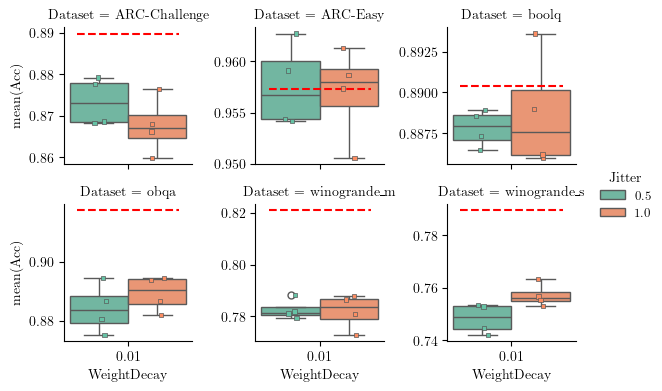

In [51]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}

df_clean = df_clean[df_clean['Jitter']<5]

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='Jitter', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Jitter',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

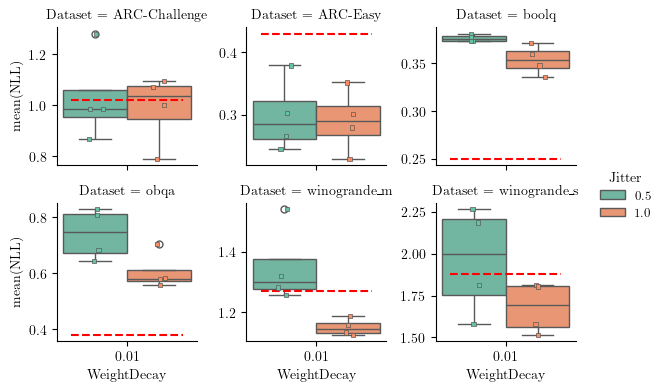

In [52]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='Jitter', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Jitter',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### Reruns from scalabl

In [53]:
api = wandb.Api()
results = []
t_run = tqdm(api.runs(f"ddold/MLE-Qwen2.5-7B-all"))
t_run.set_description(s)
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    # drop runs with k>0 because of error in those runs
    res = dict(Id=run.id,
                CurveSpace=0,
                Seed=run.config['seed'],
                Dataset=run.config['dataset'],
                WeightDecay=0,
                acc=run.summary['final_val_acc'],
                nll=run.summary['final_val_nll'],
                ece=run.summary['final_val_ece'],
        )
    results.append(res)


df = pd.DataFrame(results)
df

tfpynhck: 100%|██████████| 38/38 [00:00<00:00, 2255.51it/s, mle-boolq-seed3]


,Id,CurveSpace,Seed,Dataset,WeightDecay,acc,nll,ece
0,o1dulwhl,0,6,winogrande_s,0,0.779272,2.031250,0.205545
1,wgxbatmk,0,2,winogrande_s,0,0.775316,2.500000,0.218704
2,qvw1l26p,0,2,winogrande_s,0,0.775316,2.500000,0.218704
3,rn2t593s,0,6,winogrande_s,0,0.779272,2.031250,0.205545
4,4vjwwd1s,0,2,ARC-Challenge,0,0.898649,1.023438,0.104334
5,qo0agtmt,0,6,ARC-Challenge,0,0.898649,1.148438,0.100098
6,2ztl882y,0,6,ARC-Easy,0,0.954225,0.433594,0.042859
7,9k88c90n,0,2,ARC-Easy,0,0.955986,0.457031,0.039833
8,eu6ogm6l,0,2,winogrande_m,0,0.816456,1.203125,0.162480
9,tspr1v8i,0,6,winogrande_m,0,0.829114,1.132812,0.151753


In [54]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,acc,nll,ece
Id,CurveSpace,Seed,Dataset,WeightDecay,,,


In [55]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [0]
Seed [6 2 7 4 3 5]
Dataset ['winogrande_s' 'ARC-Challenge' 'ARC-Easy' 'winogrande_m' 'obqa' 'boolq']
WeightDecay [0]

Experiment differs in ['Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

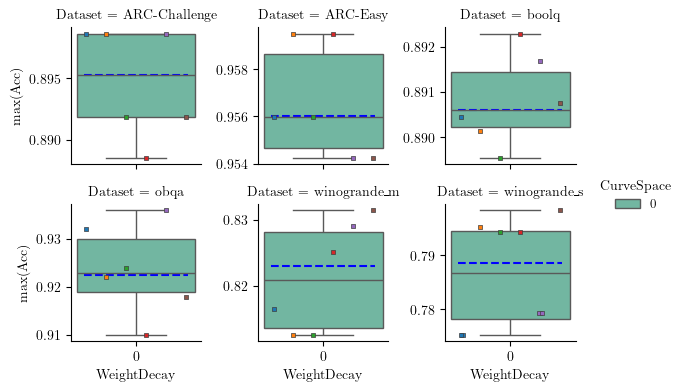

In [56]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

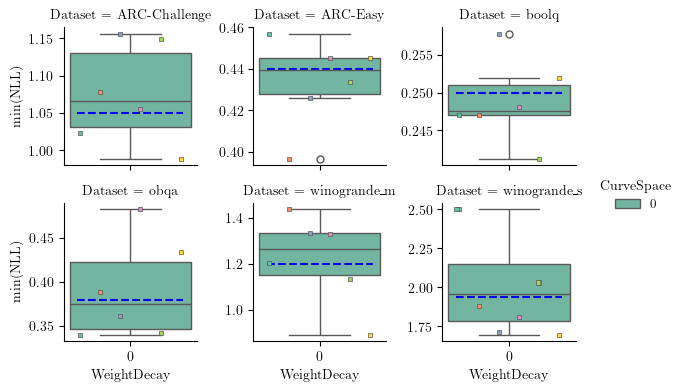

In [59]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with new scaling behavior for LoRA (lora_alpha parameter)

In [4]:
api = wandb.Api()
results = []
for s in ["5qmpsskt",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

5qmpsskt:   0%|          | 0/40 [00:00<?, ?it/s, leafy-sweep-21]   

5qmpsskt: 100%|██████████| 40/40 [00:00<00:00, 430.25it/s, glamorous-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,ctce5vis,2,1,7,0.01,ARC-Easy,2322.504150,0.286000,0.254000,1.382812,1.382812
1,wanqj2ar,2,1,6,0.01,ARC-Easy,2322.728516,0.314000,0.262720,1.375000,1.382812
2,u9xvovko,2,1,4,0.01,ARC-Easy,2322.689453,0.300000,0.257920,1.375000,1.390625
3,948siewz,2,1,1,0.01,ARC-Easy,2323.303711,0.310000,0.260480,1.382812,1.390625
4,e568ou5g,2,1,7,0.01,ARC-Challenge,2322.484863,0.315000,0.279200,1.382812,1.484375
5,2f2n4smv,2,1,6,0.01,ARC-Challenge,2322.709717,0.310000,0.273400,1.390625,1.390625
6,iqrc2jd6,2,1,4,0.01,ARC-Challenge,2322.682129,0.310000,0.266200,1.390625,1.390625
7,c85gkqkv,2,1,1,0.01,ARC-Challenge,2323.312988,0.335000,0.266600,1.382812,1.390625
8,n3dnw2vz,2,1,7,0.01,obqa,2322.505615,0.252000,0.252000,1.382812,1.382812
9,unr0x2r3,2,1,6,0.01,obqa,2322.716064,0.314000,0.266960,1.382812,1.382812


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [1]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


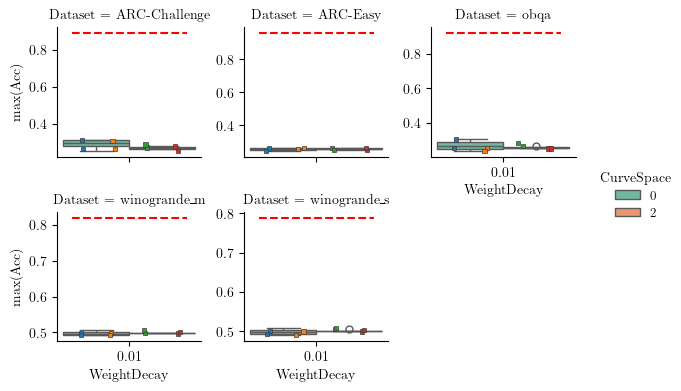

In [9]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


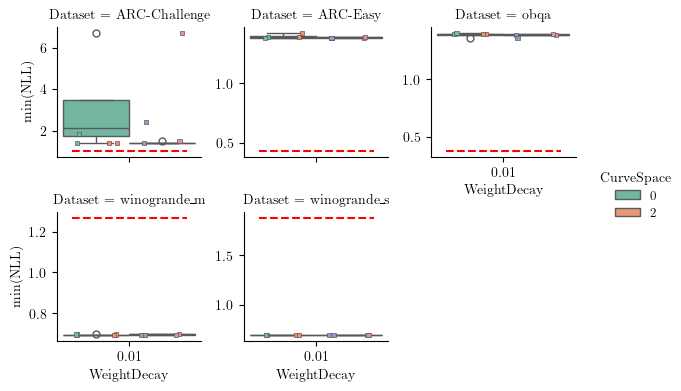

In [10]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### changed lora A matrix initialization to he_uniform 
(from he normal) with a leak_relu gain

In [11]:
api = wandb.Api()
results = []
for s in ["xe2hkb5h",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

xe2hkb5h:   0%|          | 0/48 [00:00<?, ?it/s, fragrant-sweep-39] 

xe2hkb5h: 100%|██████████| 48/48 [00:00<00:00, 227.18it/s, radiant-sweep-1]  


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,f4vwob68,2,1,7,0.01,ARC-Easy,2322.484619,0.294000,0.256960,1.382812,1.398438
1,w91ihub4,2,1,6,0.01,ARC-Easy,2322.701660,0.300000,0.257520,1.382812,1.390625
2,be2i28qa,2,1,4,0.01,ARC-Easy,2322.699219,0.296000,0.255920,1.375000,1.390625
3,2mntsbow,2,1,1,0.01,ARC-Easy,2323.312988,0.302000,0.261360,1.382812,1.398438
4,4d45ttle,2,1,7,0.01,ARC-Challenge,2322.492676,0.315000,0.257200,1.382812,1.398438
5,zx3k8ld6,2,1,6,0.01,ARC-Challenge,2322.723633,0.335000,0.284800,1.382812,1.390625
6,lfk4yxrz,2,1,4,0.01,ARC-Challenge,2322.675781,0.340000,0.291400,1.367188,1.390625
7,5e3fqg5w,2,1,1,0.01,ARC-Challenge,2323.314453,0.310000,0.257600,1.382812,1.390625
8,sr27gufy,2,1,7,0.01,obqa,2322.490234,0.276000,0.254880,1.382812,1.390625
9,7zonu1nu,2,1,6,0.01,obqa,2322.706543,0.280000,0.255840,1.382812,1.382812


In [12]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [13]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [1]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

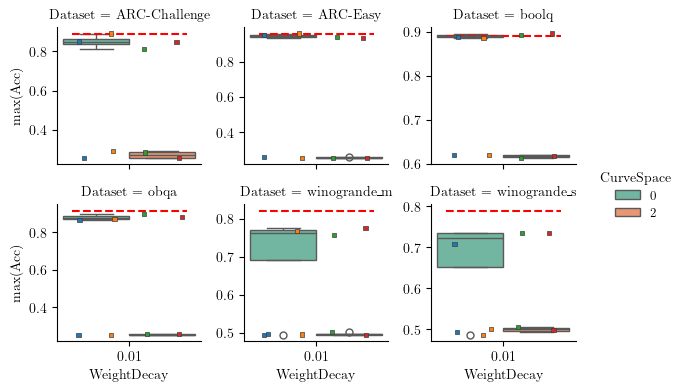

In [15]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

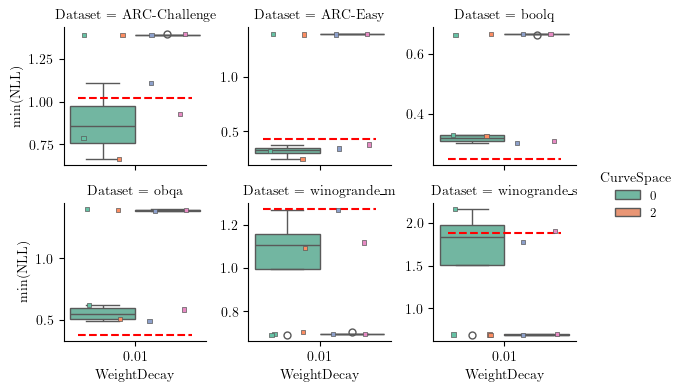

In [16]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### fixes and no noise for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ no noise for curve

In [5]:
api = wandb.Api()
results = []
for s in ["0nx704d3",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

0nx704d3:   0%|          | 0/48 [00:00<?, ?it/s, vivid-sweep-37]   

0nx704d3: 100%|██████████| 48/48 [00:00<00:00, 392.13it/s, glorious-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xqosvrr7,2,0,7,0.01,ARC-Easy,6.144023,0.956000,0.953440,0.343750,0.378906
1,ww08b05p,2,0,6,0.01,ARC-Easy,5.367301,0.968000,0.963760,0.287109,0.310547
2,mx0bd9k4,2,0,1,0.01,ARC-Easy,5.832235,0.966000,0.959280,0.222656,0.253906
3,96c2xhyj,2,0,4,0.01,ARC-Easy,5.940700,0.968000,0.964160,0.279297,0.292969
4,re7621i7,2,0,7,0.01,ARC-Challenge,5.046455,0.905000,0.895600,0.984375,1.078125
5,dcm2faci,2,0,6,0.01,ARC-Challenge,5.842677,0.900000,0.892400,0.746094,0.781250
6,ajw1nfxq,2,0,1,0.01,ARC-Challenge,6.049755,0.915000,0.907400,0.765625,0.804688
7,0dygel1f,2,0,4,0.01,ARC-Challenge,5.509381,0.895000,0.883200,0.964844,1.093750
8,j4a0fy81,2,0,7,0.01,obqa,7.142587,0.922000,0.915520,0.419922,0.435547
9,rmx5x2ji,2,0,1,0.01,obqa,7.455338,0.910000,0.902640,0.398438,0.449219


In [6]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [7]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [0]
Seed [7 6 1 4]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

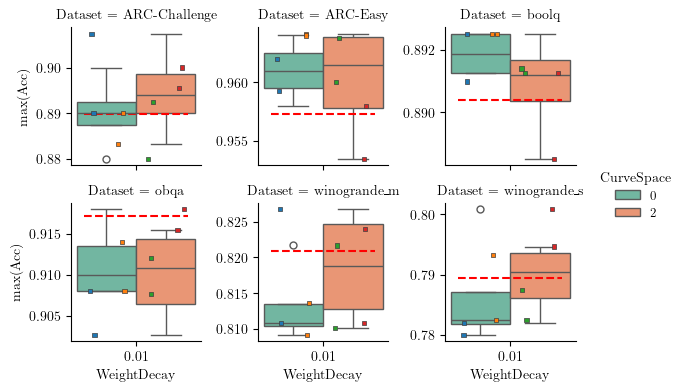

In [8]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

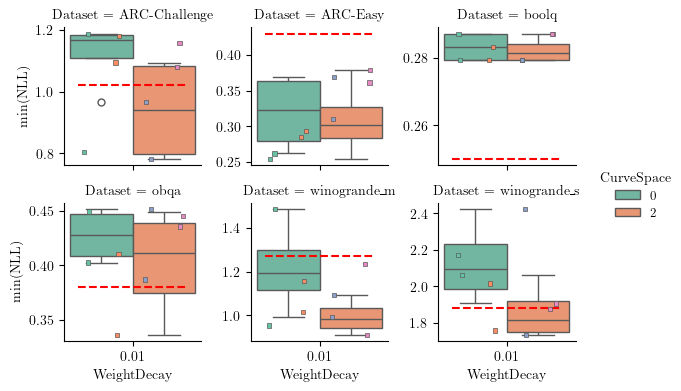

In [9]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### fixes and he_uniform init for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [22]:
api = wandb.Api()
results = []

for s in ["0nx704d3",]: # no noise
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

for s in ["ev8m11oc",]: 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace= "{} + he_u init".format(run.config['curve_params']['k']),
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

0nx704d3:   0%|          | 0/48 [00:00<?, ?it/s, grateful-sweep-25]

ev8m11oc: 100%|██████████| 24/24 [00:00<00:00, 447.16it/s, eternal-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xqosvrr7,2,0,7,0.01,ARC-Easy,6.144023,0.956000,0.953440,0.343750,0.378906
1,96c2xhyj,2,0,4,0.01,ARC-Easy,5.940700,0.968000,0.964160,0.279297,0.292969
2,mx0bd9k4,2,0,1,0.01,ARC-Easy,5.832235,0.966000,0.959280,0.222656,0.253906
3,ww08b05p,2,0,6,0.01,ARC-Easy,5.367301,0.968000,0.963760,0.287109,0.310547
4,re7621i7,2,0,7,0.01,ARC-Challenge,5.046455,0.905000,0.895600,0.984375,1.078125
...,...,...,...,...,...,...,...,...,...,...,...
67,d54b6snc,2 + he_u init,0,1,0.01,winogrande_s,24.601696,0.783333,0.777367,2.234375,2.375000
68,0kw96szg,2 + he_u init,0,7,0.01,winogrande_m,25.156052,0.834167,0.828733,0.777344,0.917969
69,63nt1ad7,2 + he_u init,0,6,0.01,winogrande_m,25.136360,0.826667,0.821833,0.992188,1.054688
70,mp774kh1,2 + he_u init,0,4,0.01,winogrande_m,25.093098,0.831667,0.824700,0.878906,0.902344


In [23]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [24]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['2' '0' '2 + he_u init']
Jitter [0]
Seed [7 4 1 6]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors.

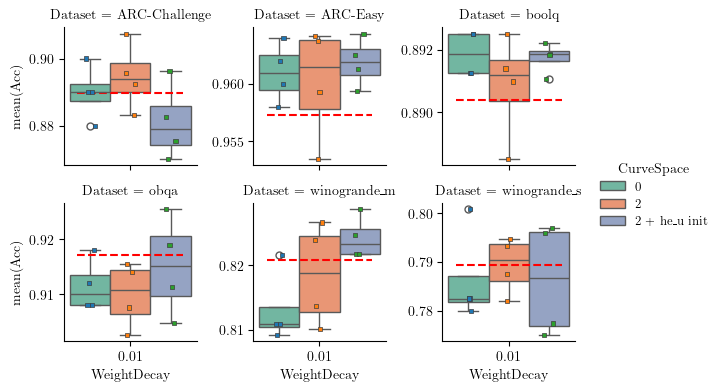

In [27]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]

# hue_order = df_clean['CurveSpace'].unique()
hue_order = ["0", "2", "2 + he_u init"]
g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

g.legend
# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From 

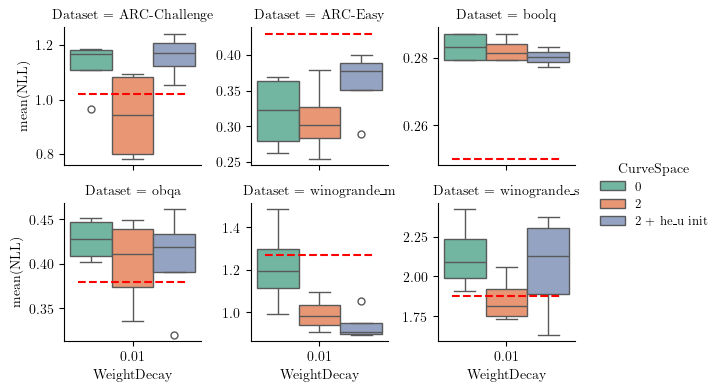

In [29]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### Wilcoxon Rank Sum Test (Independent Samples)


In [90]:
# load MLE base results
api = wandb.Api()
results = []
t_run = tqdm(api.runs(f"ddold/MLE-Qwen2.5-7B-all"))
t_run.set_description(s)
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    # drop runs with k>0 because of error in those runs
    res = dict(Id=run.id,
                CurveSpace=0,
                Seed=run.config['seed'],
                Dataset=run.config['dataset'],
                WeightDecay=0,
                acc=run.summary['final_val_acc'],
                nll=run.summary['final_val_nll'],
                ece=run.summary['final_val_ece'],
        )
    results.append(res)


df_base = pd.DataFrame(results)
df_base

# drop duplicates that share the same Seed, Dataset and WeightDecay (keep first)
_before = len(df_base)
df_base = df_base.drop_duplicates(subset=['Seed', 'Dataset', 'WeightDecay'], keep='first').reset_index(drop=True)
print(f"Dropped {_before - len(df_base)} duplicates, remaining {len(df_base)} rows")
df_base

47xexal3: 100%|██████████| 45/45 [00:00<00:00, 1889.42it/s, mle-boolq-seed3]

Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Dropped 2 duplicates, remaining 36 rows


,Id,CurveSpace,Seed,Dataset,WeightDecay,acc,nll,ece
0,o1dulwhl,0,6,winogrande_s,0,0.779272,2.031250,0.205545
1,wgxbatmk,0,2,winogrande_s,0,0.775316,2.500000,0.218704
2,4vjwwd1s,0,2,ARC-Challenge,0,0.898649,1.023438,0.104334
3,qo0agtmt,0,6,ARC-Challenge,0,0.898649,1.148438,0.100098
4,2ztl882y,0,6,ARC-Easy,0,0.954225,0.433594,0.042859
5,9k88c90n,0,2,ARC-Easy,0,0.955986,0.457031,0.039833
6,eu6ogm6l,0,2,winogrande_m,0,0.816456,1.203125,0.162480
7,tspr1v8i,0,6,winogrande_m,0,0.829114,1.132812,0.151753
8,5tvq7zdz,0,6,obqa,0,0.936000,0.341797,0.056758
9,ndeifnz9,0,2,obqa,0,0.932000,0.339844,0.055637


In [91]:
api = wandb.Api()
results = []
for s in ["47xexal3",]: # final MLE run
# for s in ["0nx704d3",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params']['k']>0:
            print(f"Skipping {run.name} because k>0")
            continue
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df_our = pd.DataFrame(results)
df_our

47xexal3:   0%|          | 0/72 [00:00<?, ?it/s, amber-sweep-63]  

47xexal3: 100%|██████████| 72/72 [00:00<00:00, 440.38it/s, earnest-sweep-1]   

Skipping rare-sweep-72 because k>0
Skipping whole-sweep-71 because k>0
Skipping helpful-sweep-70 because k>0
Skipping stoic-sweep-69 because k>0
Skipping good-sweep-68 because k>0
Skipping divine-sweep-67 because k>0
Skipping lemon-sweep-66 because k>0
Skipping summer-sweep-65 because k>0
Skipping snowy-sweep-64 because k>0
Skipping amber-sweep-63 because k>0
Skipping comic-sweep-62 because k>0
Skipping cerulean-sweep-61 because k>0
Skipping comic-sweep-60 because k>0
Skipping hearty-sweep-59 because k>0
Skipping honest-sweep-58 because k>0
Skipping logical-sweep-57 because k>0
Skipping serene-sweep-56 because k>0
Skipping playful-sweep-55 because k>0
Skipping different-sweep-54 because k>0
Skipping absurd-sweep-53 because k>0
Skipping crimson-sweep-52 because k>0
Skipping elated-sweep-51 because k>0
Skipping deft-sweep-50 because k>0
Skipping quiet-sweep-49 because k>0
Skipping autumn-sweep-48 because k>0
Skipping vague-sweep-47 because k>0
Skipping expert-sweep-46 because k>0
Skippin

,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,fqq9kub7,0,0,8,0,ARC-Easy,0,0.956000,0.956000,0.341797,0.341797
1,sg5qve6l,0,0,4,0,ARC-Easy,0,0.964000,0.964000,0.333984,0.333984
2,om8lcv5y,0,0,2,0,ARC-Easy,0,0.970000,0.970000,0.265625,0.265625
3,wgtt3t2r,0,0,1,0,ARC-Easy,0,0.960000,0.960000,0.316406,0.316406
4,lsipknn8,0,0,8,0,ARC-Challenge,0,0.890000,0.890000,1.148438,1.148438
5,lah4e9gh,0,0,4,0,ARC-Challenge,0,0.890000,0.890000,0.855469,0.855469
6,vyvzober,0,0,1,0,ARC-Challenge,0,0.875000,0.875000,1.179688,1.179688
7,xz9m5ysy,0,0,2,0,ARC-Challenge,0,0.875000,0.875000,1.359375,1.359375
8,wo6fc9x3,0,0,8,0,obqa,0,0.898000,0.898000,0.535156,0.535156
9,7w9ry1xx,0,0,4,0,obqa,0,0.914000,0.914000,0.361328,0.361328


#### Wilcoxon Rank Sum Test (Independent Samples)

Compare baseline (df_base) vs our method (df_our) per dataset using accuracy scores.

In [92]:
from scipy.stats import ranksums

# Prepare data for comparison
# df_base has 'acc' column, df_our has 'acc_mean' column
datasets = sorted(set(df_base['Dataset'].unique()) & set(df_our['Dataset'].unique()))

print("Wilcoxon Rank Sum Test (Mann-Whitney U test)")
print("=" * 70)
print(f"Comparing baseline vs our method per dataset")
print(f"H0: The two distributions are identical")
print(f"H1: The two distributions are different")
print("=" * 70)

results_wilcoxon = []

for dataset in datasets:
    # Get accuracy values for baseline (single model)
    base_acc = df_base[df_base['Dataset'] == dataset]['acc'].values
    
    # Get accuracy values for our method (mean of curve samples)
    our_acc = df_our[df_our['Dataset'] == dataset]['acc_mean'].values
    
    # Perform Wilcoxon rank sum test (independent samples)
    statistic, p_value = ranksums(base_acc, our_acc)
    
    # Calculate mean and std for both methods
    base_mean = base_acc.mean()
    base_std = base_acc.std()
    our_mean = our_acc.mean()
    our_std = our_acc.std()
    
    results_wilcoxon.append({
        'Dataset': dataset,
        'Base Mean': base_mean,
        'Base Std': base_std,
        'Our Mean': our_mean,
        'Our Std': our_std,
        'Statistic': statistic,
        'p-value': p_value,
        'Significant (α=0.05)': p_value < 0.05,
        'n_base': len(base_acc),
        'n_our': len(our_acc)
    })
    
    print(f"\n{dataset}:")
    print(f"  Baseline:   {base_mean:.4f} ± {base_std:.4f} (n={len(base_acc)})")
    print(f"  Our method: {our_mean:.4f} ± {our_std:.4f} (n={len(our_acc)})")
    print(f"  Statistic:  {statistic:.4f}")
    print(f"  p-value:    {p_value:.4f} {'***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'}")

df_wilcoxon = pd.DataFrame(results_wilcoxon)
print("\n" + "=" * 70)
print(f"Summary: {df_wilcoxon['Significant (α=0.05)'].sum()}/{len(df_wilcoxon)} datasets show significant differences")
df_wilcoxon

Wilcoxon Rank Sum Test (Mann-Whitney U test)
Comparing baseline vs our method per dataset
H0: The two distributions are identical
H1: The two distributions are different

ARC-Challenge:
  Baseline:   0.8947 ± 0.0041 (n=6)
  Our method: 0.8825 ± 0.0075 (n=4)
  Statistic:  2.1320
  p-value:    0.0330 *

ARC-Easy:
  Baseline:   0.9566 ± 0.0022 (n=6)
  Our method: 0.9625 ± 0.0052 (n=4)
  Statistic:  -2.1320
  p-value:    0.0330 *

boolq:
  Baseline:   0.8908 ± 0.0009 (n=6)
  Our method: 0.8907 ± 0.0011 (n=4)
  Statistic:  0.2132
  p-value:    0.8312 ns

obqa:
  Baseline:   0.9237 ± 0.0086 (n=6)
  Our method: 0.9090 ± 0.0064 (n=4)
  Statistic:  1.9188
  p-value:    0.0550 ns

winogrande_m:
  Baseline:   0.8212 ± 0.0077 (n=6)
  Our method: 0.8192 ± 0.0075 (n=4)
  Statistic:  0.4264
  p-value:    0.6698 ns

winogrande_s:
  Baseline:   0.7894 ± 0.0088 (n=6)
  Our method: 0.7923 ± 0.0017 (n=4)
  Statistic:  0.4264
  p-value:    0.6698 ns

Summary: 2/6 datasets show significant differences


,Dataset,Base Mean,Base Std,Our Mean,Our Std,Statistic,p-value,Significant (α=0.05),n_base,n_our
0,ARC-Challenge,0.894707,0.004099,0.882500,0.007500,2.132007,0.033006,True,6,4
1,ARC-Easy,0.956573,0.002196,0.962500,0.005172,-2.132007,0.033006,True,6,4
2,boolq,0.890810,0.000925,0.890703,0.001068,0.213201,0.831170,False,6,4
3,obqa,0.923667,0.008596,0.909000,0.006403,1.918806,0.055009,False,6,4
4,winogrande_m,0.821203,0.007725,0.819167,0.007477,0.426401,0.669815,False,6,4
5,winogrande_s,0.789425,0.008755,0.792292,0.001705,0.426401,0.669815,False,6,4


### longer training fixes and he_uniform init for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [30]:
api = wandb.Api()
results = []

for s in ["ev8m11oc",]: # short training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace= "{} + 5000steps".format(run.config['curve_params']['k']),
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

for s in ["b6404m0m",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace= run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

b6404m0m:   0%|          | 0/72 [00:00<?, ?it/s, smooth-sweep-33]  

b6404m0m: 100%|██████████| 72/72 [00:00<00:00, 439.92it/s, leafy-sweep-2]    

Skipping summer-sweep-72 because it is not finished
Skipping legendary-sweep-71 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,gao555jn,2 + 5000steps,0,7,0.01,ARC-Easy,24.752125,0.968000,0.964400,0.332031,0.400391
1,kb15144e,2 + 5000steps,0,6,0.01,ARC-Easy,24.604591,0.964000,0.961280,0.339844,0.371094
2,l0cwt44i,2 + 5000steps,0,4,0.01,ARC-Easy,24.714027,0.966000,0.959360,0.349609,0.384766
3,es0er688,2 + 5000steps,0,1,0.01,ARC-Easy,24.707684,0.966000,0.962560,0.251953,0.289062
4,z4rhdgc3,2 + 5000steps,0,7,0.01,obqa,25.048340,0.918000,0.911360,0.380859,0.414062
...,...,...,...,...,...,...,...,...,...,...,...
89,su5990ug,0,0,1,0.01,winogrande_s,0.000000,0.777500,0.777500,3.968750,3.968750
90,lmh3t1vr,0,0,7,0.01,winogrande_m,0.000000,0.826667,0.826667,2.203125,2.203125
91,jpx832y4,0,0,6,0.01,winogrande_m,0.000000,0.809167,0.809167,2.078125,2.078125
92,fhyjaheg,0,0,1,0.01,winogrande_m,0.000000,0.819167,0.819167,1.703125,1.703125


In [31]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [32]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['2 + 5000steps' 5 2 0]
Jitter [0]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'obqa' 'ARC-Challenge' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

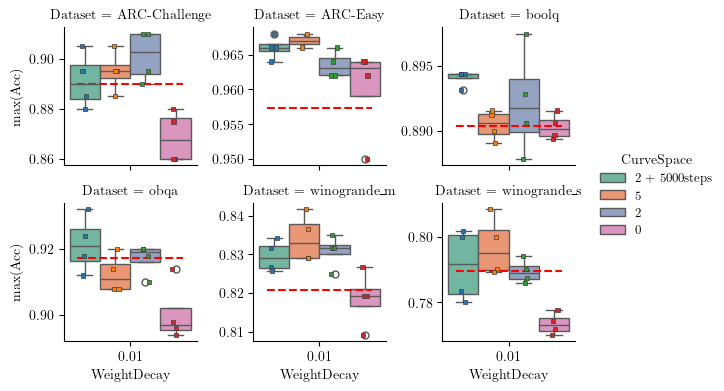

In [33]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

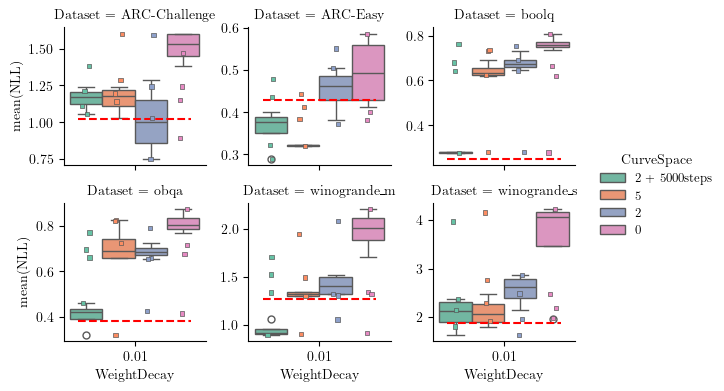

In [21]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### final MLE and MAP run
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [4]:
api = wandb.Api()
results = []

for s in ["47xexal3",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

for s in ["6w5rrxyg",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

47xexal3:   0%|          | 0/72 [00:00<?, ?it/s, amber-sweep-63]  

6w5rrxyg: 100%|██████████| 72/72 [00:00<00:00, 296.01it/s, serene-sweep-1]    


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
0,u8fznren,5,0,8,0.00,ARC-Easy,36.242317,0.968000,0.959200,0.281250,0.333984,0.039625,0.034137
1,0e86es3p,5,0,4,0.00,ARC-Easy,36.388222,0.962000,0.958080,0.271484,0.306641,0.039038,0.033875
2,cne60l0d,5,0,2,0.00,ARC-Easy,36.225174,0.966000,0.962080,0.275391,0.310547,0.037919,0.034375
3,38a7eclb,5,0,1,0.00,ARC-Easy,36.170921,0.964000,0.961120,0.332031,0.376953,0.037687,0.034937
4,m6ktmyb0,5,0,8,0.00,ARC-Challenge,36.590508,0.885000,0.876600,0.789062,0.886719,0.119162,0.112227
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,e1wyl9kn,0,0,2,0.01,winogrande_s,0.000000,0.778333,0.778333,2.609375,2.609375,0.219216,0.219216
140,s31mgf22,0,0,8,0.01,winogrande_m,0.000000,0.825000,0.825000,1.164062,1.164062,0.159974,0.159974
141,eyn3xg07,0,0,4,0.01,winogrande_m,0.000000,0.815833,0.815833,0.953125,0.953125,0.166989,0.166989
142,6l3sf16m,0,0,2,0.01,winogrande_m,0.000000,0.822500,0.822500,1.617188,1.617188,0.168984,0.168984


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['5' '2' '0']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_668004/514357132.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/514357132.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/514357132.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/514357132.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/514357132.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/514357132.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From 

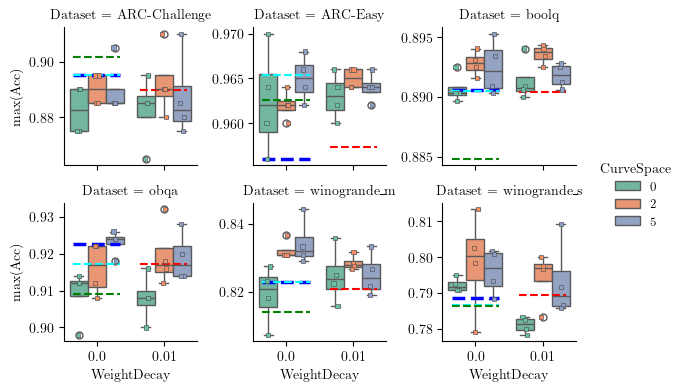

In [14]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['CurveSpace'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=2.5,
                label='MLE (WD=0)' if i == 0 else None
            )
            ax.hlines(
                y=ref_acc[dataset]['BLoB'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='cyan',
                linestyles='--',
                lw=1.5,
                label='BLoB' if i == 0 else None
            )
            ax.hlines(
                y=ref_acc[dataset]['ScalaBL'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='green',
                linestyles='--',
                lw=1.5,
                label='ScalaBL' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_668004/801798365.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/801798365.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/801798365.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/801798365.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/801798365.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/801798365.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From 

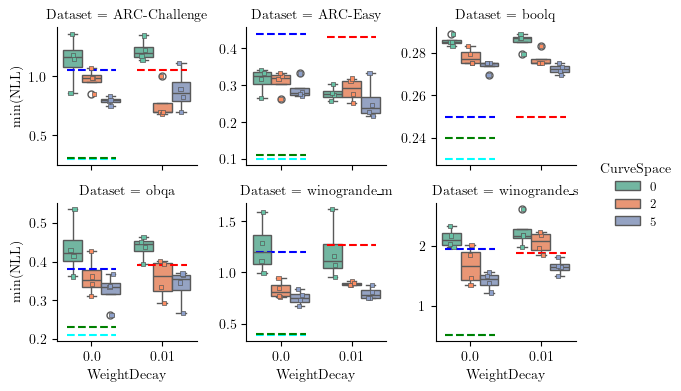

In [12]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
            ax.hlines(
                y=ref_nll[dataset]['BLoB'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='cyan',
                linestyles='--',
                lw=1.5,
                label='BLoB' if i == 0 else None
            )
            ax.hlines(
                y=ref_nll[dataset]['ScalaBL'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='green',
                linestyles='--',
                lw=1.5,
                label='ScalaBL' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_668004/2336808610.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/2336808610.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/2336808610.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/2336808610.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/2336808610.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/2336808610.py:17: FutureWarning: Use "auto" to set automatic grayscale colors.

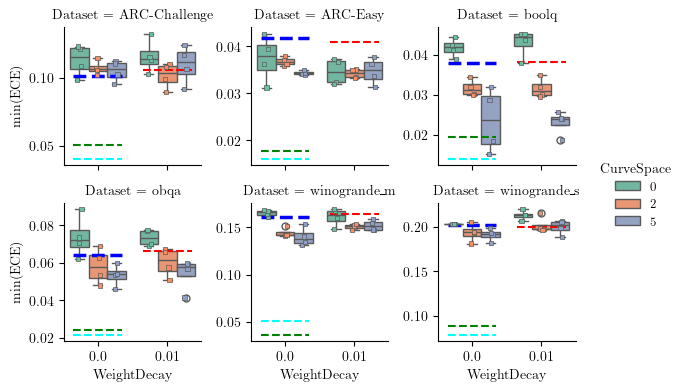

In [15]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_clean, x='WeightDecay', y='ece_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='ece_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(ECE)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_ece[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=2.5,
                label='MLE (WD=0)' if i == 0 else None
            )
            ax.hlines(
                y=ref_ece[dataset]['BLoB'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='cyan',
                linestyles='--',
                lw=1.5,
                label='BLoB' if i == 0 else None
            )
            ax.hlines(
                y=ref_ece[dataset]['ScalaBL'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='green',
                linestyles='--',
                lw=1.5,
                label='ScalaBL' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_ece[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### OOD runs

In [68]:
api = wandb.Api()
results = []

for s in ["ge0b0b5z",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

for s in ["ro920obt",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

ge0b0b5z:   0%|          | 0/48 [00:00<?, ?it/s, good-sweep-29]     

ro920obt: 100%|██████████| 48/48 [00:00<00:00, 349.96it/s, good-sweep-1]          


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
0,269mlk5g,5,0,8,0.00,ARC-Easy,0,0.956,0.94968,0.206055,0.223633,0.035600,0.029887
1,iguamb8f,5,0,4,0.00,ARC-Easy,0,0.954,0.94888,0.171875,0.200195,0.034092,0.026570
2,afxv707z,5,0,2,0.00,ARC-Easy,0,0.956,0.94776,0.199219,0.243164,0.039751,0.031516
3,ulnw7td1,5,0,1,0.00,ARC-Easy,0,0.958,0.95000,0.197266,0.208984,0.032545,0.025648
4,ulzy8kg8,5,0,8,0.00,ARC-Challenge,0,0.930,0.91880,0.357422,0.394531,0.065155,0.053652
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,4p8cfzf0,0,0,1,0.01,MMLU_chem,0,0.500,0.50000,1.617188,1.617188,0.280508,0.280508
92,efy2o6ih,0,0,8,0.01,MMLU_phy,0,0.520,0.52000,1.289062,1.289062,0.223398,0.223398
93,lqwpl83h,0,0,4,0.01,MMLU_phy,0,0.440,0.44000,1.289062,1.289062,0.251602,0.251602
94,jtcvlzdf,0,0,2,0.01,MMLU_phy,0,0.500,0.50000,1.367188,1.367188,0.182344,0.182344


In [69]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,,,


In [70]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['5' '2' '0']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'MMLU_chem' 'MMLU_phy']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'MMLU_chem', 'MMLU_phy'], dtype=object)

#### acc

/tmp/ipykernel_663478/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


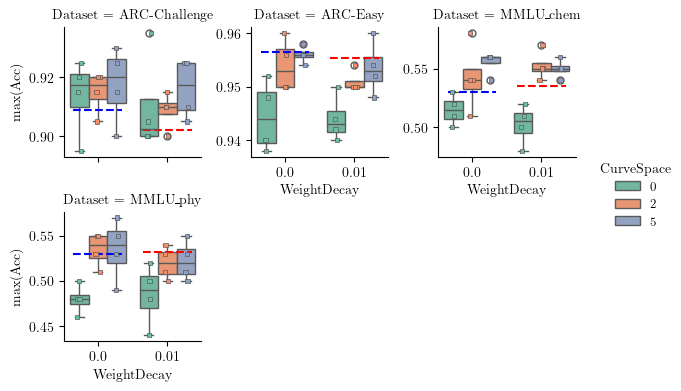

In [71]:
# Reference accuracy values from table 2
ref_acc_ood = {
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'ARC-Challenge': {'MLE': 90.88, 'MAP': 90.20},
    'ARC-Easy': {'MLE': 95.64, 'MAP': 95.53},
    'MMLU_chem': {'MLE': 53.00, 'MAP': 53.50},
    'MMLU_phy': {'MLE': 53.00, 'MAP': 53.25}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['CurveSpace'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc_ood:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc_ood[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc_ood[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_663478/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


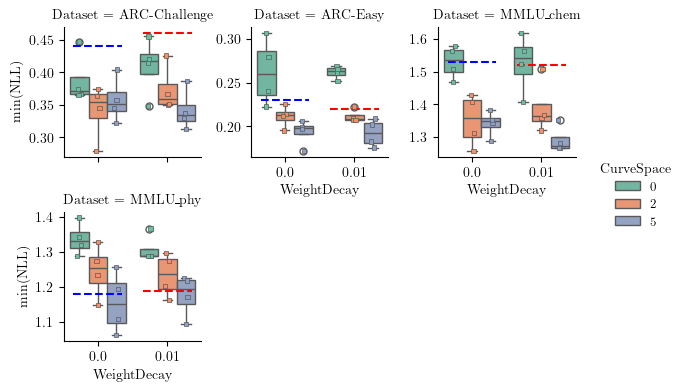

In [72]:
ref_nll_ood = {
    'obqa': {'MLE': 0.38, 'MAP': 0.39},
    'ARC-Challenge': {'MLE': 0.44, 'MAP': 0.46},
    'ARC-Easy': {'MLE': 0.23, 'MAP': 0.22},
    'MMLU_chem': {'MLE': 1.53, 'MAP': 1.52},
    'MMLU_phy': {'MLE': 1.18, 'MAP': 1.19}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll_ood:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll_ood[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll_ood[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_663478/3219309783.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3219309783.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3219309783.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3219309783.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


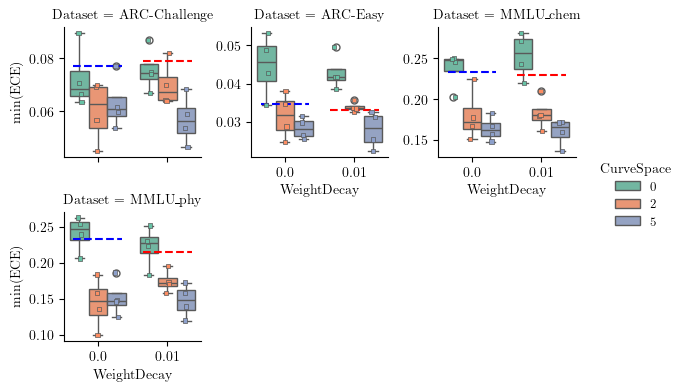

In [73]:
ref_ece_ood = {
    'obqa': {'MLE': 6.40, 'MAP': 6.61},
    'ARC-Challenge': {'MLE': 7.72, 'MAP': 7.89},
    'ARC-Easy': {'MLE': 3.48, 'MAP': 3.31},
    'MMLU_chem': {'MLE': 23.29, 'MAP': 22.90},
    'MMLU_phy': {'MLE': 23.22, 'MAP': 21.52}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='ece_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='ece_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(ECE)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece_ood:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y= ref_ece_ood[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y= ref_ece_ood[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### final MLE and MAP compare run with posterior predictive evaluation
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [87]:
api = wandb.Api()
results = []

# for s in ["m70skc3a",]: # MLE training 
#     t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
#     t_run.set_description(s)
#     for run in t_run:
#         if run.state != 'finished':
#             print(f"Skipping {run.name} because it is not finished")
#             continue
#         t_run.set_postfix_str(run.name)
#         res = dict(Id=run.id,
#                     CurveSpace=f"{run.config['curve_params']['k']}",
#                     Jitter=run.config['curve_params']['jitter_multiplier'],
#                     Seed=run.config['rng_seed'],
#                     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
#                     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
#                     bezierLength=run.summary.get('Curve length', 0),
#                     acc_max=run.summary['final_acc_max'],
#                     acc_mean=run.summary['final_acc_mean'],
#                     nll_min=run.summary['final_loss_min'],
#                     nll_mean=run.summary['final_loss_mean'],
#                     ece_mean=run.summary['final_ece_mean'],
#                     ece_min=run.summary['final_ece_min'],
#                     acc_ppd=run.summary.get('post_pred_acc_t1', 0),
#                     ece_ppD=run.summary.get('post_pred_ece_t1', 0),
#                     ll_ppD=run.summary.get('post_predictive_t1', 0),
#             )
#         results.append(res)

for s in ["m70skc3a",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    PPD="ppd_t1",
                    acc=run.summary.get('post_pred_acc_t1', 0),
                    ece=run.summary.get('post_pred_ece_t1', 0),
                    nll=-run.summary.get('post_predictive_t1', 0),
            )
        results.append(res)

        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    PPD="ppd_t8",
                    acc=run.summary.get('post_pred_acc_t8', 0),
                    ece=run.summary.get('post_pred_ece_t8', 0),
                    nll=-run.summary.get('post_predictive_t8', 0),
            )
        results.append(res)

        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    PPD="classic",
                    acc=run.summary.get('final_acc_mean', 0),
                    ece=run.summary.get('final_ece_mean', 0),
                    nll=run.summary.get('final_loss_mean', 0),
            )
        results.append(res)

# for s in ["6w5rrxyg",]: # MAP training
#     t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
#     t_run.set_description(s)
#     for run in t_run:
#         if run.state != 'finished':
#             print(f"Skipping {run.name} because it is not finished")
#             continue
#         t_run.set_postfix_str(run.name)
#         res = dict(Id=run.id,
#                     CurveSpace=f"{run.config['curve_params']['k']}",
#                     Jitter=run.config['curve_params']['jitter_multiplier'],
#                     Seed=run.config['rng_seed'],
#                     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
#                     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
#                     bezierLength=run.summary.get('Curve length', 0),
#                     acc_max=run.summary['final_acc_max'],
#                     acc_mean=run.summary['final_acc_mean'],
#                     nll_min=run.summary['final_loss_min'],
#                     nll_mean=run.summary['final_loss_mean'],
#                     ece_mean=run.summary['final_ece_mean'],
#                     ece_min=run.summary['final_ece_min'],
#             )
#         results.append(res)

df = pd.DataFrame(results)
df

m70skc3a:   0%|          | 0/53 [00:00<?, ?it/s, zesty-sweep-14]    

m70skc3a: 100%|██████████| 53/53 [00:00<00:00, 343.87it/s, devoted-sweep-1]  

Skipping stoic-sweep-53 because it is not finished
Skipping fast-sweep-52 because it is not finished
Skipping golden-sweep-51 because it is not finished
Skipping graceful-sweep-50 because it is not finished
Skipping solar-sweep-49 because it is not finished
Skipping treasured-sweep-48 because it is not finished
Skipping rosy-sweep-47 because it is not finished
Skipping worthy-sweep-38 because it is not finished
Skipping snowy-sweep-40 because it is not finished
Skipping sandy-sweep-37 because it is not finished
Skipping different-sweep-36 because it is not finished
Skipping zany-sweep-35 because it is not finished
Skipping avid-sweep-34 because it is not finished
Skipping vocal-sweep-33 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,PPD,acc,ece,nll
0,eegxpv00,2,0,2,0,ARC-Easy,24.745190,ppd_t1,0.964000,0.033855,0.340606
1,eegxpv00,2,0,2,0,ARC-Easy,24.745190,ppd_t8,0.964000,0.033855,0.340606
2,eegxpv00,2,0,2,0,ARC-Easy,24.745190,classic,0.962440,0.034913,0.340605
3,oe79hwp5,2,0,1,0,ARC-Easy,24.765524,ppd_t1,0.956000,0.038451,0.373562
4,oe79hwp5,2,0,1,0,ARC-Easy,24.765524,ppd_t8,0.956000,0.038451,0.373561
...,...,...,...,...,...,...,...,...,...,...,...
112,wzqc417x,0,0,2,0,winogrande_m,0.000000,ppd_t8,0.814167,0.177304,1.507686
113,wzqc417x,0,0,2,0,winogrande_m,0.000000,classic,0.814167,0.177304,1.507686
114,vryop8xa,0,0,1,0,winogrande_m,0.000000,ppd_t1,0.820833,0.166621,1.738095
115,vryop8xa,0,0,1,0,winogrande_m,0.000000,ppd_t8,0.820833,0.166621,1.738095


In [88]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,bezierLength,acc,ece,nll
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,PPD,,,,


In [89]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['2' '0']
Jitter [0]
Seed [2 1 8 4]
WeightDecay [0]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m' 'boolq']
PPD ['ppd_t1' 'ppd_t8' 'classic']

Experiment differs in ['CurveSpace', 'Dataset', 'PPD'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_663478/1367484382.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1367484382.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1367484382.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1367484382.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1367484382.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1367484382.py:23: FutureWarning: Use "auto" to set automatic grayscale colors.

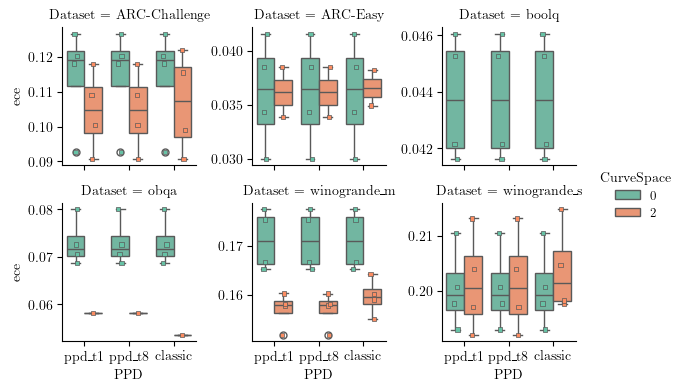

In [90]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['CurveSpace'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]

metric, label_name = 'nll', 'nll'
metric, label_name = 'ece', 'ece'

g = sns.catplot(data=df_clean, x='PPD', y=metric, hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='PPD',
        y=metric,
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels(label_name)


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# # Draw horizontal reference lines
# for ax in g.axes.flatten():
#     # Each subplot’s dataset name from its title
#     dataset = ax.get_title().split('=')[1].strip()
#     if dataset not in ref_acc:
#         continue

#     # Get current axis limits for scaling line width
#     for i, wd in enumerate(weight_levels):
#         tick = i  # categorical position
#         if wd == 0:
#             ax.hlines(
#                 y=ref_acc[dataset]['MLE'] / 100,
#                 xmin=tick - 0.35,
#                 xmax=tick + 0.35,
#                 colors='blue',
#                 linestyles='--',
#                 lw=1.5,
#                 label='MLE (WD=0)' if i == 0 else None
#             )
#         elif wd == 0.01:
#             ax.hlines(
#                 y=ref_acc[dataset]['MAP'] / 100,
#                 xmin=tick - 0.35,
#                 xmax=tick + 0.35,
#                 colors='red',
#                 linestyles='--',
#                 lw=1.5,
#                 label='MAP (WD=0.01)' if i == 0 else None
#             )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_663478/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

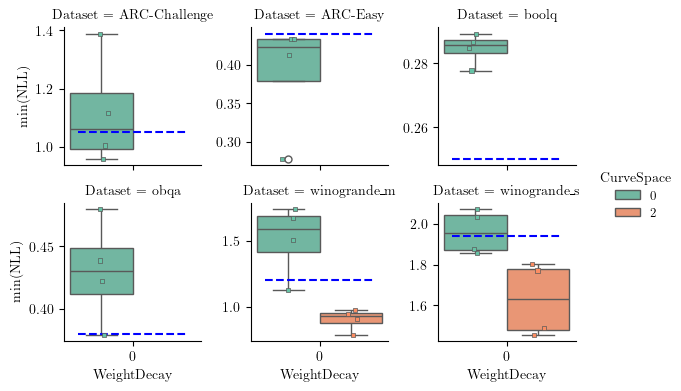

In [7]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_663478/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_663478/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

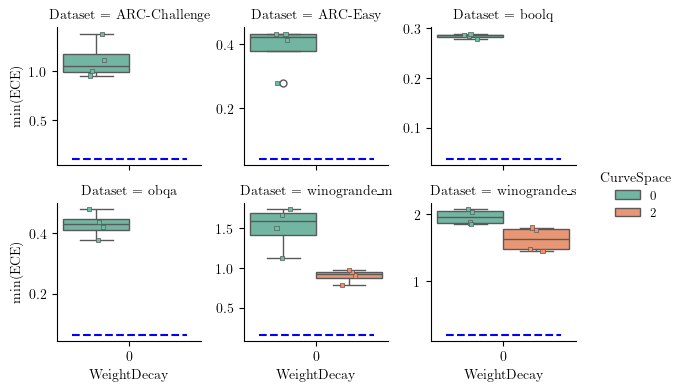

In [8]:
ref_ece = {
    'boolq': {'MLE': 3.79, 'MAP': 3.81},
    'ARC-Easy': {'MLE': 4.17, 'MAP': 4.08},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54},
    'obqa': {'MLE': 6.40, 'MAP': 6.61},
    'winogrande_s': {'MLE': 20.14, 'MAP': 19.99},
    'winogrande_m': {'MLE': 16.10, 'MAP': 16.42},
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(ECE)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_ece[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_ece[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### final MLE and MAP run with posterior predictive evaluation
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [37]:
api = wandb.Api()
results = []

for s in ["m70skc3a",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        for metric in ['best', 'mean', 'ppd']:
        # for metric in [['final_loss_min', 'final_loss_mean', 'post_predictive_t1'], ['final_ece_min', 'final_ece_mean', 'post_pred_ece_t1'], ['final_acc_max', 'final_acc_mean', 'post_pred_acc_t1']]:
            res = dict(Id=run.id,
                    #    CurveSpace=f"{run.config['curve_params']['k']}",
                       CurveSpace=run.config['curve_params']['k'],
                       Jitter=run.config['curve_params']['jitter_multiplier'],
                       Seed=run.config['rng_seed'],
                       WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                       Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                       Metric=metric,
                       bezierLength=run.summary.get('Curve length', 0),
                       acc=run.summary.get(f"final_acc_{'max' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_acc_t1', 0),
                       ece=run.summary.get(f"final_ece_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_ece_t1', 0),
                       nll=run.summary.get(f"final_loss_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else -run.summary.get('post_predictive_t1', 0),
                )
            results.append(res)
        # res = dict(Id=run.id,
        #             CurveSpace=f"{run.config['curve_params']['k']}",
        #             Jitter=run.config['curve_params']['jitter_multiplier'],
        #             Seed=run.config['rng_seed'],
        #             WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #             Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #             bezierLength=run.summary.get('Curve length', 0),
        #             acc_max=run.summary['final_acc_max'],
        #             acc_mean=run.summary['final_acc_mean'],
        #             nll_min=run.summary['final_loss_min'],
        #             nll_mean=run.summary['final_loss_mean'],
        #             ece_mean=run.summary['final_ece_mean'],
        #             ece_min=run.summary['final_ece_min'],
        #             acc_ppd=run.summary.get('post_pred_acc_t1', 0),
        #             ece_ppd=run.summary.get('post_pred_ece_t1', 0),
        #             nll_ppd=-run.summary.get('post_predictive_t1', 0),
        #     )
        # results.append(res)

for s in ["lsk1cols",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        for metric in ['best', 'mean', 'ppd']:
        # for metric in [['final_loss_min', 'final_loss_mean', 'post_predictive_t1'], ['final_ece_min', 'final_ece_mean', 'post_pred_ece_t1'], ['final_acc_max', 'final_acc_mean', 'post_pred_acc_t1']]:
            res = dict(Id=run.id,
                    #    CurveSpace=f"{run.config['curve_params']['k']}",
                       CurveSpace=run.config['curve_params']['k'],
                       Jitter=run.config['curve_params']['jitter_multiplier'],
                       Seed=run.config['rng_seed'],
                       WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                       Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                       Metric=metric,
                       bezierLength=run.summary.get('Curve length', 0),
                       acc=run.summary.get(f"final_acc_{'max' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_acc_t1', 0),
                       ece=run.summary.get(f"final_ece_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_ece_t1', 0),
                       nll=run.summary.get(f"final_loss_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else -run.summary.get('post_predictive_t1', 0),
                )
            results.append(res)

df = pd.DataFrame(results)
df

m70skc3a:   0%|          | 0/72 [00:00<?, ?it/s, jumping-sweep-42]      

lsk1cols: 100%|██████████| 46/46 [00:00<00:00, 434.57it/s, effortless-sweep-1]


Skipping distinctive-sweep-46 because it is not finished
Skipping fiery-sweep-36 because it is not finished
Skipping stoic-sweep-35 because it is not finished
Skipping flowing-sweep-34 because it is not finished
Skipping splendid-sweep-33 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,bezierLength,acc,ece,nll
0,h97far1q,5,0,8,0.00,ARC-Easy,best,36.150993,0.954000,0.044906,0.355241
1,h97far1q,5,0,8,0.00,ARC-Easy,mean,36.150993,0.951000,0.047323,0.392678
2,h97far1q,5,0,8,0.00,ARC-Easy,ppd,36.150993,0.950000,0.047389,0.392675
3,tx1ho7n4,5,0,4,0.00,ARC-Easy,best,36.344273,0.966000,0.031404,0.251899
4,tx1ho7n4,5,0,4,0.00,ARC-Easy,mean,36.344273,0.961920,0.036065,0.317097
...,...,...,...,...,...,...,...,...,...,...,...
334,orbb2gs5,0,0,2,0.01,winogrande_m,mean,0.000000,0.816667,0.167639,1.308466
335,orbb2gs5,0,0,2,0.01,winogrande_m,ppd,0.000000,0.816667,0.167639,1.308466
336,herrg8yj,0,0,1,0.01,winogrande_m,best,0.000000,0.833333,0.150122,1.093719
337,herrg8yj,0,0,1,0.01,winogrande_m,mean,0.000000,0.833333,0.150122,1.093719


In [38]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,bezierLength,acc,ece,nll
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,,,,


In [39]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [5 2 0]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']
Metric ['best' 'mean' 'ppd']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset', 'Metric'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

In [40]:
df_clean = df_clean[df_clean['WeightDecay']==0]

/tmp/ipykernel_668004/1578625108.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/1578625108.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/1578625108.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/1578625108.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/1578625108.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/1578625108.py:22: FutureWarning: Use "auto" to set automatic grayscale colors.

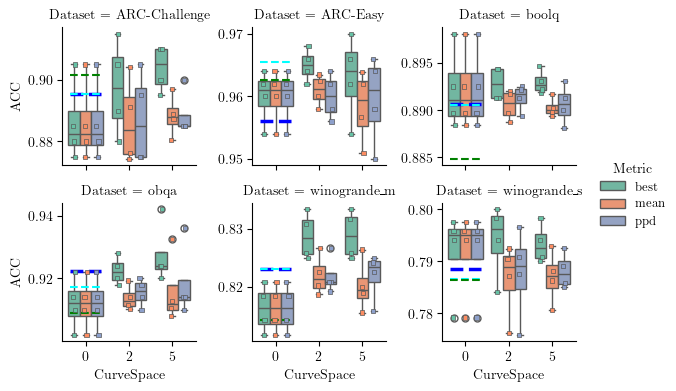

In [42]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['Metric'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='CurveSpace', y='acc', hue='Metric', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='Metric',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=2.5,
                label='MLE (WD=0)' if i == 0 else None
            )
            ax.hlines(
                y=ref_acc[dataset]['BLoB'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='cyan',
                linestyles='--',
                lw=1.5,
                label='BLoB' if i == 0 else None
            )
            ax.hlines(
                y=ref_acc[dataset]['ScalaBL'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='green',
                linestyles='--',
                lw=1.5,
                label='ScalaBL' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_668004/3842599304.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/3842599304.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/3842599304.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/3842599304.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/3842599304.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/3842599304.py:22: FutureWarning: Use "auto" to set automatic grayscale colors.

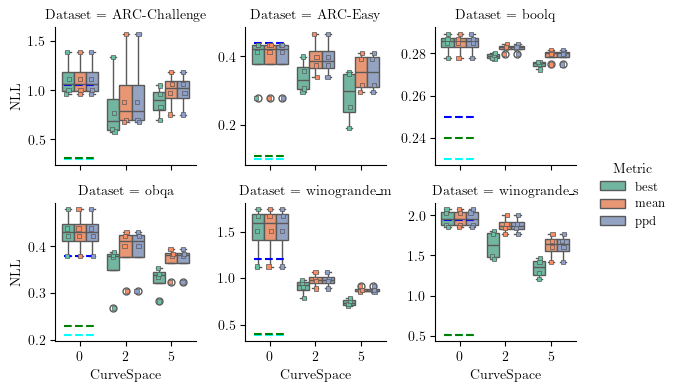

In [48]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_clean, x='CurveSpace', y='nll', hue='Metric', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='Metric',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
            ax.hlines(
                y=ref_nll[dataset]['BLoB'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='cyan',
                linestyles='--',
                lw=1.5,
                label='BLoB' if i == 0 else None
            )
            ax.hlines(
                y=ref_nll[dataset]['ScalaBL'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='green',
                linestyles='--',
                lw=1.5,
                label='ScalaBL' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_668004/323242849.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/323242849.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/323242849.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/323242849.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/323242849.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_668004/323242849.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From 

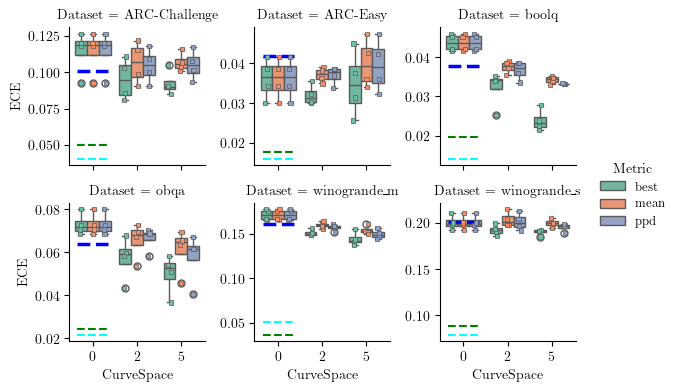

In [47]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_clean, x='CurveSpace', y='ece', hue='Metric', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='Metric',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_ece[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=2.5,
                label='MLE (WD=0)' if i == 0 else None
            )
            ax.hlines(
                y=ref_ece[dataset]['BLoB'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='cyan',
                linestyles='--',
                lw=1.5,
                label='BLoB' if i == 0 else None
            )
            ax.hlines(
                y=ref_ece[dataset]['ScalaBL'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='green',
                linestyles='--',
                lw=1.5,
                label='ScalaBL' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_ece[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### MAP with t conditioned dataset sampling


In [40]:
api = wandb.Api()
results = []

for s in ["l114jgfz",]: # MAP training with dataset sampled according t
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        for metric in ['best', 'mean', 'ppd']:
        # for metric in [['final_loss_min', 'final_loss_mean', 'post_predictive_t1'], ['final_ece_min', 'final_ece_mean', 'post_pred_ece_t1'], ['final_acc_max', 'final_acc_mean', 'post_pred_acc_t1']]:
            res = dict(Id=run.id,
                       CurveSpace=f"k={run.config['curve_params']['k']} ds~t",
                    #    CurveSpace=run.config['curve_params']['k'],
                       Jitter=run.config['curve_params']['jitter_multiplier'],
                       Seed=run.config['rng_seed'],
                       WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                       Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                       Metric=metric,
                       bezierLength=run.summary.get('Curve length', 0),
                       acc=run.summary.get(f"final_acc_{'max' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_acc_t1', 0),
                       ece=run.summary.get(f"final_ece_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_ece_t1', 0),
                       nll=run.summary.get(f"final_loss_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else -run.summary.get('post_predictive_t1', 0),
                )
            results.append(res)

for s in ["lsk1cols",]: # MAP training original optimisation
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        for metric in ['best', 'mean', 'ppd']:
        # for metric in [['final_loss_min', 'final_loss_mean', 'post_predictive_t1'], ['final_ece_min', 'final_ece_mean', 'post_pred_ece_t1'], ['final_acc_max', 'final_acc_mean', 'post_pred_acc_t1']]:
            res = dict(Id=run.id,
                       CurveSpace=f"k={run.config['curve_params']['k']}",
                    #    CurveSpace=run.config['curve_params']['k'],
                       Jitter=run.config['curve_params']['jitter_multiplier'],
                       Seed=run.config['rng_seed'],
                       WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                       Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                       Metric=metric,
                       bezierLength=run.summary.get('Curve length', 0),
                       acc=run.summary.get(f"final_acc_{'max' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_acc_t1', 0),
                       ece=run.summary.get(f"final_ece_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else run.summary.get('post_pred_ece_t1', 0),
                       nll=run.summary.get(f"final_loss_{'min' if metric == 'best' else metric}", 0) if metric != 'ppd' else -run.summary.get('post_predictive_t1', 0),
                )
            results.append(res)

df = pd.DataFrame(results)
df

l114jgfz:   0%|          | 0/48 [00:00<?, ?it/s, comfy-sweep-31]      

l114jgfz: 100%|██████████| 48/48 [00:00<00:00, 328.63it/s, deep-sweep-1]      


Skipping honest-sweep-37 because it is not finished
Skipping legendary-sweep-36 because it is not finished
Skipping fiery-sweep-35 because it is not finished
Skipping twilight-sweep-34 because it is not finished
Skipping swept-sweep-33 because it is not finished


lsk1cols: 100%|██████████| 72/72 [00:00<00:00, 394.82it/s, effortless-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,bezierLength,acc,ece,nll
0,fth5dpu3,k=5 ds~t,0,8,0.01,ARC-Easy,best,36.527493,0.966000,0.031960,0.244631
1,fth5dpu3,k=5 ds~t,0,8,0.01,ARC-Easy,mean,36.527493,0.958640,0.037483,0.279075
2,fth5dpu3,k=5 ds~t,0,8,0.01,ARC-Easy,ppd,36.527493,0.958000,0.037154,0.279247
3,1nsnstz0,k=5 ds~t,0,4,0.01,ARC-Easy,best,36.619209,0.960000,0.037653,0.289436
4,1nsnstz0,k=5 ds~t,0,4,0.01,ARC-Easy,mean,36.619209,0.954480,0.042608,0.334265
...,...,...,...,...,...,...,...,...,...,...,...
340,orbb2gs5,k=0,0,2,0.01,winogrande_m,mean,0.000000,0.816667,0.167639,1.308466
341,orbb2gs5,k=0,0,2,0.01,winogrande_m,ppd,0.000000,0.816667,0.167639,1.308466
342,herrg8yj,k=0,0,1,0.01,winogrande_m,best,0.000000,0.833333,0.150122,1.093719
343,herrg8yj,k=0,0,1,0.01,winogrande_m,mean,0.000000,0.833333,0.150122,1.093719


In [41]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,bezierLength,acc,ece,nll
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,,,,


In [42]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['k=5 ds~t' 'k=2 ds~t' 'k=5' 'k=2' 'k=0']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m' 'boolq']
Metric ['best' 'mean' 'ppd']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

In [43]:
order = df_clean['CurveSpace'].unique()
order.sort()
order

array(['k=0', 'k=2', 'k=2 ds~t', 'k=5', 'k=5 ds~t'], dtype=object)

/tmp/ipykernel_744989/583893034.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/583893034.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/583893034.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/583893034.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/583893034.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/583893034.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From 

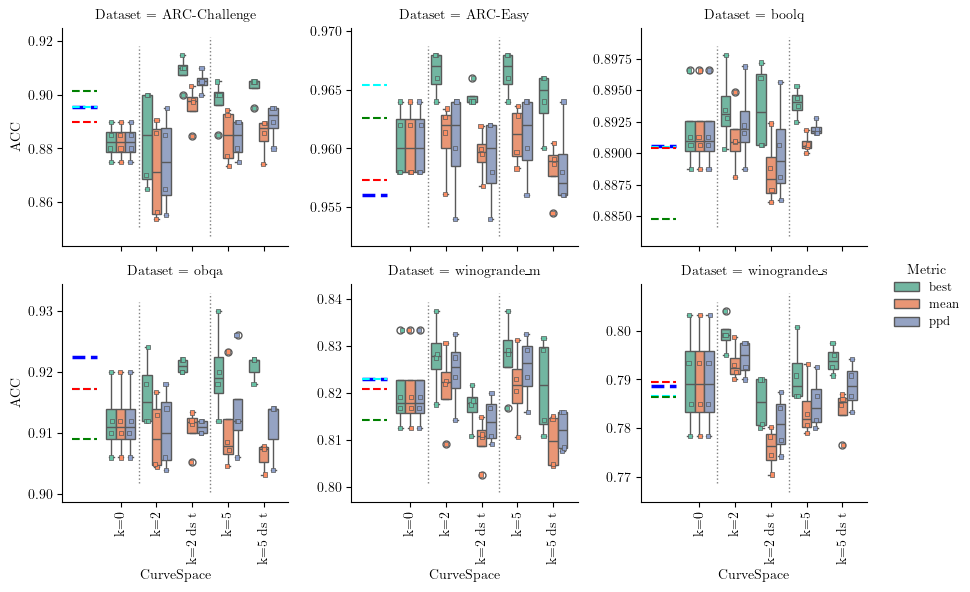

In [48]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['Metric'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='CurveSpace', y='acc', hue='Metric', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1]*1.5, col_order=col_order, hue_order=hue_order, order=order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='Metric',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    # for i, wd in enumerate(weight_levels):
    tick = -1  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)' if i == 0 else None
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB' if i == 0 else None
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL' if i == 0 else None
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)' if i == 0 else None
    )
    tick = 0
    ax.vlines(
        x=tick + 0.5,
        ymin=ax.get_ylim()[0],
        ymax=ax.get_ylim()[1],
        colors='gray',
        linestyles=':',
        lw=1.0,
    )
    tick = 2
    ax.vlines(
        x=tick + 0.5,
        ymin=ax.get_ylim()[0],
        ymax=ax.get_ylim()[1],
        colors='gray',
        linestyles=':',
        lw=1.0,
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90)
[plt.setp(ax.get_xticklabels(), rotation=90) for ax in g.axes.flat]
g.tight_layout()



/tmp/ipykernel_744989/568702551.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/568702551.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/568702551.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/568702551.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/568702551.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/568702551.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From 

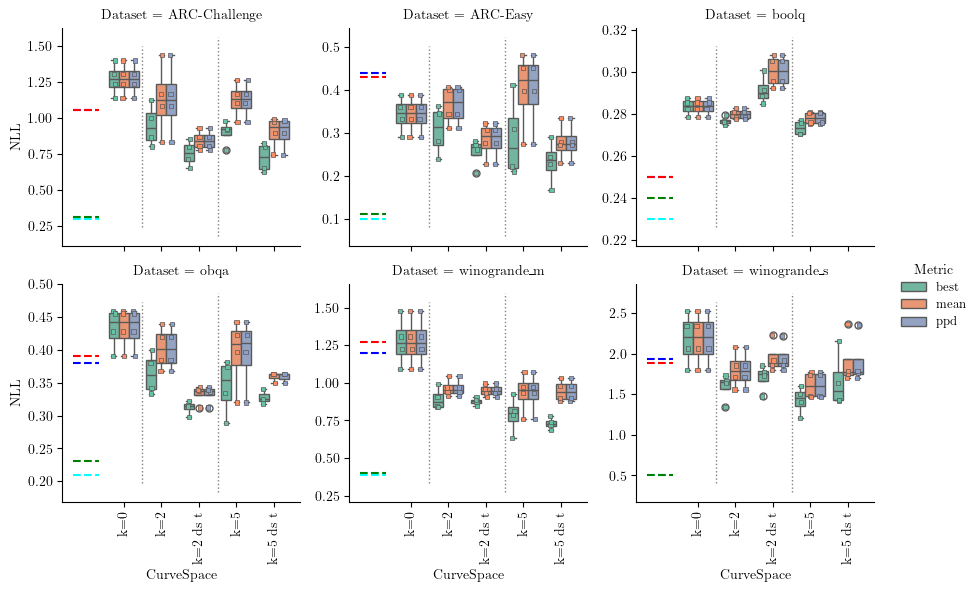

In [49]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_clean, x='CurveSpace', y='nll', hue='Metric', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1]*1.5, col_order=col_order, hue_order=hue_order, order=order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='Metric',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    
    tick = -1  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='blue',
        linestyles='--',
        lw=1.5,
        label='MLE (WD=0)' if i == 0 else None
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB' if i == 0 else None
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL' if i == 0 else None
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)' if i == 0 else None
    )
    tick = 0
    ax.vlines(
        x=tick + 0.5,
        ymin=ax.get_ylim()[0],
        ymax=ax.get_ylim()[1],
        colors='gray',
        linestyles=':',
        lw=1.0,
    )
    tick = 2
    ax.vlines(
        x=tick + 0.5,
        ymin=ax.get_ylim()[0],
        ymax=ax.get_ylim()[1],
        colors='gray',
        linestyles=':',
        lw=1.0,
    )

# Adjust legend placement if needed

[plt.setp(ax.get_xticklabels(), rotation=90) for ax in g.axes.flat]
g.tight_layout()

/tmp/ipykernel_744989/472862577.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/472862577.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/472862577.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/472862577.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/472862577.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_744989/472862577.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From 

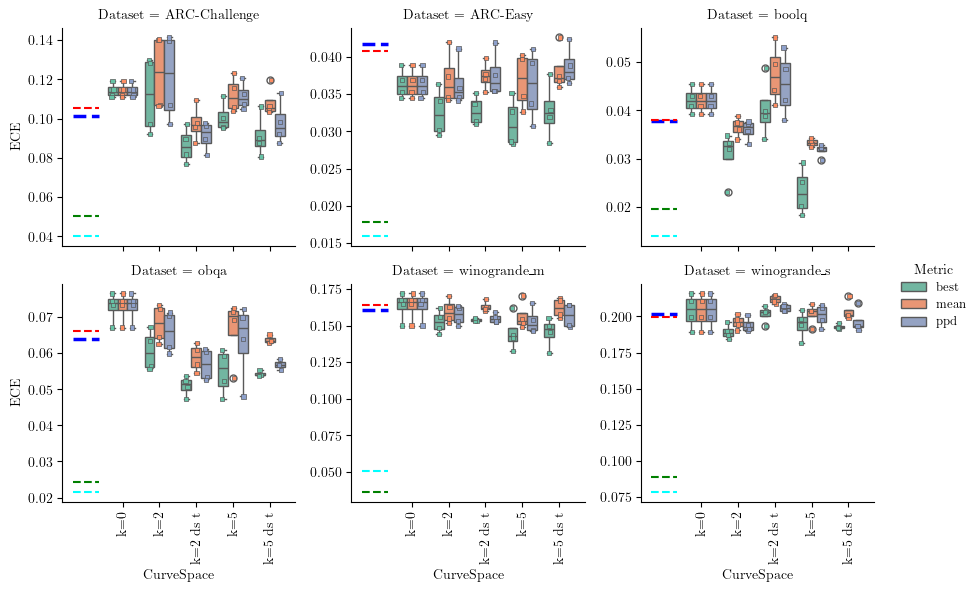

In [46]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_clean, x='CurveSpace', y='ece', hue='Metric', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1]*1.5, col_order=col_order, hue_order=hue_order, order=order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='Metric',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    # Get current axis limits for scaling line width
    tick = -1  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)' if i == 0 else None
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB' if i == 0 else None
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL' if i == 0 else None
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.35,
        xmax=tick + 0.35,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)' if i == 0 else None
    )

# Adjust legend placement if needed

[plt.setp(ax.get_xticklabels(), rotation=90) for ax in g.axes.flat]
g.tight_layout()

### MAP run with fixed posterior predictive evaluation
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

BMA with adding log weightes instead of multiplying weights in log space 

In [56]:
api = wandb.Api()
results = []

for s in ["00r8grro",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            )
        results.append(res)


for s in ["lsk1cols",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            LoraMode=run.config['lora_params'].get('lora_mode', 'old_A(t)B'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_acc_t1", 0),
            ece=run.summary.get(f"post_pred_ece_t1", 0),
            nll=-run.summary.get(f"post_predictive_ll_t1", 0),
            )
        results.append(res)

df = pd.DataFrame(results)
df

00r8grro:   0%|          | 0/144 [00:00<?, ?it/s, good-sweep-135]   

lsk1cols: 100%|██████████| 72/72 [00:00<00:00, 391.53it/s, effortless-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,LoraMode,bezierLength,acc,ece,nll
0,znukz4d6,5,0,8,0.01,ARC-Easy,ppd,As(t)B,24.323837,0.964000,0.034607,0.236196
1,znukz4d6,5,0,8,0.01,ARC-Easy,mean,As(t)B,24.323837,0.964000,0.034607,0.236196
2,w1f951yj,5,0,4,0.01,ARC-Easy,ppd,As(t)B,24.375652,0.956000,0.040312,0.322731
3,w1f951yj,5,0,4,0.01,ARC-Easy,mean,As(t)B,24.375652,0.956000,0.040312,0.322731
4,xmxd1p6z,5,0,2,0.01,ARC-Easy,ppd,As(t)B,24.442505,0.960000,0.040863,0.360060
...,...,...,...,...,...,...,...,...,...,...,...,...
355,1lrxuiy1,0,0,1,0.01,winogrande_s,ppd,old_A(t)B,0.000000,0.778333,0.215898,2.339517
356,p581p2n3,0,0,8,0.01,winogrande_m,ppd,old_A(t)B,0.000000,0.812500,0.172102,1.479925
357,vmtj4mog,0,0,4,0.01,winogrande_m,ppd,old_A(t)B,0.000000,0.819167,0.164813,1.223713
358,orbb2gs5,0,0,2,0.01,winogrande_m,ppd,old_A(t)B,0.000000,0.816667,0.167639,1.308467


In [57]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,bezierLength,acc,ece,nll
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,LoraMode,,,,


In [58]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [5 2 0]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']
Metric ['ppd' 'mean']
LoraMode ['As(t)B' 'A(t)B(t)' 'A(t)B' 'old_A(t)B']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'LoraMode'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

In [59]:
df_clean = df_clean[df_clean['Metric']=='ppd']

/tmp/ipykernel_783425/2253083177.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/2253083177.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/2253083177.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/2253083177.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/2253083177.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/2253083177.py:22: FutureWarning: Use "auto" to set automatic grayscale colors.

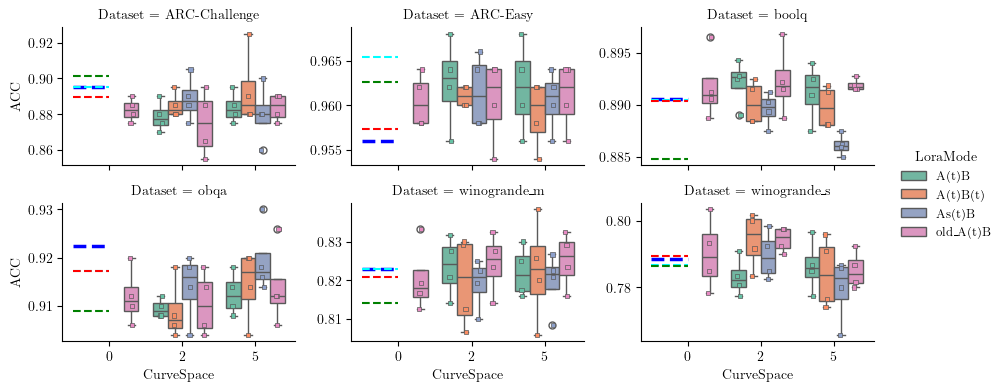

In [60]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['LoraMode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='CurveSpace', y='acc', hue='LoraMode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.25  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)' if i == 0 else None
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB' if i == 0 else None
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL' if i == 0 else None
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)' if i == 0 else None
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_783425/1365542933.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/1365542933.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/1365542933.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/1365542933.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/1365542933.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/1365542933.py:22: FutureWarning: Use "auto" to set automatic grayscale colors.

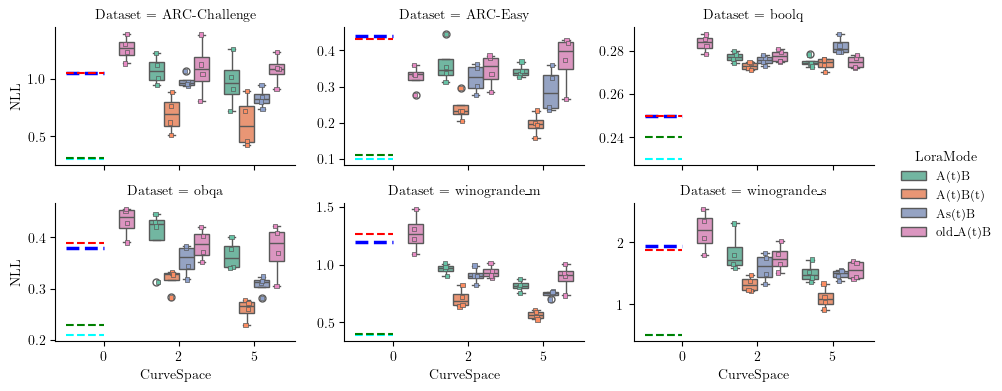

In [61]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_clean, x='CurveSpace', y='nll', hue='LoraMode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.25  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)' if i == 0 else None
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB' if i == 0 else None
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL' if i == 0 else None
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)' if i == 0 else None
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_783425/3102234735.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/3102234735.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/3102234735.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/3102234735.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/3102234735.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_783425/3102234735.py:17: FutureWarning: Use "auto" to set automatic grayscale colors.

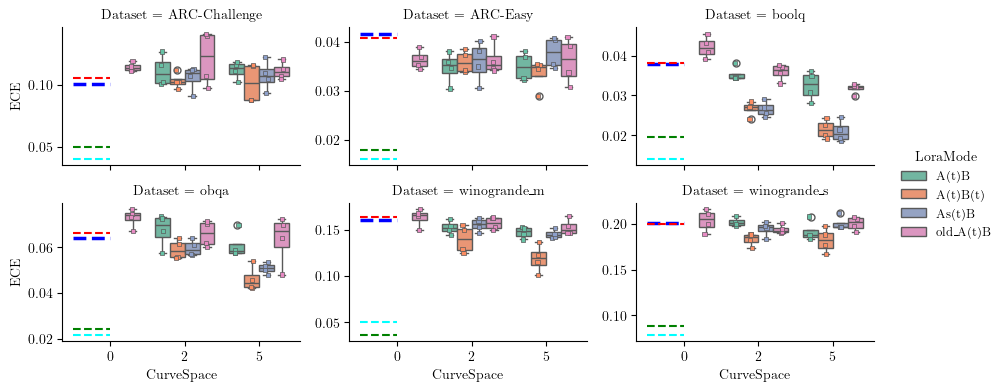

In [62]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_clean, x='CurveSpace', y='ece', hue='LoraMode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.25  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)' if i == 0 else None
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB' if i == 0 else None
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL' if i == 0 else None
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)' if i == 0 else None
    )

# Adjust legend placement if needed
g.tight_layout()

### Expert MAP run with fixed posterior predictive evaluation and t dependet dataset samplinge
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

BMA with adding log weightes instead of multiplying weights in log space 

In [3]:
api = wandb.Api()
results = []

for s in ["b9cz8xsa",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            )
        results.append(res)


for s in ["00r8grro",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'mini_batch': None}).keys())[0],
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'mini_batch': None}).keys())[0],
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            )
        results.append(res)


df = pd.DataFrame(results)
df

b9cz8xsa:   0%|          | 0/96 [00:00<?, ?it/s, gallant-sweep-87]

b9cz8xsa:  81%|████████▏ | 78/96 [00:00<00:00, 343.15it/s, drawn-sweep-7]     

Skipping serene-sweep-68 because it is not finished
Skipping solar-sweep-67 because it is not finished
Skipping serene-sweep-66 because it is not finished
Skipping fanciful-sweep-65 because it is not finished
Skipping frosty-sweep-64 because it is not finished
Skipping resilient-sweep-62 because it is not finished
Skipping wandering-sweep-63 because it is not finished
Skipping floral-sweep-61 because it is not finished
Skipping prime-sweep-60 because it is not finished
Skipping firm-sweep-59 because it is not finished
Skipping curious-sweep-58 because it is not finished
Skipping legendary-sweep-57 because it is not finished
Skipping silvery-sweep-56 because it is not finished
Skipping glowing-sweep-55 because it is not finished


00r8grro: 100%|██████████| 144/144 [00:00<00:00, 239.33it/s, graceful-sweep-1]    


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,LoraMode,bezierLength,acc,ece,nll
0,74y061kz,2,0,8,0.01,ARC-Easy,ppd,expert,As(t)B,23.900494,0.956000,0.036104,0.186207
1,74y061kz,2,0,8,0.01,ARC-Easy,mean,expert,As(t)B,23.900494,0.956000,0.036104,0.186207
2,2ta8fpyk,2,0,4,0.01,ARC-Easy,ppd,expert,As(t)B,23.931368,0.968000,0.031152,0.263547
3,2ta8fpyk,2,0,4,0.01,ARC-Easy,mean,expert,As(t)B,23.931368,0.968000,0.031152,0.263547
4,1kmr1qdb,2,0,2,0.01,ARC-Easy,ppd,expert,As(t)B,24.070663,0.964000,0.034755,0.207140
...,...,...,...,...,...,...,...,...,...,...,...,...,...
447,foh32rtr,2,0,4,0.01,winogrande_m,mean,mini_batch,A(t)B,25.083599,0.814167,0.161347,0.963773
448,s3dhsnwq,2,0,2,0.01,winogrande_m,ppd,mini_batch,A(t)B,25.099979,0.831667,0.144437,1.009636
449,s3dhsnwq,2,0,2,0.01,winogrande_m,mean,mini_batch,A(t)B,25.099979,0.831667,0.144437,1.009636
450,c19l3ikf,2,0,1,0.01,winogrande_m,ppd,mini_batch,A(t)B,25.090420,0.820833,0.154489,0.976121


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,bezierLength,acc,ece,nll
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,LoraMode,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 5]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['expert' 'mini_batch']
LoraMode ['As(t)B' 'A(t)B(t)' 'A(t)B']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'DS_Sampling', 'LoraMode'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

In [6]:
df_clean = df_clean[df_clean['Metric']=='ppd']
df_clean = df_clean[df_clean['CurveSpace']==2]

/tmp/ipykernel_1215396/2330672876.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2330672876.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2330672876.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2330672876.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2330672876.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2330672876.py:22: FutureWarning: Use "auto" to set automatic grayscale c

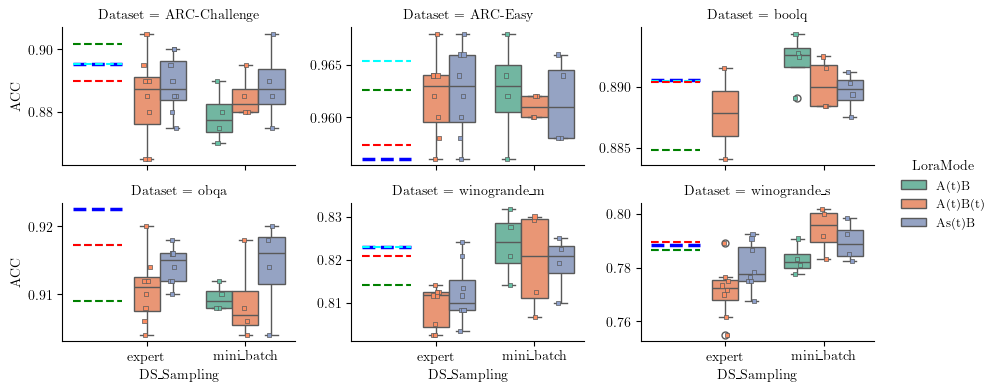

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['LoraMode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='DS_Sampling', y='acc', hue='LoraMode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='DS_Sampling',
        y='acc',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1215396/1686610667.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1686610667.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1686610667.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1686610667.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1686610667.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1686610667.py:22: FutureWarning: Use "auto" to set automatic grayscale c

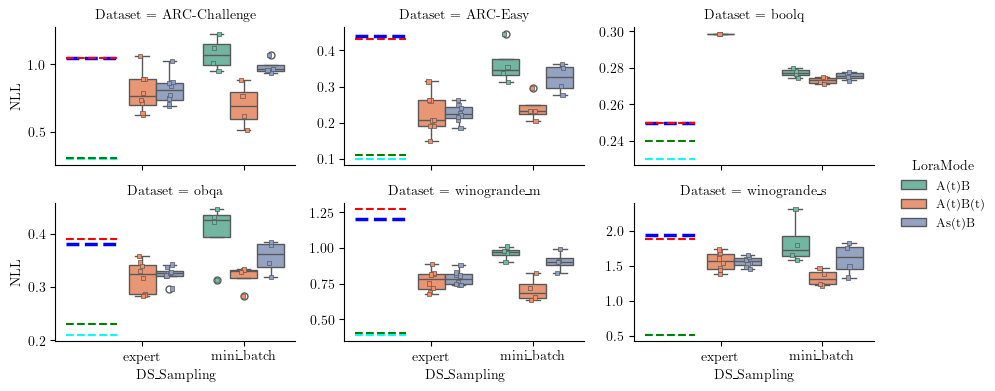

In [8]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_clean, x='DS_Sampling', y='nll', hue='LoraMode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='DS_Sampling',
        y='nll',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1215396/1965747456.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1965747456.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1965747456.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1965747456.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1965747456.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/1965747456.py:17: FutureWarning: Use "auto" to set automatic grayscale c

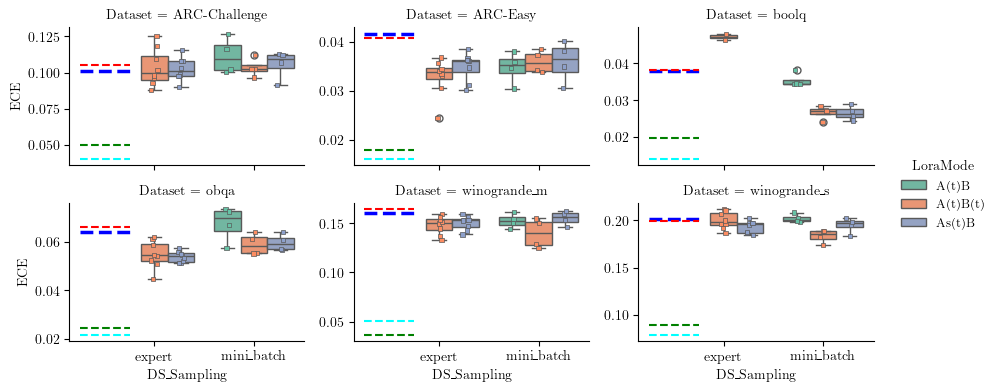

In [9]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_clean, x='DS_Sampling', y='ece', hue='LoraMode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='DS_Sampling',
        y='ece',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### Expert MAP run different sampling schemes 
with fixed posterior predictive evaluation and t dependet dataset samplinge
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

BMA with adding log weightes instead of multiplying weights in log space 

In [3]:
api = wandb.Api()
results = []

for s in ["kw05n5kp",]: # MAP expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["estg1uzi",]: # MAP expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


for s in ["00r8grro",]: # MAP training http://141.37.176.86:8080/ddold/qwen_PtoC/sweeps/00r8grro/overview
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'mini_batch': None}).keys())[0],
            DS_Mode='classic',
            DS_WindowSize=-1,
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'mini_batch': None}).keys())[0],
            DS_Mode='classic',
            DS_WindowSize=-1,
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df

kw05n5kp:  26%|██▌       | 31/120 [00:00<00:00, 252.36it/s, different-sweep-118]

Skipping chocolate-sweep-120 because it is not finished
Skipping decent-sweep-119 because it is not finished
Skipping ethereal-sweep-118 because it is not finished
Skipping pious-sweep-117 because it is not finished
Skipping sage-sweep-116 because it is not finished
Skipping snowy-sweep-115 because it is not finished
Skipping royal-sweep-114 because it is not finished
Skipping wise-sweep-113 because it is not finished


estg1uzi:  28%|██▊       | 51/180 [00:00<00:00, 430.08it/s, crisp-sweep-80]      

Skipping jumping-sweep-168 because it is not finished
Skipping scarlet-sweep-167 because it is not finished
Skipping celestial-sweep-166 because it is not finished
Skipping smart-sweep-165 because it is not finished
Skipping vocal-sweep-160 because it is not finished
Skipping snowy-sweep-159 because it is not finished
Skipping wandering-sweep-158 because it is not finished
Skipping whole-sweep-157 because it is not finished
Skipping cosmic-sweep-156 because it is not finished
Skipping glowing-sweep-155 because it is not finished
Skipping polished-sweep-154 because it is not finished
Skipping usual-sweep-153 because it is not finished
Skipping crimson-sweep-152 because it is not finished
Skipping true-sweep-151 because it is not finished
Skipping resilient-sweep-150 because it is not finished
Skipping desert-sweep-149 because it is not finished
Skipping ruby-sweep-148 because it is not finished
Skipping drawn-sweep-147 because it is not finished
Skipping firm-sweep-146 because it is not

estg1uzi: 100%|██████████| 180/180 [00:00<00:00, 426.10it/s, resilient-sweep-2] 


Skipping rare-sweep-68 because it is not finished
Skipping lilac-sweep-67 because it is not finished
Skipping fanciful-sweep-66 because it is not finished
Skipping honest-sweep-65 because it is not finished
Skipping electric-sweep-46 because it is not finished
Skipping deft-sweep-47 because it is not finished
Skipping ruby-sweep-48 because it is not finished
Skipping colorful-sweep-45 because it is not finished
Skipping snowy-sweep-40 because it is not finished
Skipping confused-sweep-38 because it is not finished
Skipping spring-sweep-39 because it is not finished
Skipping dauntless-sweep-37 because it is not finished
Skipping fine-sweep-36 because it is not finished
Skipping tough-sweep-35 because it is not finished
Skipping dazzling-sweep-32 because it is not finished
Skipping good-sweep-34 because it is not finished
Skipping zany-sweep-33 because it is not finished
Skipping mild-sweep-31 because it is not finished
Skipping ruby-sweep-29 because it is not finished
Skipping winter-sw

00r8grro: 100%|██████████| 144/144 [00:00<00:00, 214.14it/s, graceful-sweep-1]    


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,p3dlshht,2,0,8,0.01,obqa,ppd,expert,First_data,24,As(t)B,23.904387,0.896000,0.068582,0.346193,-inf,-inf,-inf,-inf
1,p3dlshht,2,0,8,0.01,obqa,mean,expert,First_data,24,As(t)B,23.904387,0.896000,0.068582,0.346193,-inf,-inf,-inf,-inf
2,8ssctdh4,2,0,4,0.01,obqa,ppd,expert,First_data,24,As(t)B,23.920265,0.926000,0.052236,0.306646,-inf,-inf,-inf,-inf
3,8ssctdh4,2,0,4,0.01,obqa,mean,expert,First_data,24,As(t)B,23.920265,0.926000,0.052236,0.306646,-inf,-inf,-inf,-inf
4,3ydraa56,2,0,2,0.01,obqa,ppd,expert,First_data,24,As(t)B,24.053455,0.908000,0.060350,0.364247,-inf,-inf,-inf,-inf
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,foh32rtr,2,0,4,0.01,winogrande_m,mean,mini_batch,classic,-1,A(t)B,25.083599,0.814167,0.161347,0.963773,-inf,-inf,-inf,-inf
724,s3dhsnwq,2,0,2,0.01,winogrande_m,ppd,mini_batch,classic,-1,A(t)B,25.099979,0.831667,0.144437,1.009636,-inf,-inf,-inf,-inf
725,s3dhsnwq,2,0,2,0.01,winogrande_m,mean,mini_batch,classic,-1,A(t)B,25.099979,0.831667,0.144437,1.009636,-inf,-inf,-inf,-inf
726,c19l3ikf,2,0,1,0.01,winogrande_m,ppd,mini_batch,classic,-1,A(t)B,25.090420,0.820833,0.154489,0.976121,-inf,-inf,-inf,-inf


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,LoraMode,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [ 2 20 10  5]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['obqa' 'ARC-Challenge' 'winogrande_m' 'ARC-Easy' 'boolq' 'winogrande_s']
Metric ['ppd' 'mean']
DS_Sampling ['expert' 'mini_batch']
DS_Mode ['First_data' 'Random' 'Spectral' 'Hierarchical' 'False' 'classic']
DS_WindowSize [24  4 -1]
LoraMode ['As(t)B' 'A(t)B(t)' 'A(t)B']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'LoraMode'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare window size

In [6]:
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['CurveSpace']==2]
df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

/tmp/ipykernel_1121568/2723434384.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/2723434384.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/2723434384.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


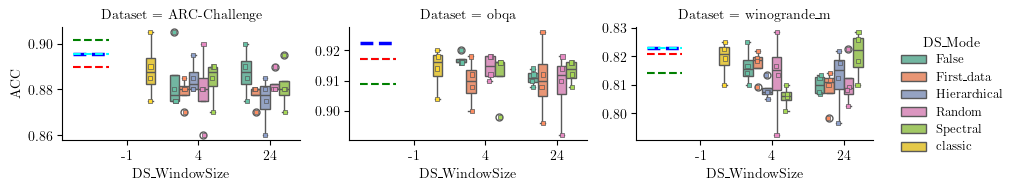

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['DS_Mode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='DS_WindowSize', y='acc', hue='DS_Mode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='DS_WindowSize',
        y='acc',
        hue='DS_Mode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1121568/1572607463.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/1572607463.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/1572607463.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


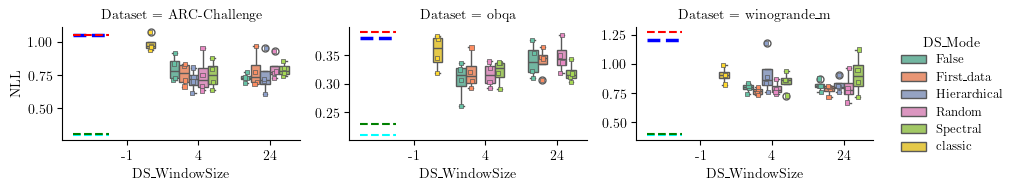

In [8]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='DS_WindowSize', y='nll', hue='DS_Mode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='DS_WindowSize',
        y='nll',
        hue='DS_Mode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_WindowSize'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1121568/991447137.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/991447137.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/991447137.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


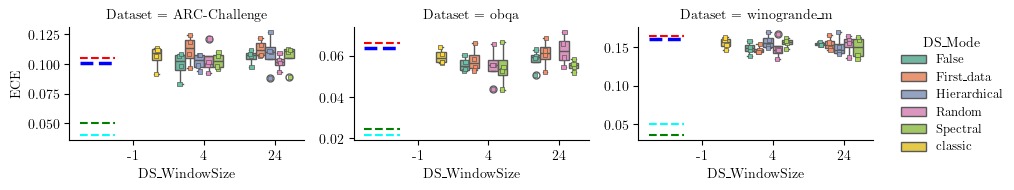

In [9]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='DS_WindowSize', y='ece', hue='DS_Mode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='DS_WindowSize',
        y='ece',
        hue='DS_Mode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_WindowSize'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

#### acc compare curve length in expert mode

In [10]:
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['DS_WindowSize']==4]
df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

/tmp/ipykernel_1121568/4119915030.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/4119915030.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/4119915030.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


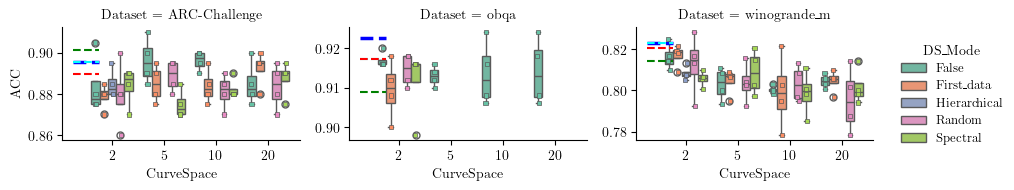

In [11]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['DS_Mode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='DS_Mode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='DS_Mode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1121568/1056148627.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/1056148627.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/1056148627.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


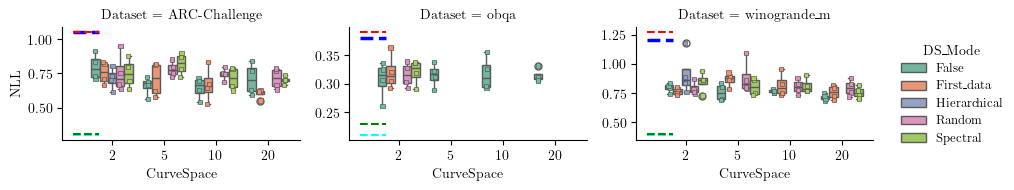

In [12]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='DS_Mode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='DS_Mode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1121568/121156304.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/121156304.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/121156304.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


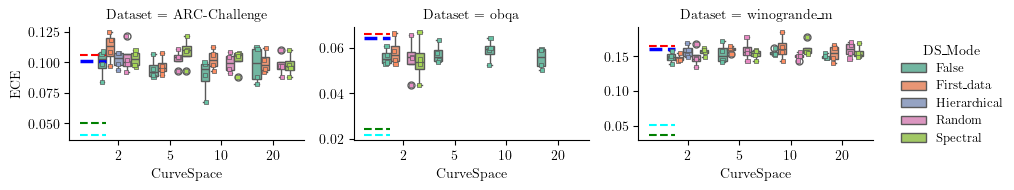

In [13]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='DS_Mode', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='DS_Mode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### Expert with Entropy maxim


In [14]:
api = wandb.Api()
results = []

for s in ["8xx6cgln",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df

8xx6cgln: 100%|██████████| 288/288 [00:01<00:00, 212.89it/s, treasured-sweep-1]      


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,NumSteps,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,v02xt0r0,5,0,8,0.01,ARC-Challenge,ppd,expert,False,4,...,3000,As(t)B,24.524803,0.905000,0.092602,0.525228,0.323177,0.144102,0.410120,0.279544
1,v02xt0r0,5,0,8,0.01,ARC-Challenge,mean,expert,False,4,...,3000,As(t)B,24.524803,0.905000,0.092462,0.522142,0.323177,0.144102,0.410120,0.279544
2,b30m1pzh,5,0,4,0.01,ARC-Challenge,ppd,expert,False,4,...,3000,As(t)B,24.572781,0.870000,0.101775,0.657897,0.403931,0.228741,0.329303,0.258647
3,b30m1pzh,5,0,4,0.01,ARC-Challenge,mean,expert,False,4,...,3000,As(t)B,24.572781,0.870000,0.099375,0.650365,0.403931,0.228741,0.329303,0.258647
4,ha6ue5d5,5,0,2,0.01,ARC-Challenge,ppd,expert,False,4,...,3000,As(t)B,24.619835,0.890000,0.092697,0.607667,0.318815,0.144556,0.479329,0.304344
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,g9h72bvi,2,0,4,0.01,winogrande_m,mean,expert,False,4,...,5000,As(t)B,23.842228,0.801667,0.158687,0.765178,0.122688,0.022653,0.006179,0.100029
572,qfatxp38,2,0,2,0.01,winogrande_m,ppd,expert,False,4,...,5000,As(t)B,23.989208,0.814167,0.144421,0.741179,0.113828,0.027135,0.007304,0.086722
573,qfatxp38,2,0,2,0.01,winogrande_m,mean,expert,False,4,...,5000,As(t)B,23.989208,0.814167,0.144399,0.741071,0.113828,0.027135,0.007304,0.086722
574,mgh3kt6e,2,0,1,0.01,winogrande_m,ppd,expert,False,4,...,5000,As(t)B,23.783070,0.823333,0.154286,0.951331,0.088880,0.026883,0.008994,0.062020


In [15]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,,,,,,,,


In [16]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [5 2]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['expert']
DS_Mode ['False']
DS_WindowSize [4]
EntropyMaxScale [10.   7.5  5.   2.5  1.   0.1]
NumSteps [3000 5000]
LoraMode ['As(t)B']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'EntropyMaxScale', 'NumSteps'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [29]:
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['CurveSpace']==5]
df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

/tmp/ipykernel_1121568/2072873006.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/2072873006.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/2072873006.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


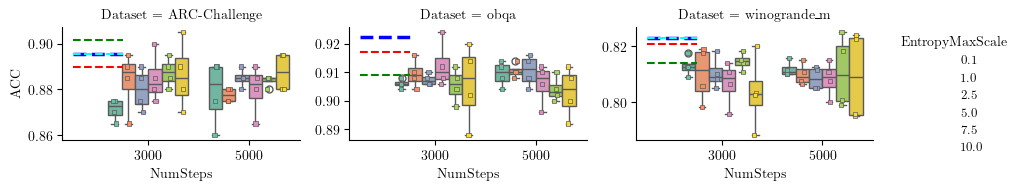

In [30]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['NumSteps']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='NumSteps', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='NumSteps',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1121568/3854426170.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/3854426170.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/3854426170.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


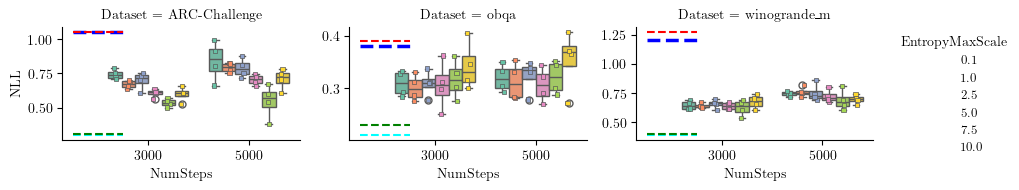

In [31]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='NumSteps', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='NumSteps',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['NumSteps'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1121568/2740248765.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/2740248765.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1121568/2740248765.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


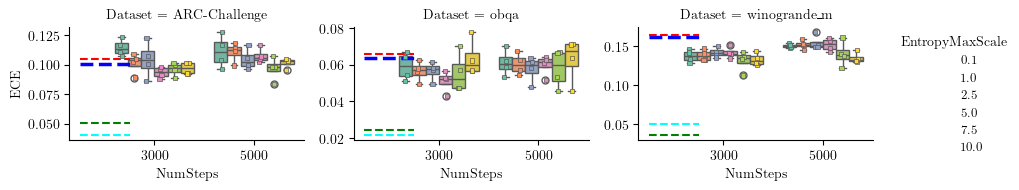

In [32]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='NumSteps', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='NumSteps',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['NumSteps'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### OOD runs with expert and jsd training

In [18]:
api = wandb.Api()
results = []

for s in ["qkg287h0",]: 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_t1_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_t1_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_t1_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["ro920obt",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),

                    Metric="ppd", # only for plotting
                    DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
                    DS_Mode="None",
                    DS_WindowSize=-1,
                    EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
                    NumSteps=run.config['curve_params'].get('num_steps', -1),
                    LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc=run.summary.get(f"final_acc_max", 0),
                    ece=run.summary.get(f"final_ece_min", 0),
                    nll=run.summary.get(f"final_loss_min", 0),
                    test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
                    test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
                    std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
                    mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
                    # bezierLength=run.summary.get('Curve length', 0),
                    # acc_max=run.summary['final_acc_max'],
                    # acc_mean=run.summary['final_acc_mean'],
                    # nll_min=run.summary['final_loss_min'],
                    # nll_mean=run.summary['final_loss_mean'],
                    # ece_mean=run.summary['final_ece_mean'],
                    # ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

ro920obt: 100%|██████████| 48/48 [00:00<00:00, 313.15it/s, good-sweep-1]          


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,NumSteps,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,jzt6xs8x,5,0,8,0.01,ARC-Easy,ppd,expert,False,4,...,-1,As(t)B,0,0.942,0.042487,0.219035,0.306365,0.136432,0.475765,0.304751
1,jzt6xs8x,5,0,8,0.01,ARC-Easy,mean,expert,False,4,...,-1,As(t)B,0,0.942,0.042500,0.219042,0.306365,0.136432,0.475765,0.304751
2,5pelavo1,5,0,4,0.01,ARC-Easy,ppd,expert,False,4,...,-1,As(t)B,0,0.944,0.032946,0.198463,0.326412,0.144956,0.439779,0.290932
3,5pelavo1,5,0,4,0.01,ARC-Easy,mean,expert,False,4,...,-1,As(t)B,0,0.944,0.032488,0.198402,0.326412,0.144956,0.439779,0.290932
4,v543eehe,5,0,2,0.01,ARC-Easy,ppd,expert,False,4,...,-1,As(t)B,0,0.946,0.024635,0.177283,0.311964,0.141802,0.508376,0.314703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299,4p8cfzf0,0,0,1,0.01,MMLU_chem,ppd,None,None,-1,...,-1,None,0,0.500,0.280508,1.617188,-inf,-inf,-inf,-inf
300,efy2o6ih,0,0,8,0.01,MMLU_phy,ppd,None,None,-1,...,-1,None,0,0.520,0.223398,1.289062,-inf,-inf,-inf,-inf
301,lqwpl83h,0,0,4,0.01,MMLU_phy,ppd,None,None,-1,...,-1,None,0,0.440,0.251602,1.289062,-inf,-inf,-inf,-inf
302,jtcvlzdf,0,0,2,0.01,MMLU_phy,ppd,None,None,-1,...,-1,None,0,0.500,0.182344,1.367188,-inf,-inf,-inf,-inf


In [19]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,,,,,,,,


In [20]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [5 2 0]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'MMLU_chem' 'MMLU_phy']
Metric ['ppd' 'mean']
DS_Sampling ['expert' 'None']
DS_Mode ['False' 'None']
DS_WindowSize [ 4 -1]
EntropyMaxScale [10.   7.5  5.   2.5 -1. ]
NumSteps [-1]
LoraMode ['As(t)B' 'None']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'EntropyMaxScale', 'LoraMode'] configs


array(['ARC-Challenge', 'ARC-Easy', 'MMLU_chem', 'MMLU_phy'], dtype=object)

#### acc compare Entropy Scale

In [21]:
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'ARC-Easy', 'MMLU_chem', 'MMLU_phy'], dtype=object)

/tmp/ipykernel_1151031/1723324532.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/1723324532.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/1723324532.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/1723324532.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


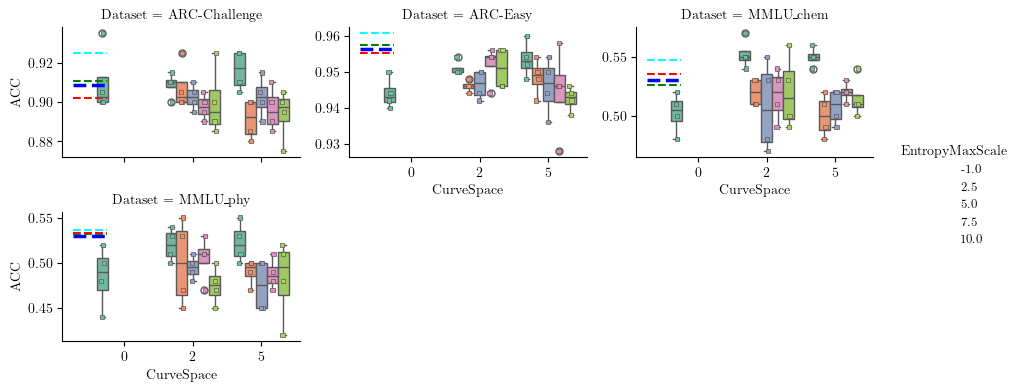

In [22]:
# Reference accuracy values from table 2
ref_acc_ood = {
    'obqa':             {'MLE': 92.25, 'MAP': 91.72, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'ARC-Challenge':    {'MLE': 90.88, 'MAP': 90.20, 'BLoB': 92.49, 'ScalaBL': 91.06},
    'ARC-Easy':         {'MLE': 95.64, 'MAP': 95.53, 'BLoB': 96.07, 'ScalaBL': 95.74},
    'MMLU_chem':        {'MLE': 53.00, 'MAP': 53.50, 'BLoB': 54.69, 'ScalaBL': 52.60},
    'MMLU_phy':         {'MLE': 53.00, 'MAP': 53.25, 'BLoB': 53.65, 'ScalaBL': 53.15}
}


# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc_ood:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc_ood[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc_ood[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc_ood[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc_ood[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1151031/3453702286.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/3453702286.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/3453702286.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/3453702286.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


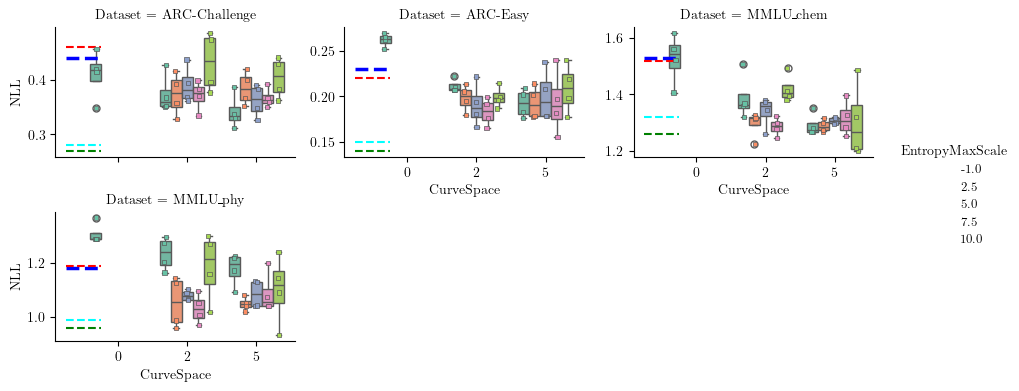

In [23]:
ref_nll_ood = {
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB': 0.21, 'ScalaBL': 0.23},
    'ARC-Challenge': {'MLE': 0.44, 'MAP': 0.46, 'BLoB': 0.28, 'ScalaBL': 0.27},
    'ARC-Easy':      {'MLE': 0.23, 'MAP': 0.22, 'BLoB': 0.15, 'ScalaBL': 0.14},
    'MMLU_chem':     {'MLE': 1.53, 'MAP': 1.52, 'BLoB': 1.32, 'ScalaBL': 1.26},
    'MMLU_phy':      {'MLE': 1.18, 'MAP': 1.19, 'BLoB': 0.99, 'ScalaBL': 0.96}
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
# weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll_ood:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll_ood[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll_ood[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll_ood[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll_ood[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1151031/385716220.py:16: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/385716220.py:16: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/385716220.py:16: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1151031/385716220.py:16: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


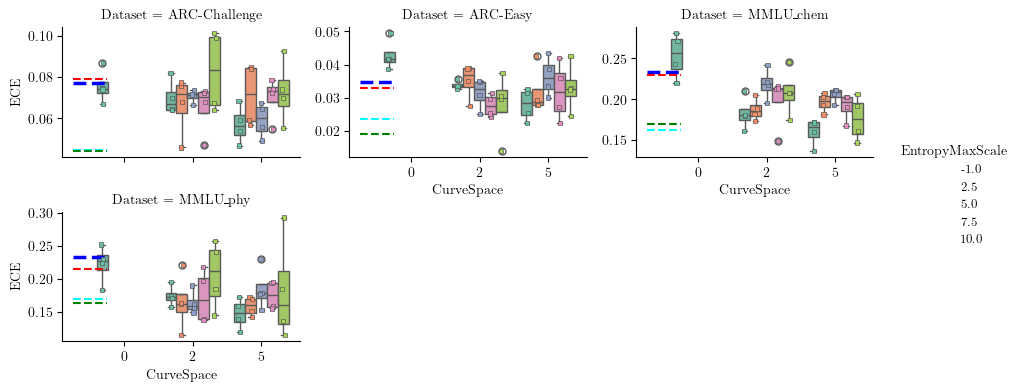

In [24]:
ref_ece_ood = {
    'obqa':             {'MLE': 6.40, 'MAP': 6.61, 'BLoB': 2.16, 'ScalaBL': 2.43},
    'ARC-Challenge':    {'MLE': 7.72, 'MAP': 7.89, 'BLoB': 4.46, 'ScalaBL': 4.41},
    'ARC-Easy':         {'MLE': 3.48, 'MAP': 3.31, 'BLoB': 2.35, 'ScalaBL': 1.92},
    'MMLU_chem':        {'MLE': 23.29,'MAP': 22.90, 'BLoB': 16.21, 'ScalaBL': 16.94},
    'MMLU_phy':         {'MLE': 23.22,'MAP': 21.52, 'BLoB': 16.93, 'ScalaBL': 16.29}
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
# weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece_ood:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece_ood[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece_ood[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece_ood[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece_ood[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### MiniBatch with validaten data


In [21]:
api = wandb.Api()
results = []

for s in ["0zkos614",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df

0zkos614:   0%|          | 0/36 [00:00<?, ?it/s, comfy-sweep-27]    

0zkos614: 100%|██████████| 36/36 [00:00<00:00, 373.68it/s, swift-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,NumSteps,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,dnjchqms,5,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,5000,As(t)B,24.431843,0.900000,0.056942,0.337576,0.160731,8.413488e-03,1.880949e-02,0.152314
1,dnjchqms,5,0,8,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,5000,As(t)B,24.431843,0.900000,0.056941,0.337578,-inf,-inf,1.880949e-02,0.152314
2,v6cifdaz,5,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,5000,As(t)B,24.490715,0.885000,0.057138,0.332405,0.298041,1.173443e-02,4.969776e-02,0.286332
3,v6cifdaz,5,0,4,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,5000,As(t)B,24.490715,0.885000,0.057135,0.332407,-inf,-inf,4.969776e-02,0.286332
4,6emdndh6,5,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,5000,As(t)B,24.555595,0.900000,0.049955,0.309974,0.287300,4.545931e-03,2.671961e-02,0.283097
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,g8d4w55c,0,0,4,0.01,winogrande_m,mean,minibatch,classic,-1,...,5000,As(t)B,0.000000,0.807500,0.076882,0.434429,-inf,-inf,2.980232e-08,0.274630
68,ox5oemp0,0,0,2,0.01,winogrande_m,ppd,minibatch,classic,-1,...,5000,As(t)B,0.000000,0.815000,0.055034,0.431711,0.324559,6.338387e-08,0.000000e+00,0.324559
69,ox5oemp0,0,0,2,0.01,winogrande_m,mean,minibatch,classic,-1,...,5000,As(t)B,0.000000,0.815000,0.055034,0.431711,-inf,-inf,0.000000e+00,0.324559
70,kimiu9rz,0,0,1,0.01,winogrande_m,ppd,minibatch,classic,-1,...,5000,As(t)B,0.000000,0.814167,0.065749,0.450442,0.325778,6.230548e-08,0.000000e+00,0.325778


In [22]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,,,,,,,,


In [23]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [5 2 0]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['As(t)B']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [24]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order

df_subset.groupby(['Dataset', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       CurveSpace EntropyMaxScale                              
ARC-Challenge 0          0                0.886250  0.326249  0.060490
              2          0                0.883750  0.337572  0.048529
              5          0                0.892500  0.324448  0.050696
obqa          0          0                0.917000  0.244404  0.024823
              2          0                0.915000  0.244980  0.028358
              5          0                0.906000  0.264976  0.029702
winogrande_m  0          0                0.811250  0.434169  0.062158
              2          0                0.804583  0.437815  0.038768
              5          0                0.811042  0.435443  0.040568

/tmp/ipykernel_1166502/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1166502/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1166502/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


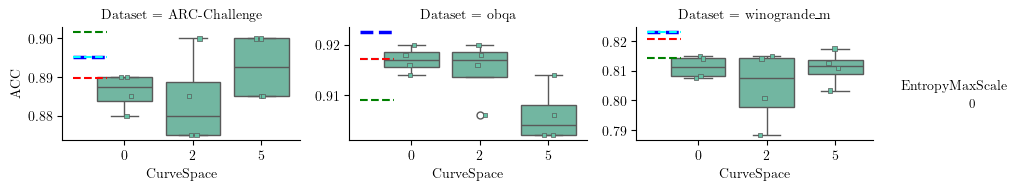

In [15]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1166502/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1166502/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1166502/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


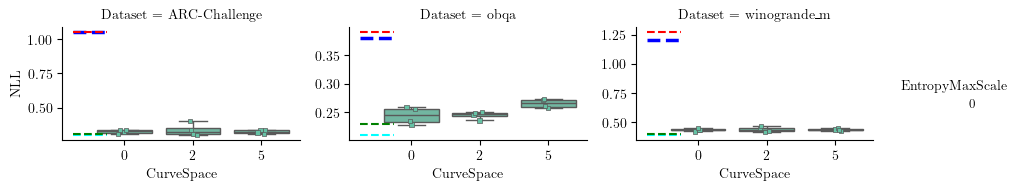

In [16]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1166502/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1166502/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1166502/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


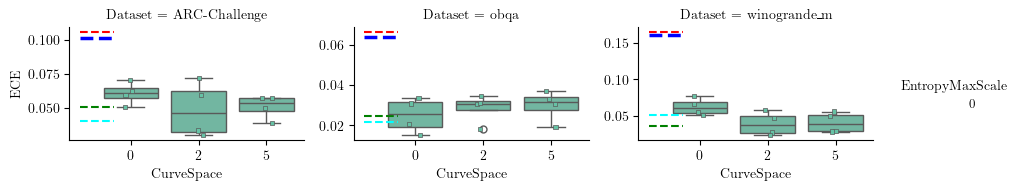

In [17]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### MiniBatch with validaten data and entropy maxim


In [6]:
api = wandb.Api()
results = []

for s in ["trjj6h1h",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df.head()

trjj6h1h:   0%|          | 0/24 [00:00<?, ?it/s, solar-sweep-15]   

trjj6h1h: 100%|██████████| 24/24 [00:00<00:00, 355.06it/s, rich-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,NumSteps,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,copd2rf7,2,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,5000,As(t)B,23.914024,0.905,0.072683,0.323523,0.171446,0.008169,0.014911,0.163279
1,copd2rf7,2,0,8,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,5000,As(t)B,23.914024,0.905,0.072683,0.323521,-inf,-inf,0.014911,0.163279
2,x5islz3m,2,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,5000,As(t)B,23.958462,0.875,0.042813,0.321345,0.341773,0.003793,0.024668,0.338510
3,x5islz3m,2,0,4,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,5000,As(t)B,23.958462,0.875,0.042417,0.321324,-inf,-inf,0.024668,0.338510
4,fwjs4xif,2,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,5000,As(t)B,24.089703,0.880,0.045150,0.330292,0.271465,0.004547,0.034265,0.266923


In [7]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,,,,,,,,


In [8]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [5.  2.5]
NumSteps [5000]
LoraMode ['As(t)B']

Experiment differs in ['Dataset', 'Metric', 'EntropyMaxScale'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [20]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       CurveSpace EntropyMaxScale                              
ARC-Challenge 2          2.5              0.887500  0.329219  0.049577
                         5.0              0.885000  0.326466  0.050210
obqa          2          2.5              0.919500  0.245185  0.028157
                         5.0              0.916000  0.251584  0.026631
winogrande_m  2          2.5              0.810208  0.435576  0.047851
                         5.0              0.803542  0.445454  0.050602

/tmp/ipykernel_1178681/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1178681/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1178681/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


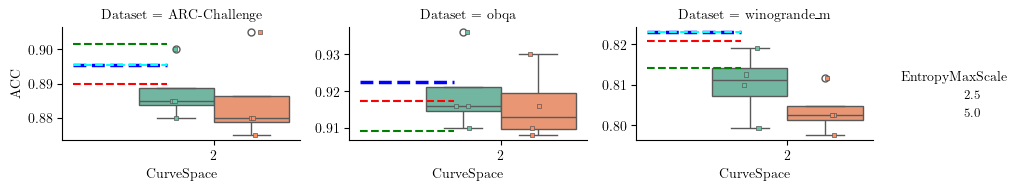

In [10]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1178681/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1178681/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1178681/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


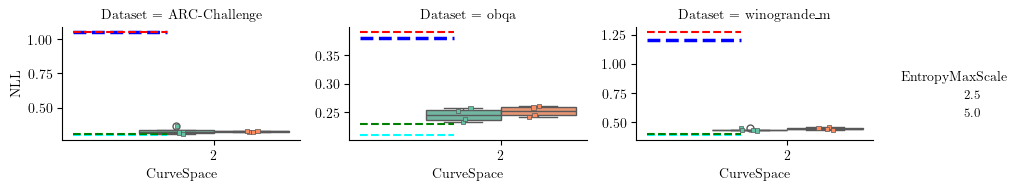

In [11]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1178681/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1178681/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1178681/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


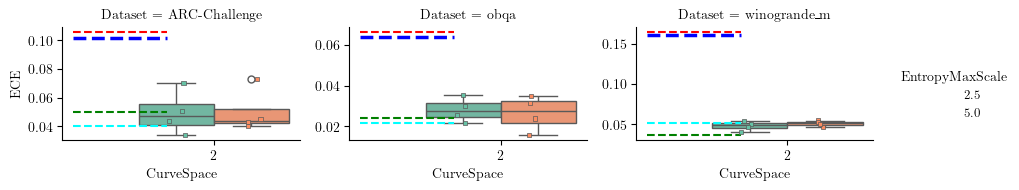

In [12]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### Expert with validaten data and entropy maxim


In [3]:
api = wandb.Api()
results = []

for s in ["4mkdmcjc",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df.head()

4mkdmcjc: 100%|██████████| 24/24 [00:00<00:00, 349.64it/s, hearty-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,NumSteps,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,pqith9tp,2,0,8,0.01,ARC-Challenge,ppd,expert,False,4,...,5000,As(t)B,23.946075,0.890,0.066236,0.322460,0.168139,0.011457,0.018046,0.156924
1,pqith9tp,2,0,8,0.01,ARC-Challenge,mean,expert,False,4,...,5000,As(t)B,23.946075,0.890,0.061454,0.322431,-inf,-inf,0.018046,0.156924
2,c5kr7rjl,2,0,4,0.01,ARC-Challenge,ppd,expert,False,4,...,5000,As(t)B,23.970606,0.880,0.052588,0.324681,0.291517,0.002750,0.016044,0.288667
3,c5kr7rjl,2,0,4,0.01,ARC-Challenge,mean,expert,False,4,...,5000,As(t)B,23.970606,0.880,0.052612,0.324694,-inf,-inf,0.016044,0.288667
4,fdjrq1hl,2,0,2,0.01,ARC-Challenge,ppd,expert,False,4,...,5000,As(t)B,24.100632,0.865,0.039206,0.338020,0.276378,0.005410,0.002126,0.270968


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['expert']
DS_Mode ['False']
DS_WindowSize [4]
EntropyMaxScale [5.  2.5]
NumSteps [5000]
LoraMode ['As(t)B']

Experiment differs in ['Dataset', 'Metric', 'EntropyMaxScale'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       CurveSpace EntropyMaxScale                              
ARC-Challenge 2          2.5              0.883750  0.325848  0.054848
                         5.0              0.881250  0.329759  0.053714
obqa          2          2.5              0.904500  0.276605  0.028800
                         5.0              0.907500  0.270963  0.026562
winogrande_m  2          2.5              0.803333  0.468459  0.063021
                         5.0              0.795208  0.463304  0.064432

/tmp/ipykernel_1183651/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1183651/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1183651/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


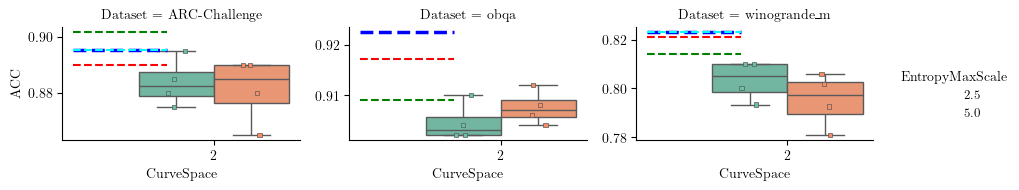

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1183651/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1183651/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1183651/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


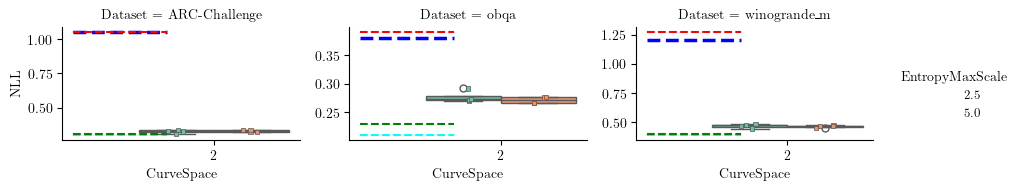

In [8]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1183651/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1183651/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1183651/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


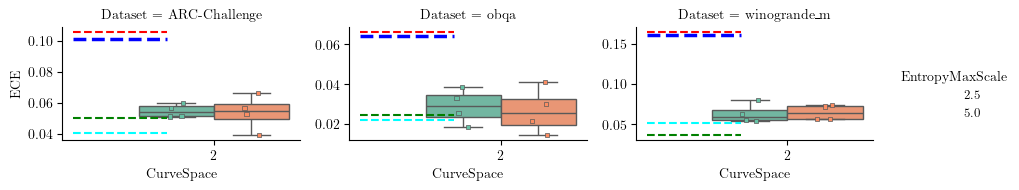

In [9]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### B-Spline Expert with validaten data and entropy maxim


In [17]:
api = wandb.Api()
results = []

for s in ["trqlhorq",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df.head()

trqlhorq: 100%|██████████| 48/48 [00:00<00:00, 355.54it/s, bright-sweep-1]   


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,NumSteps,LoraMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,ngljs86h,10,0,8,0.01,ARC-Challenge,ppd,expert,False,4,...,5000,As(t)B,23.115738,0.890,0.065048,0.330514,0.235881,0.025026,0.034080,0.212898
1,ngljs86h,10,0,8,0.01,ARC-Challenge,mean,expert,False,4,...,5000,As(t)B,23.115738,0.885,0.064337,0.330513,-inf,-inf,0.034080,0.212898
2,in5xigq1,10,0,4,0.01,ARC-Challenge,ppd,expert,False,4,...,5000,As(t)B,23.301168,0.880,0.049468,0.328635,0.363025,0.009947,0.065400,0.356037
3,in5xigq1,10,0,4,0.01,ARC-Challenge,mean,expert,False,4,...,5000,As(t)B,23.301168,0.880,0.049423,0.328612,-inf,-inf,0.065400,0.356037
4,2qes37cy,10,0,2,0.01,ARC-Challenge,ppd,expert,False,4,...,5000,As(t)B,23.317736,0.875,0.062066,0.328717,0.300564,0.011838,0.038417,0.289893


In [18]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,,,,,,,,


In [19]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [10  5]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['expert']
DS_Mode ['False']
DS_WindowSize [4]
EntropyMaxScale [5 0]
NumSteps [5000]
LoraMode ['As(t)B']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'EntropyMaxScale'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [20]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       CurveSpace EntropyMaxScale                              
ARC-Challenge 5          0                0.880000  0.336396  0.050711
                         5                0.886250  0.319803  0.052627
              10         0                0.881250  0.352468  0.047758
                         5                0.875000  0.338634  0.057866
obqa          5          0                0.899000  0.299015  0.036246
                         5                0.909500  0.273904  0.027400
              10         0                0.905000  0.294097  0.035901
                         5                0.908500  0.285844  0.033343
winogrande_m  5          0                0.784792  0.503233  0.079317
                         5                0.797083  0.485379  0.082810
              10         0                0.771042  0.529484  0.087006
                         5                0.792708  0.487221  0.072985

/tmp/ipykernel_1215396/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


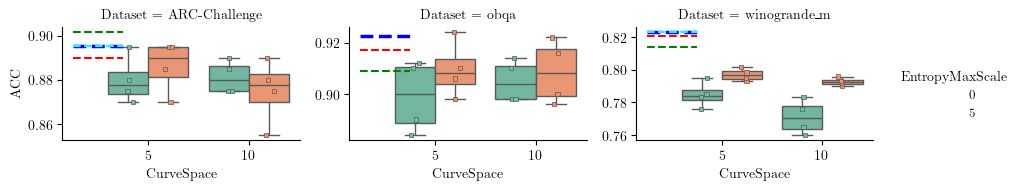

In [21]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1215396/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/2629802758.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


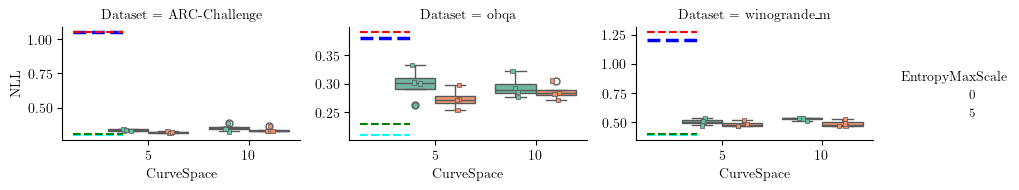

In [22]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_nll[dataset]['MLE'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_nll[dataset]['MAP'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1215396/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1215396/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


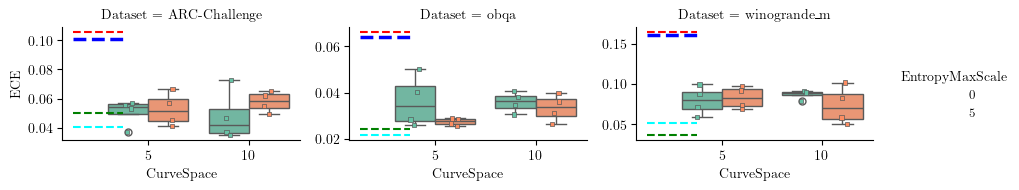

In [23]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### B-Spline with MiniBatch sampling, validaten data, and entropy maxim


In [32]:
api = wandb.Api()
results = []

for s in ["tsxj3nh0",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode="B-Spline",
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode="B-Spline",
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["0zkos614",]: # minibatch no entropy and bezier 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode="Bezier",
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode="Bezier",
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["trjj6h1h",]: # minibatch + entropy + bezier 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode="Bezier",
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode="Bezier",
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

df = pd.DataFrame(results)
df.head()

tsxj3nh0:   0%|          | 0/48 [00:00<?, ?it/s, lyric-sweep-26]   

tsxj3nh0: 100%|██████████| 48/48 [00:00<00:00, 348.73it/s, breezy-sweep-1]   


Skipping legendary-sweep-48 because it is not finished
Skipping robust-sweep-47 because it is not finished
Skipping vivid-sweep-46 because it is not finished


trjj6h1h: 100%|██████████| 24/24 [00:00<00:00, 408.62it/s, rich-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,LoraMode,CurveMode,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,8m5n6e6p,5,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,As(t)B,B-Spline,24.446543,0.905,0.062464,0.324410,0.175221,0.013413,0.037757,0.163962
1,8m5n6e6p,5,0,8,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,As(t)B,B-Spline,24.446543,0.905,0.062386,0.324067,-inf,-inf,0.037757,0.163962
2,xondolt4,10,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,As(t)B,B-Spline,23.284096,0.875,0.058854,0.327936,0.337561,0.016097,0.068680,0.321540
3,xondolt4,10,0,4,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,As(t)B,B-Spline,23.284096,0.875,0.058852,0.327937,-inf,-inf,0.068680,0.321540
4,24lrb6m3,10,0,8,0.01,obqa,ppd,minibatch,classic,-1,...,As(t)B,B-Spline,23.042374,0.918,0.015276,0.228453,0.252283,0.014056,0.031282,0.239141


In [33]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,,,,,,,,


In [34]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [ 5 10  2  0]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd' 'mean']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [5.  0.  2.5]
NumSteps [5000]
LoraMode ['As(t)B']
CurveMode ['B-Spline' 'Bezier']

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'EntropyMaxScale', 'CurveMode'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [40]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','CurveMode', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll  \
Dataset       CurveMode CurveSpace EntropyMaxScale                       
ARC-Challenge B-Spline  5          0.0              0.890000  0.324068   
                                   5.0              0.895000  0.313743   
                        10         0.0              0.887500  0.321562   
                                   5.0              0.875000  0.327936   
              Bezier    0          0.0              0.886250  0.326249   
                        2          0.0              0.883750  0.337572   
                                   5.0              0.885000  0.326466   
                        5          0.0              0.892500  0.324448   
obqa          B-Spline  5          0.0              0.912000  0.248977   
                                   5.0              0.911500  0.253302   
                        10         0.0              0.906500  0.264301   
                                   5.0              0.909000  0.255571   
              Bezier    0          0.0              0.917000  0.244404   
                        2          0.0              0.915000  0.244980   
                                   5.0              0.916000  0.251584   
                        5          0.0              0.906000  0.264976   
winogrande_m  B-Spline  5          0.0              0.811875  0.462439   
                                   5.0              0.807917  0.444813   
                        10         0.0              0.811875  0.448040   
                                   5.0              0.808125  0.451601   
              Bezier    0          0.0              0.811250  0.434169   
                        2          0.0              0.804583  0.437815   
                                   5.0              0.803542  0.445454   
                        5          0.0              0.811042  0.435443   

                                                         ece  
Dataset       CurveMode CurveSpace EntropyMaxScale            
ARC-Challenge B-Spline  5          0.0              0.054120  
                                   5.0              0.050213  
                        10         0.0              0.049081  
                                   5.0              0.058854  
              Bezier    0          0.0              0.060490  
                        2          0.0              0.048529  
                                   5.0              0.050210  
                        5          0.0              0.050696  
obqa          B-Spline  5          0.0              0.022252  
                                   5.0              0.033810  
                        10         0.0              0.031336  
                                   5.0              0.024555  
              Bezier    0          0.0              0.024823  
                        2          0.0              0.028358  
                                   5.0              0.026631  
                        5          0.0              0.029702  
winogrande_m  B-Spline  5          0.0              0.062837  
                                   5.0              0.052831  
                        10         0.0              0.059264  
                                   5.0              0.054675  
              Bezier    0          0.0              0.062158  
                        2          0.0              0.038768  
                                   5.0              0.050602  
                        5          0.0              0.040568

/tmp/ipykernel_1237723/2363064939.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2363064939.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2363064939.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2363064939.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2363064939.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2363064939.py:24: FutureWarning: Use "auto" to set automatic grayscale c

Dataset = ARC-Challenge | EntropyMaxScale = 0.0
ARC-Challenge
Dataset = obqa | EntropyMaxScale = 0.0
obqa
Dataset = winogrande_m | EntropyMaxScale = 0.0
winogrande_m


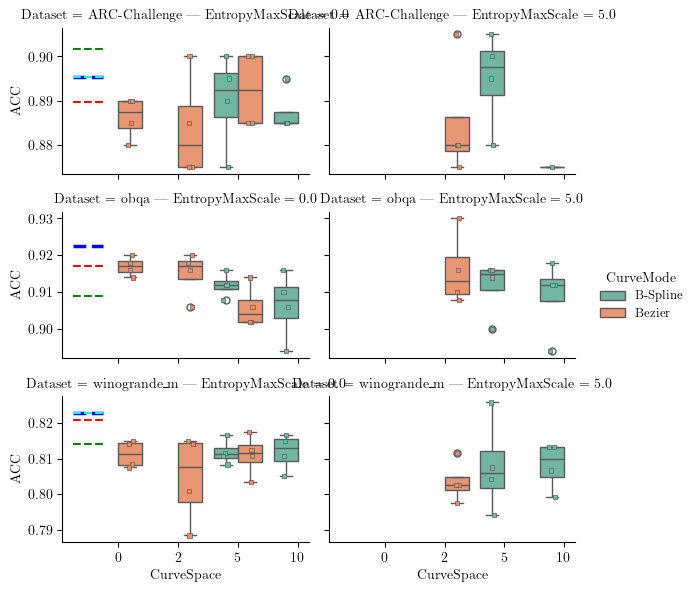

In [42]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['CurveMode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='CurveMode', kind='box', row='Dataset', col='EntropyMaxScale', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['EntropyMaxScale'] == float(entropy_scale))],
            x='CurveSpace',
            y='acc',
            hue='CurveMode',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1237723/1089568642.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/1089568642.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/1089568642.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/1089568642.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/1089568642.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/1089568642.py:23: FutureWarning: Use "auto" to set automatic grayscale c

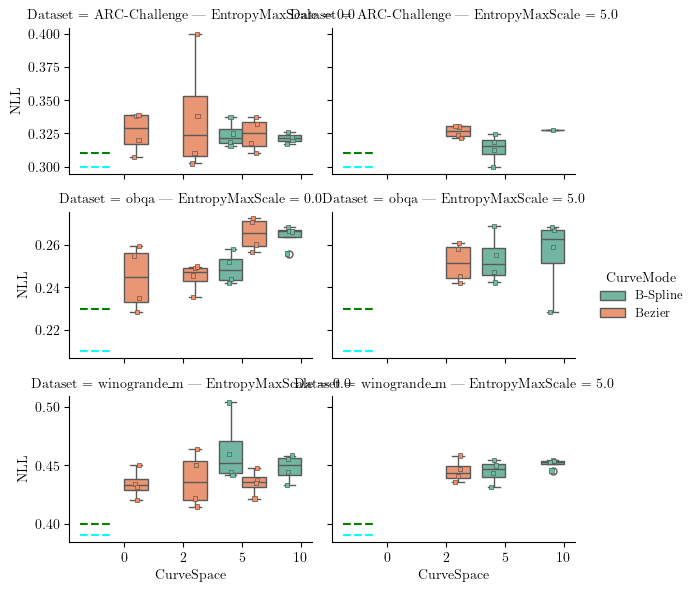

In [43]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='CurveMode', kind='box', row='Dataset', col='EntropyMaxScale', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['EntropyMaxScale'] == float(entropy_scale))],
        x='CurveSpace',
        y='nll',
        hue='CurveMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1237723/342376986.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/342376986.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/342376986.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/342376986.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/342376986.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/342376986.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

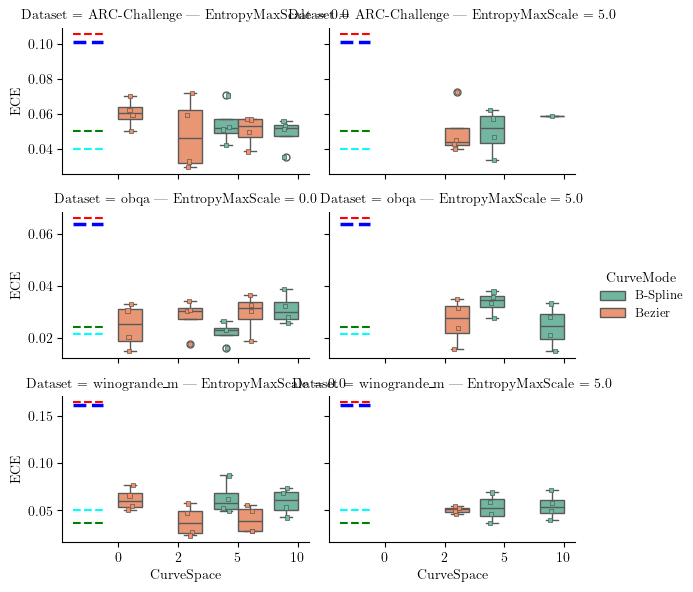

In [44]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='CurveMode', kind='box', row='Dataset', col='EntropyMaxScale', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['EntropyMaxScale'] == float(entropy_scale))],
        x='CurveSpace',
        y='ece',
        hue='CurveMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### DE with validation


In [55]:
api = wandb.Api()
results = []

for s in ["unb6x3vq",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)


df = pd.DataFrame(results)
df.head()

unb6x3vq:   0%|          | 0/36 [00:00<?, ?it/s, serene-sweep-6]     

unb6x3vq: 100%|██████████| 36/36 [00:00<00:00, 483.18it/s, wise-sweep-10]

Skipping sunny-sweep-36 because it is not finished
Skipping lunar-sweep-35 because it is not finished
Skipping eager-sweep-34 because it is not finished
Skipping sleek-sweep-33 because it is not finished
Skipping robust-sweep-32 because it is not finished
Skipping resilient-sweep-31 because it is not finished
Skipping earthy-sweep-28 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,EntropyMaxScale,NumSteps,LoraMode,bezierLength,acc,ece,nll
0,bjp9kin4,10,0,4,0.01,winogrande_m,ppd,None,minibatch,-1,5000,A(t)B,0,0.830000,0.167577,0.391305
1,rhvcdvfp,10,0,2,0.01,winogrande_m,ppd,None,minibatch,-1,5000,A(t)B,0,0.828333,0.170621,0.393786
2,u0dd4utf,3,0,8,0.01,winogrande_m,ppd,None,minibatch,-1,5000,A(t)B,0,0.819167,0.165097,0.397631
3,g5jg7hc0,10,0,8,0.01,ARC-Challenge,ppd,None,minibatch,-1,5000,A(t)B,0,0.900000,0.522544,0.291192
4,duhqpwqx,10,0,4,0.01,ARC-Challenge,ppd,None,minibatch,-1,5000,A(t)B,0,0.885000,0.508799,0.312289


In [56]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,bezierLength,acc,ece,nll
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,EntropyMaxScale,NumSteps,LoraMode,,,,


In [57]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [10  3  6]
Jitter [0]
Seed [4 2 8 1]
WeightDecay [0.01]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa']
Metric ['ppd']
DS_Sampling ['None']
DS_Mode ['minibatch']
EntropyMaxScale [-1]
NumSteps [5000]
LoraMode ['A(t)B']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [58]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       CurveSpace EntropyMaxScale                              
ARC-Challenge 3          -1               0.901250  0.300610  0.525800
              6          -1               0.898750  0.301807  0.524635
              10         -1               0.893333  0.300116  0.517443
obqa          3          -1               0.917500  0.228231  0.469771
              6          -1               0.920500  0.222564  0.472848
winogrande_m  3          -1               0.828125  0.395557  0.167246
              6          -1               0.825625  0.396008  0.168026
              10         -1               0.829167  0.392545  0.169099

/tmp/ipykernel_1237723/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/2273761135.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


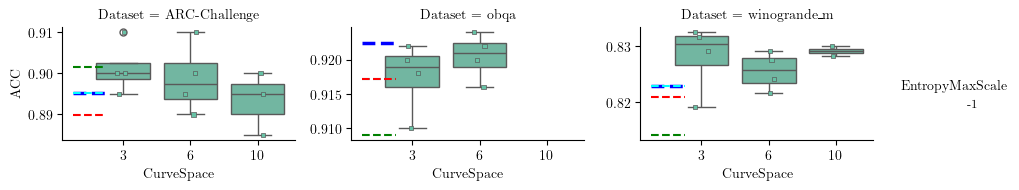

In [59]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['EntropyMaxScale'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='acc',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1237723/3135327937.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/3135327937.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/3135327937.py:22: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


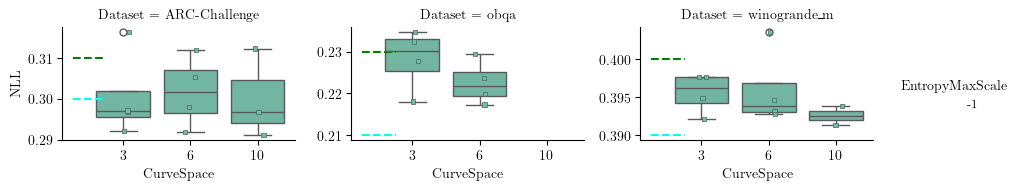

In [62]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='nll',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1237723/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1237723/210717621.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


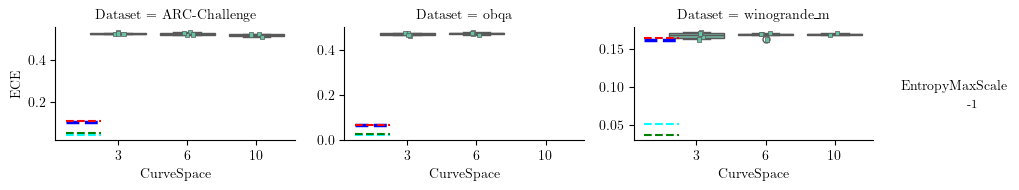

In [61]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='EntropyMaxScale', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[df_subset['Dataset'] == ds],
        x='CurveSpace',
        y='ece',
        hue='EntropyMaxScale',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### miniBatch with larger lora rank and A(t)B(t) trainining


In [3]:
api = wandb.Api()
results = []

for s in ["5hnyo8eg",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

df = pd.DataFrame(results)
df.head()

5hnyo8eg:   0%|          | 0/185 [00:00<?, ?it/s, light-sweep-176]

5hnyo8eg:  17%|█▋        | 31/185 [00:00<00:00, 266.01it/s, comfy-sweep-116]        

Skipping grateful-sweep-185 because it is not finished
Skipping fresh-sweep-184 because it is not finished
Skipping splendid-sweep-183 because it is not finished
Skipping splendid-sweep-182 because it is not finished
Skipping fine-sweep-181 because it is not finished
Skipping avid-sweep-180 because it is not finished
Skipping stellar-sweep-179 because it is not finished
Skipping sparkling-sweep-178 because it is not finished
Skipping stellar-sweep-177 because it is not finished
Skipping dry-sweep-160 because it is not finished


5hnyo8eg: 100%|██████████| 185/185 [00:00<00:00, 362.05it/s, vague-sweep-1]     


Skipping rich-sweep-67 because it is not finished
Skipping summer-sweep-36 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,CurveMode,LoraRank,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,eeuvsrbg,5,0,8,0.01,winogrande_m,ppd,minibatch,classic,-1,...,bezier,32,73.405060,0.806667,0.046717,0.444724,0.387362,0.035661,0.041510,0.355102
1,eeuvsrbg,5,0,8,0.01,winogrande_m,mean,minibatch,classic,-1,...,bezier,32,73.405060,0.807500,0.045479,0.444952,-inf,-inf,0.041510,0.355102
2,7zvkaudi,5,0,4,0.01,winogrande_m,ppd,minibatch,classic,-1,...,bezier,32,73.031357,0.809167,0.051231,0.428225,0.376817,0.026621,0.046365,0.353514
3,7zvkaudi,5,0,4,0.01,winogrande_m,mean,minibatch,classic,-1,...,bezier,32,73.031357,0.809167,0.050462,0.427886,-inf,-inf,0.046365,0.353514
4,pgb3m7tn,5,0,2,0.01,winogrande_m,ppd,minibatch,classic,-1,...,bezier,32,73.021698,0.814167,0.028887,0.423081,0.401247,0.032577,0.031772,0.370262


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [ 5  2 10]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa']
Metric ['ppd' 'mean']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [5.  2.5 0. ]
NumSteps [5000]
LoraMode ['A(t)B(t)']
CurveMode ['bezier']
LoraRank [32  8]

Experiment differs in ['CurveSpace', 'Dataset', 'Metric', 'EntropyMaxScale', 'LoraRank'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraRank', 'CurveSpace', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc       nll  \
Dataset       LoraRank CurveSpace EntropyMaxScale                       
ARC-Challenge 8        2          0.0              0.885000  0.316538   
                                  2.5              0.893750  0.325155   
                                  5.0              0.897500  0.304532   
                       5          0.0              0.896250  0.301028   
                                  2.5              0.895000  0.322546   
                       10         0.0              0.900000  0.333387   
                                  2.5              0.898750  0.330122   
              32       2          0.0              0.882500  0.316754   
                                  2.5              0.898750  0.308530   
                                  5.0              0.895000  0.305082   
                       5          0.0              0.892500  0.316140   
                                  2.5              0.901250  0.306779   
                       10         0.0              0.893750  0.326920   
                                  2.5              0.891250  0.317311   
obqa          8        2          0.0              0.909000  0.261973   
                                  2.5              0.916000  0.250917   
                                  5.0              0.913000  0.254406   
                       5          0.0              0.912667  0.244477   
                                  2.5              0.903500  0.252691   
                       10         0.0              0.915000  0.250626   
                                  2.5              0.912500  0.244160   
              32       2          0.0              0.904500  0.250539   
                                  2.5              0.914000  0.248265   
                                  5.0              0.910667  0.260079   
                       5          0.0              0.909500  0.253426   
                                  2.5              0.915500  0.248165   
                       10         0.0              0.911500  0.255755   
                                  2.5              0.912000  0.243786   
winogrande_m  8        2          0.0              0.801250  0.451362   
                                  2.5              0.805208  0.442852   
                                  5.0              0.806875  0.437788   
                       5          0.0              0.810000  0.446577   
                                  2.5              0.797083  0.451784   
                                  5.0              0.807292  0.432591   
                       10         0.0              0.808125  0.462082   
                                  2.5              0.807292  0.452124   
              32       2          0.0              0.810625  0.434161   
                                  2.5              0.809792  0.442672   
                                  5.0              0.801042  0.446516   
                       5          0.0              0.814583  0.433985   
                                  2.5              0.808125  0.437044   
                                  5.0              0.806458  0.438161   
                       10         0.0              0.810417  0.441466   
                                  2.5              0.812500  0.443226   

                                                        ece  
Dataset       LoraRank CurveSpace EntropyMaxScale            
ARC-Challenge 8        2          0.0              0.048960  
                                  2.5              0.053679  
                                  5.0              0.049618  
                       5          0.0              0.054934  
                                  2.5              0.057263  
                       10         0.0              0.060237  
                                  2.5              0.058528  
              32       2          0.0              0.049479  
                                  2.5              0.051322  
               

/tmp/ipykernel_1266641/2410432790.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2410432790.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2410432790.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2410432790.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2410432790.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2410432790.py:21: FutureWarning: Use "auto" to set automatic grayscale c

Dataset = ARC-Challenge | EntropyMaxScale = 0.0
ARC-Challenge
Dataset = obqa | EntropyMaxScale = 0.0
obqa
Dataset = winogrande_m | EntropyMaxScale = 0.0
winogrande_m


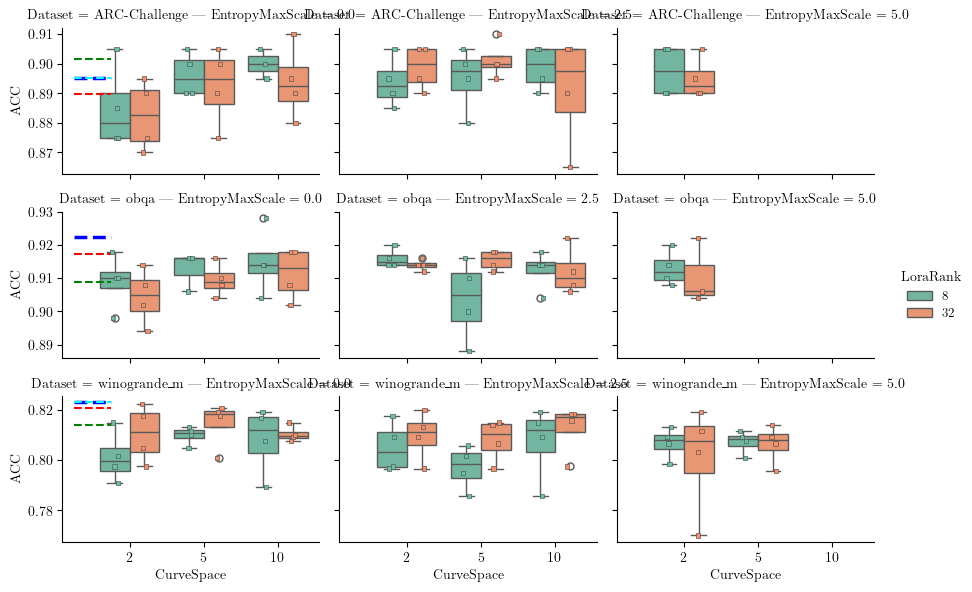

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# hue_order = df_subset['LoraRank'].unique()
# hue_order.sort()

g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='LoraRank', kind='box', row='Dataset', col='EntropyMaxScale', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['EntropyMaxScale'] == float(entropy_scale))],
            x='CurveSpace',
            y='acc',
            hue='LoraRank',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            # hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1266641/3045797890.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/3045797890.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/3045797890.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/3045797890.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/3045797890.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/3045797890.py:23: FutureWarning: Use "auto" to set automatic grayscale c

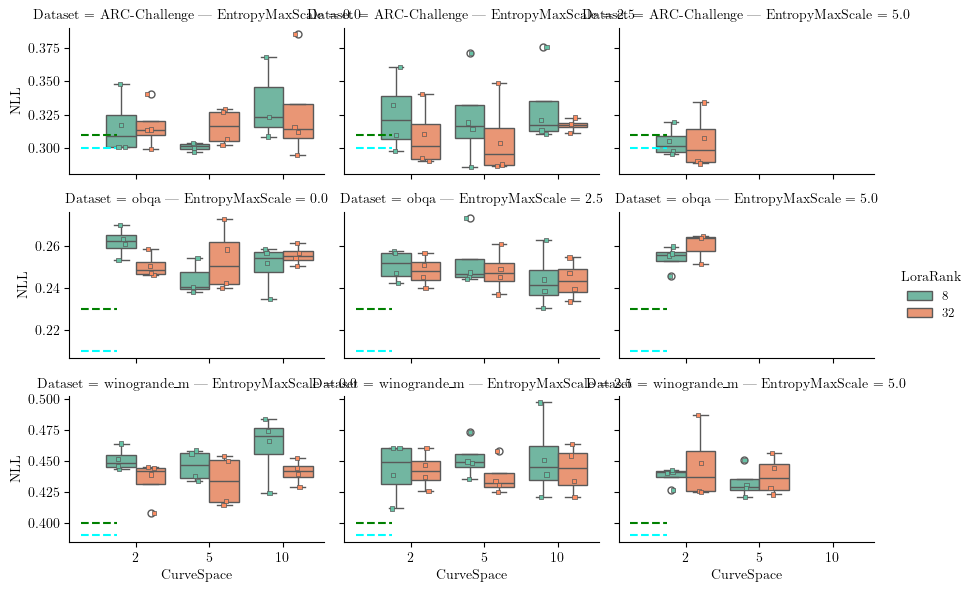

In [8]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='LoraRank', kind='box', row='Dataset', col='EntropyMaxScale', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['EntropyMaxScale'] == float(entropy_scale))],
        x='CurveSpace',
        y='nll',
        hue='LoraRank',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        # hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1266641/2079758068.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2079758068.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2079758068.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2079758068.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2079758068.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1266641/2079758068.py:18: FutureWarning: Use "auto" to set automatic grayscale c

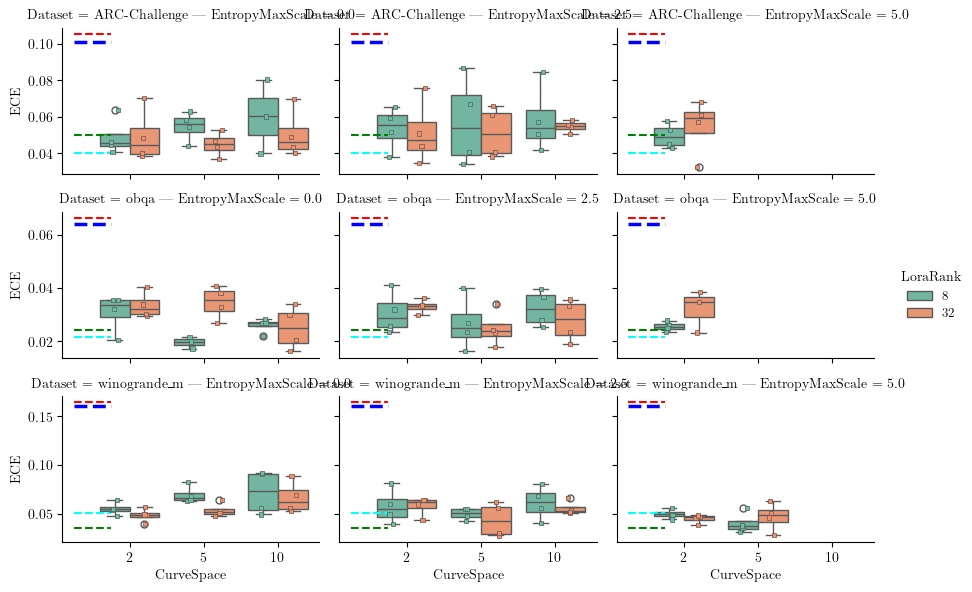

In [9]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='LoraRank', kind='box', row='Dataset', col='EntropyMaxScale', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, legend=True, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['EntropyMaxScale'] == float(entropy_scale))],
        x='CurveSpace',
        y='ece',
        hue='LoraRank',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        # hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['CurveSpace'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# After plotting, add legend to last axis
# g.axes.flat[-1].legend(title='EntropyMaxScale', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust legend placement if needed
g.tight_layout()

### miniBatch with SAM optimizer


In [4]:
api = wandb.Api()
results = []

for s in ["1jvyoge1",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            SamRho=run.config['curve_params']['optimizer_conf']['kwargs'].get('adv_rho', 0.),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            SamRho=run.config['curve_params']['optimizer_conf']['kwargs'].get('adv_rho', 0.),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

df = pd.DataFrame(results)
df.head()

1jvyoge1: 100%|██████████| 24/24 [00:00<00:00, 561.54it/s, gallant-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,EnergyWeakening,SamRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,wwk7ga9d,2,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,1,0.01,23.862017,0.895,0.071248,0.356710,0.160776,0.008884,0.016995,0.151792
1,wwk7ga9d,2,0,8,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,1,0.01,23.862017,0.895,0.071256,0.356816,-inf,-inf,0.016995,0.151792
2,4fj3g8n3,2,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,1,0.01,23.901299,0.875,0.045115,0.343498,0.292478,0.005936,0.036045,0.287423
3,4fj3g8n3,2,0,4,0.01,ARC-Challenge,mean,minibatch,classic,-1,...,1,0.01,23.901299,0.875,0.053006,0.343208,-inf,-inf,0.036045,0.287423
4,vmxjhvuk,2,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,-1,...,1,0.01,24.047050,0.895,0.041836,0.299593,0.298440,0.002011,0.014633,0.296517


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,SamRho,,,,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa']
Metric ['ppd' 'mean']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['As(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
SamRho [0.01 0.05 0.1 ]

Experiment differs in ['Dataset', 'Metric', 'SamRho'] configs


array(['ARC-Challenge', 'obqa'], dtype=object)

#### acc compare Entropy Scale

In [7]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','SamRho',])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       SamRho                             
ARC-Challenge 0.01    0.88500  0.328467  0.052676
              0.05    0.88750  0.339020  0.052023
              0.10    0.88875  0.357703  0.051716
obqa          0.01    0.91300  0.245143  0.024064
              0.05    0.91050  0.250876  0.023089
              0.10    0.90500  0.257464  0.028919

Dataset = ARC-Challenge | RegularizationMode = False
ARC-Challenge
Dataset = obqa | RegularizationMode = False
obqa


/tmp/ipykernel_1274613/2796756906.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2796756906.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


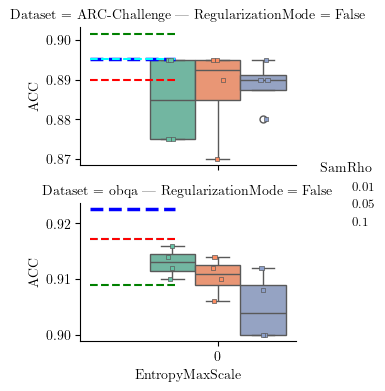

In [8]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['SamRho'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='EntropyMaxScale', y='acc', hue='SamRho', kind='box', row='Dataset', col='RegularizationMode', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds)],
            # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['RegularizationMode'] == entropy_scale)],
            x='EntropyMaxScale',
            y='acc',
            hue='SamRho',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1274613/3828360125.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3828360125.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


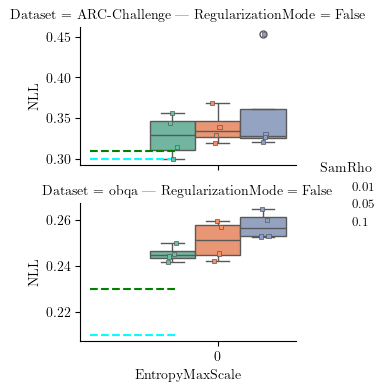

In [9]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='EntropyMaxScale', y='nll', hue='SamRho', kind='box', row='Dataset', col='RegularizationMode', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['RegularizationMode'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='EntropyMaxScale',
        y='nll',
        hue='SamRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1274613/3261711110.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3261711110.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


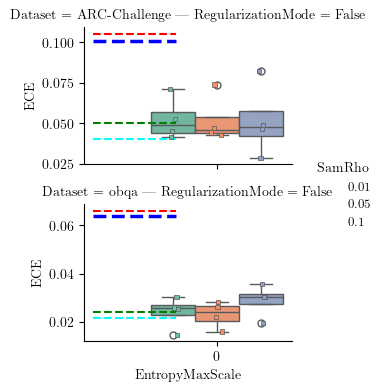

In [10]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='EntropyMaxScale', y='ece', hue='SamRho', kind='box', row='Dataset', col='RegularizationMode', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        # data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['RegularizationMode'] == entropy_scale)],
        data=df_subset[(df_subset['Dataset'] == ds)],
        x='EntropyMaxScale',
        y='ece',
        hue='SamRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### miniBatch with cosine/force regularisation


In [11]:
api = wandb.Api()
results = []

for s in ["3ztjax2e",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=run.config['curve_params']['k'],
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="mean",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_mean_acc", 0),
            ece=run.summary.get(f"post_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

df = pd.DataFrame(results)
df.head()

3ztjax2e:   0%|          | 0/142 [00:00<?, ?it/s, clean-sweep-133]    

3ztjax2e:  29%|██▉       | 41/142 [00:00<00:00, 345.55it/s, gallant-sweep-73]  

Skipping sunny-sweep-142 because it is not finished
Skipping colorful-sweep-141 because it is not finished
Skipping kind-sweep-140 because it is not finished
Skipping absurd-sweep-139 because it is not finished
Skipping glorious-sweep-138 because it is not finished
Skipping graceful-sweep-137 because it is not finished
Skipping expert-sweep-102 because it is not finished


3ztjax2e: 100%|██████████| 142/142 [00:00<00:00, 322.02it/s, deep-sweep-1]          


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,...,Gravity,EnergyWeakening,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,uqdoxcs6,2,0,8,0.01,winogrande_m,ppd,minibatch,classic,-1,...,10.0,0.1,25.790421,0.809167,0.040768,0.438585,0.383885,0.005632,0.006523,0.378326
1,uqdoxcs6,2,0,8,0.01,winogrande_m,mean,minibatch,classic,-1,...,10.0,0.1,25.790421,0.809167,0.040184,0.438562,-inf,-inf,0.006523,0.378326
2,1ocn7k4r,2,0,4,0.01,winogrande_m,ppd,minibatch,classic,-1,...,10.0,0.1,26.260956,0.820833,0.043741,0.423749,0.349840,0.011776,0.003895,0.338065
3,1ocn7k4r,2,0,4,0.01,winogrande_m,mean,minibatch,classic,-1,...,10.0,0.1,26.260956,0.820833,0.043741,0.423748,-inf,-inf,0.003895,0.338065
4,r4yjcr5e,2,0,2,0.01,winogrande_m,ppd,minibatch,classic,-1,...,10.0,0.1,26.247356,0.807500,0.054785,0.435435,0.326304,0.007437,0.004740,0.318864


In [12]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,,,,,,


In [13]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa']
Metric ['ppd' 'mean']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [5 0]
NumSteps [5000]
LoraMode ['As(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode ['force' 'cosine']
Gravity [10.   1.   0.1]
EnergyWeakening [0.1]

Experiment differs in ['Dataset', 'Metric', 'EntropyMaxScale', 'RegularizationMode', 'Gravity'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [14]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','RegularizationMode', 'CurveSpace', 'Gravity', 'EntropyMaxScale'])[['acc', 'nll', 'ece']].mean()

acc  \
Dataset       RegularizationMode CurveSpace Gravity EntropyMaxScale             
ARC-Challenge cosine             2          0.1     0                0.888750   
                                                    5                0.888750   
                                            1.0     0                0.888750   
                                                    5                0.887500   
                                            10.0    0                0.881250   
                                                    5                0.882500   
              force              2          0.1     0                0.882500   
                                                    5                0.888750   
                                            1.0     0                0.883750   
                                                    5                0.891250   
                                            10.0    0                0.885000   
obqa          cosine             2          0.1     0                0.909500   
                                                    5                0.912000   
                                            1.0     0                0.913000   
                                                    5                0.920000   
                                            10.0    0                0.909000   
                                                    5                0.912500   
              force              2          0.1     0                0.918000   
                                                    5                0.911500   
                                            1.0     0                0.913500   
                                                    5                0.911000   
                                            10.0    0                0.915500   
winogrande_m  cosine             2          0.1     0                0.811875   
                                                    5                0.810208   
                                            1.0     0                0.812292   
                                                    5                0.812917   
                                            10.0    0                0.811667   
                                                    5                0.806250   
              force              2          0.1     0                0.810208   
                                                    5                0.814167   
                                            1.0     0                0.808125   
                                                    5                0.813958   
                                            10.0    0                0.811667   
                                                    5                0.813333   

                                                                          nll  \
Dataset       RegularizationMode CurveSpace Gravity EntropyMaxScale             
ARC-Challenge cosine             2          0.1     0                0.333826   
                                                    5                0.327305   
                                            1.0     0                0.347037   
                                                    5                0.328014   
                                            10.0    0                0.324334   
                                                    5                0.325601   
              force              2          0.1     0                0.352420   
                                                    5                0.329855   
                                            1.0     0                0.325333   
                                                    5                0.335133   
                                            10.0    0                0.325992   
obqa          cosine             2          0.1     0                0.256121   
                       

/tmp/ipykernel_1274613/3847030872.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3847030872.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3847030872.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3847030872.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3847030872.py:24: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/3847030872.py:24: FutureWarning: Use "auto" to set automatic grayscale c

Dataset = ARC-Challenge | RegularizationMode = force
ARC-Challenge
Dataset = obqa | RegularizationMode = force
obqa
Dataset = winogrande_m | RegularizationMode = force
winogrande_m


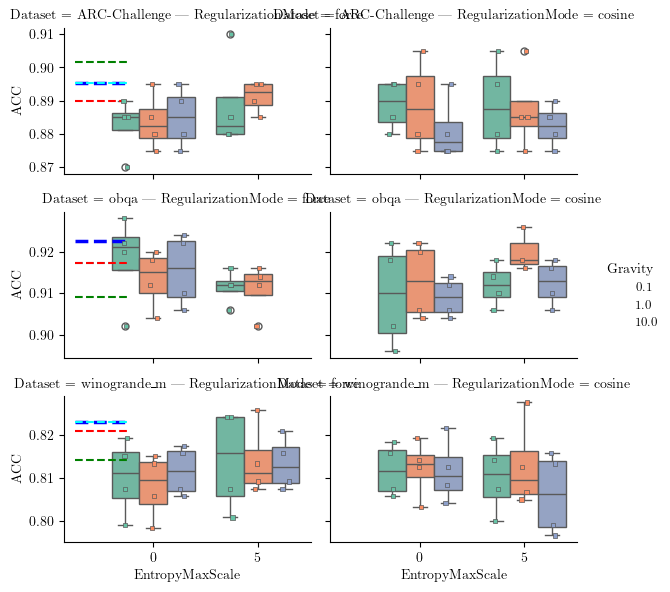

In [15]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['Gravity'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='EntropyMaxScale', y='acc', hue='Gravity', kind='box', row='Dataset', col='RegularizationMode', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['RegularizationMode'] == entropy_scale)],
            x='EntropyMaxScale',
            y='acc',
            hue='Gravity',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1274613/2668146812.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2668146812.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2668146812.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2668146812.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2668146812.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2668146812.py:23: FutureWarning: Use "auto" to set automatic grayscale c

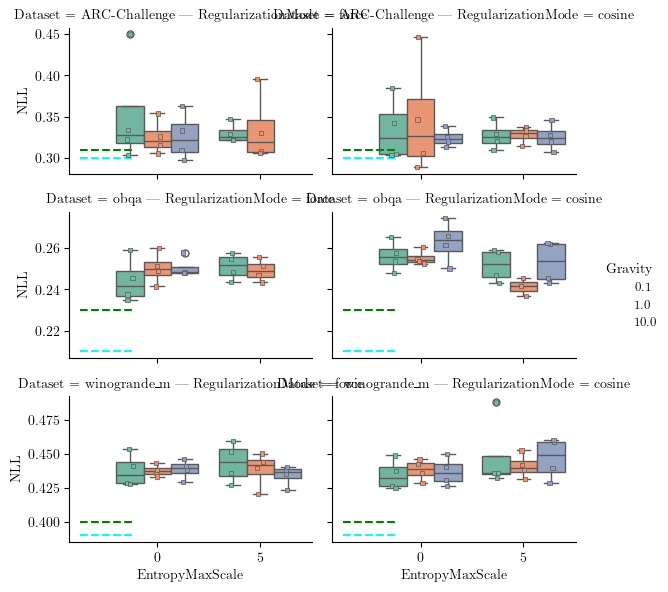

In [16]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='EntropyMaxScale', y='nll', hue='Gravity', kind='box', row='Dataset', col='RegularizationMode', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['RegularizationMode'] == entropy_scale)],
        x='EntropyMaxScale',
        y='nll',
        hue='Gravity',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_1274613/2879950647.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2879950647.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2879950647.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2879950647.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2879950647.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1274613/2879950647.py:18: FutureWarning: Use "auto" to set automatic grayscale c

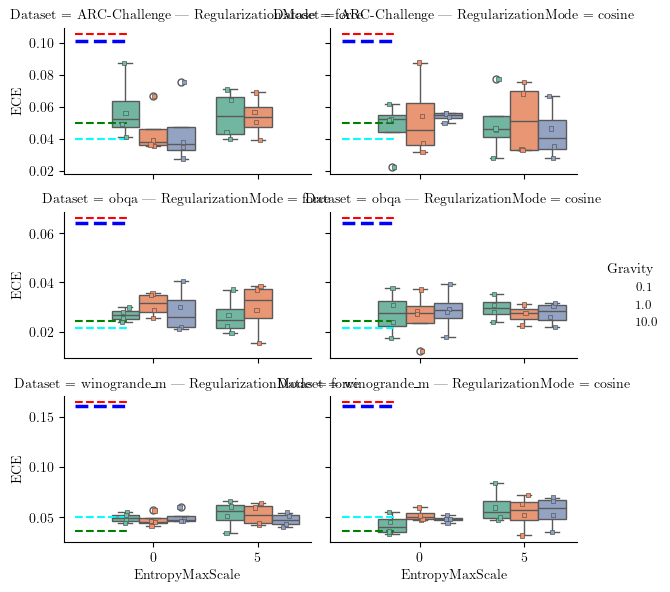

In [17]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='EntropyMaxScale', y='ece', hue='Gravity', kind='box', row='Dataset', col='RegularizationMode', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['RegularizationMode'] == entropy_scale)],
        x='EntropyMaxScale',
        y='ece',
        hue='Gravity',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### ScalaBL Sigma change

In [3]:

run = wandb.Api().run("ddold/ScalaBL-Qwen7B-id/z9xv6quk")
run.summary.keys()

dict_keys(['_runtime', '_step', '_timestamp', '_wandb', 'all_keys_names', 'elbo_loss', 'kl_loss', 'lm_head.lora_A.default.log_s_sigma', 'lr', 'model.layers.0.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.0.self_attn.v_proj.lora_A.default.log_s_sigma', 'model.layers.1.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.1.self_attn.v_proj.lora_A.default.log_s_sigma', 'model.layers.10.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.10.self_attn.v_proj.lora_A.default.log_s_sigma', 'model.layers.11.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.11.self_attn.v_proj.lora_A.default.log_s_sigma', 'model.layers.12.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.12.self_attn.v_proj.lora_A.default.log_s_sigma', 'model.layers.13.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.13.self_attn.v_proj.lora_A.default.log_s_sigma', 'model.layers.14.self_attn.q_proj.lora_A.default.log_s_sigma', 'model.layers.14.self_attn.v_proj.lora_A.de

In [24]:
all_log_scale_names = [k for k in  run.summary.keys() if 'log_s_sigma' in k]
all_log_scale_names

['lm_head.lora_A.default.log_s_sigma',
 'model.layers.0.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.0.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.1.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.1.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.10.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.10.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.11.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.11.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.12.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.12.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.13.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.13.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.14.self_attn.q_proj.lora_A.default.log_s_sigma',
 'model.layers.14.self_attn.v_proj.lora_A.default.log_s_sigma',
 'model.layers.15.self_attn.q_proj.lora_A.default.log_s_sigma',
 'mod

Text(0, 0.5, 'sigma values of VI dist')

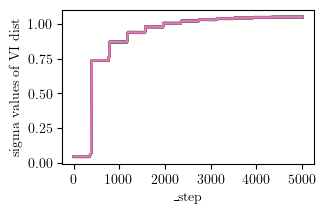

In [29]:
df = run.history()
df_subset = df.loc[:, ['_step', *all_log_scale_names]]
# df_subset.pivot(index='_step', ).plot()
# df_subset.groupby('_step').mean()
df_subset.plot(x='_step', legend=False,)
plt.ylabel('sigma values of VI dist')

<Axes: xlabel='_step'>

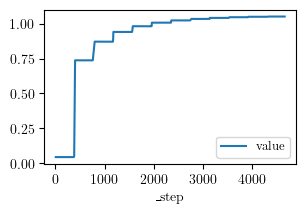

In [21]:
df_subset.melt(id_vars='_step')[['_step', 'value']].groupby('_step').mean().plot()


### VI vs DE vs MLE vs Curve


In [126]:
api = wandb.Api()
results = []

for s in ["0zkos614",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["unb6x3vq",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        # bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

100%|██████████| 24/24 [00:00<00:00, 3069.94it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]

Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,dnjchqms,Curve,6,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.900,0.056942,0.337576
1,v6cifdaz,Curve,6,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.885,0.057138,0.332405
2,6emdndh6,Curve,6,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.900,0.049955,0.309974
3,vc1q3re4,Curve,6,0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.885,0.038748,0.317836
4,2owl9jlu,Curve,6,0,8,0.01,obqa,ppd,minibatch,classic,...,5000,As(t)B,Bezier,8,False,0,1,0.902,0.032790,0.270770


In [127]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [128]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve' 'MLE' 'DE' 'ScalaBL']
DegFreedom [ 6  3  1 10]
Jitter [ 0 -1]
Seed [8 4 2 1 0 7 6]
WeightDecay [ 0.01 -1.  ]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'ARC-Easy']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['As(t)B' 'A(t)B' 'AsB']
CurveMode ['Bezier' -1]
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]

Experiment differs in ['Model', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [129]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model   DegFreedom                              
ARC-Challenge Curve   3           0.883750  0.337572  0.048529
                      6           0.892500  0.324448  0.050696
              DE      3           0.901250  0.300610  0.525800
                      6           0.898750  0.301807  0.524635
                      10          0.895000  0.298854  0.519306
              MLE     1           0.886250  0.326249  0.060490
              ScalaBL 1           0.902027  0.297852  0.041976
obqa          Curve   3           0.915000  0.244980  0.028358
                      6           0.906000  0.264976  0.029702
              DE      3           0.917500  0.228231  0.469771
                      6           0.920500  0.222564  0.472848
                      10          0.923500  0.223299  0.475908
              MLE     1           0.917000  0.244404  0.024823
              ScalaBL 1           0.915000  0.224854  0.023838
winogrande_m  Curve   3           0.804583  0.437815  0.038768
                      6           0.811042  0.435443  0.040568
              DE      3           0.828125  0.395557  0.167246
                      6           0.825625  0.396008  0.168026
                      10          0.828542  0.391048  0.168740
              MLE     1           0.811250  0.434169  0.062158
              ScalaBL 1           0.816653  0.393066  0.038685

In [130]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

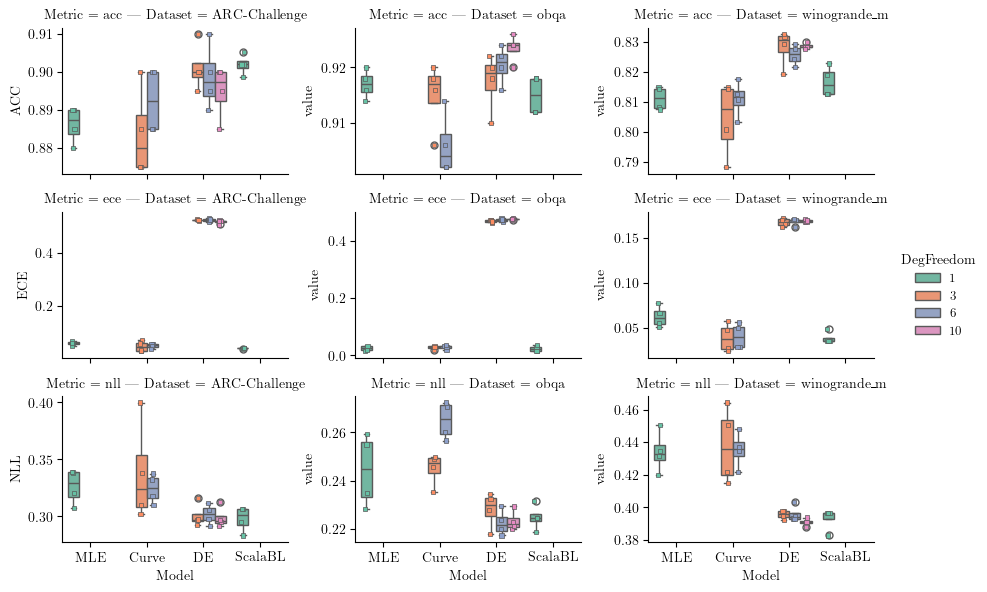

In [131]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1305911/301518286.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
/tmp/ipykernel_1305911/301518286.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


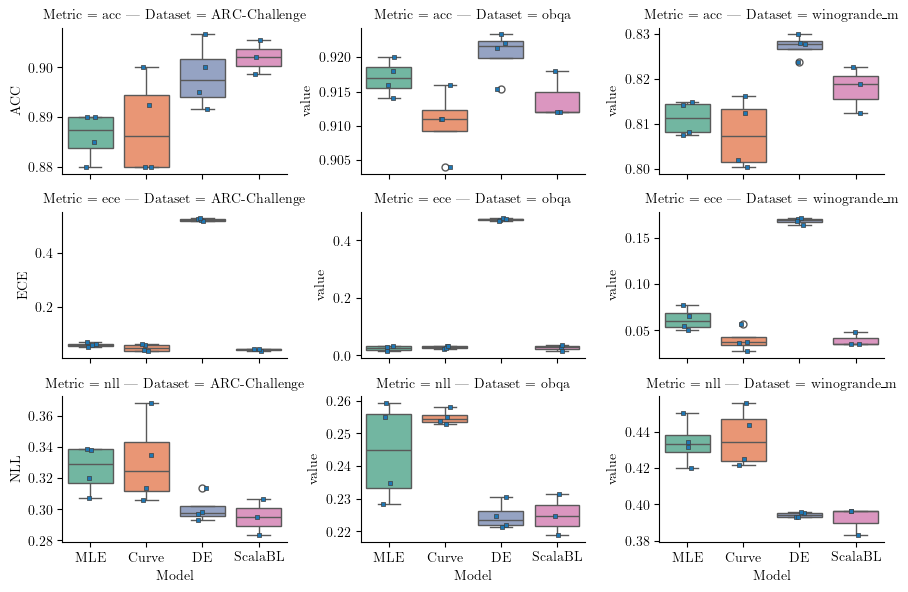

In [132]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


### DE vs MLE vs Curve LastLayer


In [7]:
api = wandb.Api()
results = []

for s in ["75rfrghb",]: # MLE/ Curve 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["h23dngln",]: # DE 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

# t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))  # VI
# for run in t_run:
#     if run.state != 'finished':
#         print(f"Skipping {run.name} because it is not finished")
#         continue
#     t_run.set_postfix_str(run.name)
#     res = dict(Id=run.id,
#     #    CurveSpace=f"{run.config['curve_params']['k']}",
#         Model="ScalaBL",
#         DegFreedom=1,
#         Jitter=-1,
#         Seed=run.config['seed'],
#         WeightDecay=-1,
#         Dataset=run.config['dataset'],
#         Metric="ppd",
#         DS_Sampling=-1,
#         DS_Mode="minibatch",
#         DS_WindowSize=-1,
#         EntropyMaxScale=-1,
#         NumSteps=run.config['max_train_steps'],
#         LoraMode="AsB",
#         CurveMode=-1,
#         LoraRank=run.config['lora_r'],
#         RegularizationMode=False,
#         Gravity=-1,
#         EnergyWeakening=-1,
#         # bezierLength=run.summary.get('Curve length', 0),
#         acc=run.summary.get(f"final_val_acc", 0),
#         ece=run.summary.get(f"final_val_ece", 0),
#         nll=run.summary.get(f"final_val_nll", 0),
#         # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
#         # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
#         # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
#         # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
#         )
#     results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

h23dngln: 100%|██████████| 24/24 [00:00<00:00, 405.78it/s, silvery-sweep-1]


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,d2gi42pg,Curve,11,0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.865,0.081726,0.371704
1,g5xmrxhl,Curve,11,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.865,0.078302,0.393052
2,29nk3v0u,Curve,11,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.870,0.065190,0.379998
3,vxxcxghh,Curve,11,0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.880,0.069842,0.380754
4,su551tix,Curve,11,0,8,0.01,obqa,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.802,0.047414,0.551782


In [8]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [9]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve' 'MLE' 'DE']
DegFreedom [11  3  1]
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch' 'None']
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'A(t)B']
CurveMode ['bezier' 'Bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]

Experiment differs in ['Model', 'DegFreedom', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [10]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model DegFreedom                              
ARC-Challenge Curve 3           0.870000  0.383498  0.065959
                    11          0.870000  0.381377  0.073765
              DE    3           0.870000  0.385231  0.050016
                    11          0.865000  0.386557  0.057081
              MLE   1           0.868750  0.381289  0.054782
obqa          Curve 3           0.803500  0.550943  0.045428
                    11          0.805000  0.554501  0.049878
              DE    3           0.803000  0.547115  0.046295
                    11          0.799000  0.546804  0.047256
              MLE   1           0.803500  0.553559  0.037412
winogrande_m  Curve 3           0.618333  0.652108  0.097277
                    11          0.622292  0.654264  0.104990
              DE    3           0.616042  0.648842  0.095807
                    11          0.622083  0.651048  0.094373
              MLE   1           0.614167  0.650929  0.098602

In [11]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

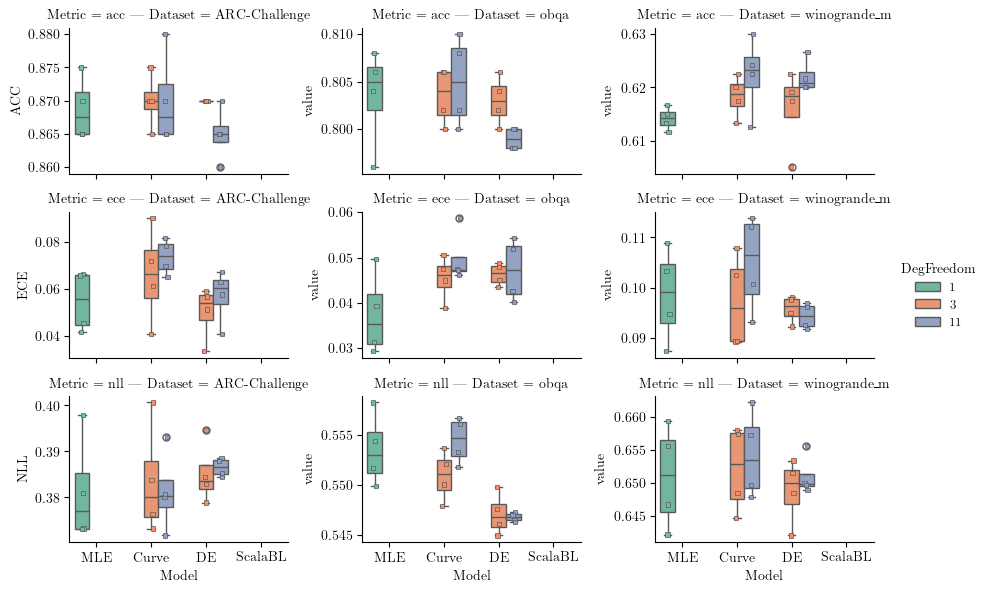

In [12]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_1315295/301518286.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
/tmp/ipykernel_1315295/301518286.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


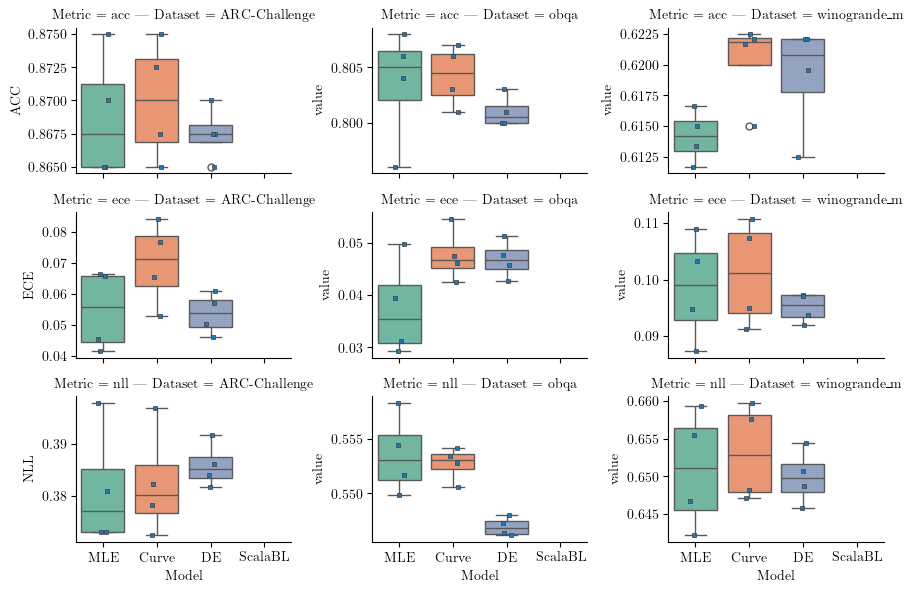

In [13]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
g.tight_layout()


### FixedPoints compare with VI vs DE vs MLE vs Curve


In [27]:
api = wandb.Api()
results = []

for s in ["20h06muz",]: # Fixed Control Points training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="Curve (Fixed CP)",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

for s in ["0zkos614",]: # Curve training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["unb6x3vq",]: # think DE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            # bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))  # ScalaBL
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        # bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

    

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

20h06muz:   0%|          | 0/22 [00:00<?, ?it/s, summer-sweep-16]  

20h06muz: 100%|██████████| 22/22 [00:00<00:00, 588.74it/s, old_rare-sweep-17]


Skipping northern-sweep-22 because it is not finished
Skipping charmed-sweep-21 because it is not finished
Skipping hopeful-sweep-20 because it is not finished
Skipping mild-sweep-19 because it is not finished
Skipping deft-sweep-18 because it is not finished
Skipping trim-sweep-17 because it is not finished
Skipping super-sweep-14 because it is not finished
Skipping fancy-sweep-10 because it is not finished
Skipping solar-sweep-8 because it is not finished
Skipping noble-sweep-9 because it is not finished
Skipping blooming-sweep-7 because it is not finished


100%|██████████| 24/24 [00:00<00:00, 2652.17it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]

Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


,Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,acc,ece,nll
0,krunuar4,Curve (Fixed CP),5,0,2,0.01,winogrande_m,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.817500,0.070572,0.443597
1,zs9b9kkz,Curve (Fixed CP),5,0,1,0.01,winogrande_m,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.825833,0.045821,0.422287
2,7zy93yic,Curve (Fixed CP),3,0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.905000,0.064303,0.325918
3,bzdpp3b5,Curve (Fixed CP),3,0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.880000,0.056563,0.342657
4,xsaslzma,Curve (Fixed CP),3,0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,5000,A(t)B(t),bezier,8,False,0,1,0.890000,0.049050,0.318249


In [28]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,acc,ece,nll
Id,Model,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,,,


In [29]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve (Fixed CP)' 'Curve' 'MLE' 'DE' 'ScalaBL']
DegFreedom [ 5  3  6  1 10]
Jitter [ 0 -1]
Seed [2 1 4 8 0 7 6]
WeightDecay [ 0.01 -1.  ]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa' 'winogrande_s' 'ARC-Easy']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'As(t)B' 'A(t)B' 'AsB']
CurveMode ['bezier' 'Bezier' -1]
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]

Experiment differs in ['Model', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [30]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model            DegFreedom                              
ARC-Challenge Curve            3           0.883750  0.337572  0.048529
                               6           0.892500  0.324448  0.050696
              Curve (Fixed CP) 3           0.891667  0.328941  0.056639
              DE               3           0.901250  0.300610  0.525800
                               6           0.898750  0.301807  0.524635
                               10          0.895000  0.298854  0.519306
              MLE              1           0.886250  0.326249  0.060490
              ScalaBL          1           0.902027  0.297852  0.041976
obqa          Curve            3           0.915000  0.244980  0.028358
                               6           0.906000  0.264976  0.029702
              Curve (Fixed CP) 5           0.914000  0.256374  0.038858
              DE               3           0.917500  0.228231  0.469771
                               6           0.920500  0.222564  0.472848
                               10          0.923500  0.223299  0.475908
              MLE              1           0.917000  0.244404  0.024823
              ScalaBL          1           0.915000  0.224854  0.023838
winogrande_m  Curve            3           0.804583  0.437815  0.038768
                               6           0.811042  0.435443  0.040568
              Curve (Fixed CP) 3           0.816250  0.478852  0.090298
                               5           0.821667  0.432942  0.058197
              DE               3           0.828125  0.395557  0.167246
                               6           0.825625  0.396008  0.168026
                               10          0.828542  0.391048  0.168740
              MLE              1           0.811250  0.434169  0.062158
              ScalaBL          1           0.816653  0.393066  0.038685

In [31]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset'], var_name="Metric")

model_order = ['MLE', 'Curve', 'Curve (Fixed CP)', 'DE', 'ScalaBL']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

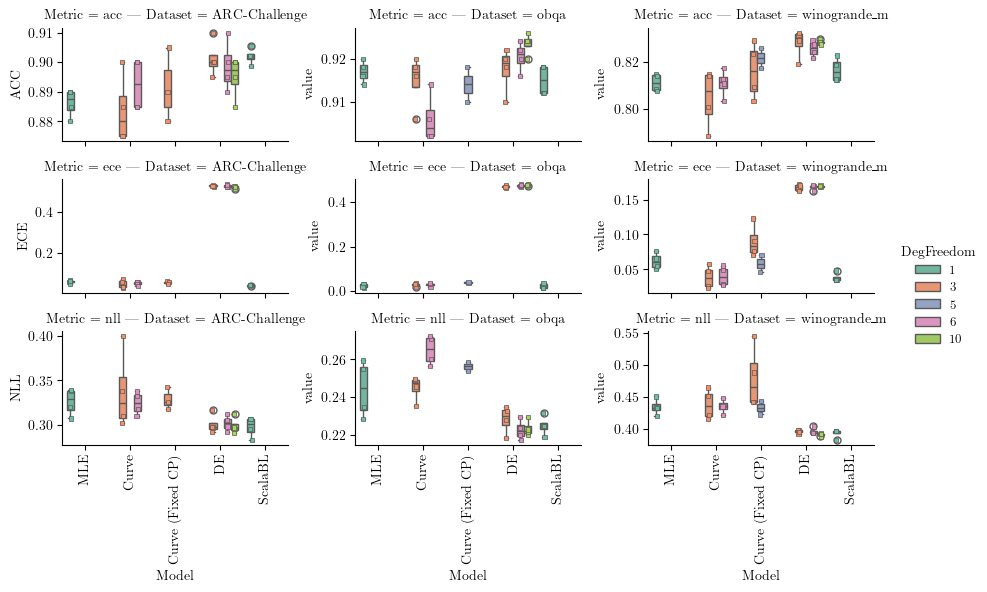

In [32]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
# rotate x tick labels for all subplots
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=90)
g.tight_layout()


/tmp/ipykernel_1334156/2015359192.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


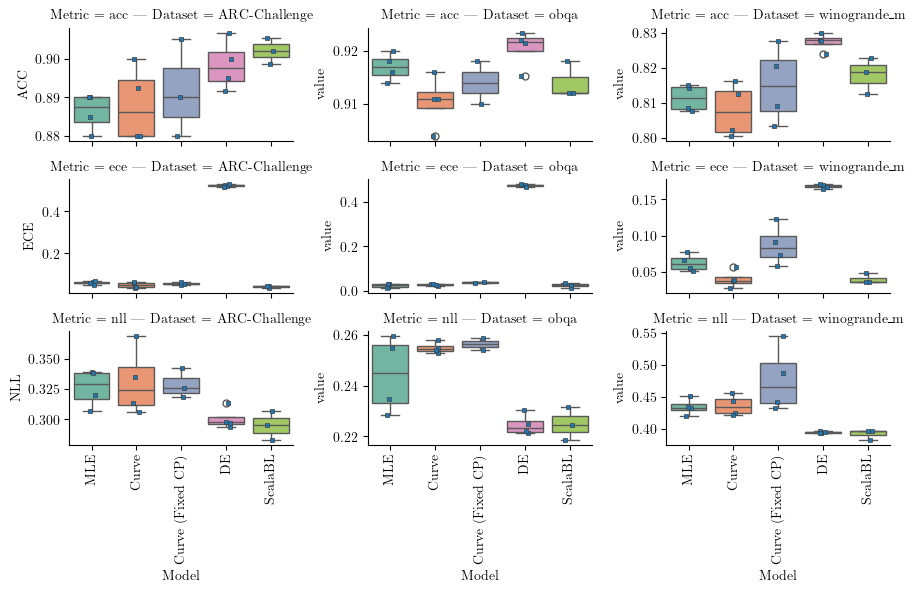

In [33]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric'], observed=False).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
# rotate x tick labels for all subplots
for ax in g.axes.flat:
    ax.tick_params(axis='x', rotation=90)
g.tight_layout()


### Compare loss landscape

In [ ]:
umeb6pa2

In [7]:
from wandb import Api

api = Api()
run = api.run("ddold/qwen_PtoC/5hgtjsd6")
run.summary.get(f"Curve Predictive Train", 0)

{'_type': 'image-file', 'format': 'png', 'height': 300, 'path': 'media/images/Curve Predictive Train_11031_71c12f2fb5903dfea4dc.png', 'sha256': '71c12f2fb5903dfea4dc9b50da0b02a354306cb7303173fad0cd733097dd5016', 'size': 24902, 'width': 400}

### Curve per leave 


In [43]:
api = wandb.Api()
results = []

for s in ["umeb6pa2",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0),
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0),
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0),
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf),
            )
        results.append(res)

for s in ["zbdorvq8",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)    
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf),
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf),
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf),
            )
        results.append(res)
df = pd.DataFrame(results)
df.head()

zbdorvq8: 100%|██████████| 24/24 [00:00<00:00, 399.94it/s, confused-sweep-2]


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,EnergyWeakening,Tsample,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,vzdda6hu,6,"[0, 0, 0, 0, 0, 0]",0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,35.288780,0.910,0.049384,0.299048,0.345555,0.013379,0.007814,0.332175
1,6rxbmzj7,6,"[0, 0, 0, 0, 0, 0]",0,4,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,35.690102,0.910,0.034357,0.283648,0.332553,0.015483,0.007000,0.317071
2,7n0sjx0s,6,"[0, 0, 0, 0, 0, 0]",0,2,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,36.289398,0.890,0.071027,0.381386,0.208612,0.023940,0.010940,0.184672
3,4wuzzqxt,6,"[0, 0, 0, 0, 0, 0]",0,1,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,35.023643,0.880,0.040297,0.335218,0.310160,0.007615,0.005794,0.302545
4,p3whhn0m,6,"[0, 0, 0, 0, 0, 0]",0,8,0.01,ARC-Challenge,ppd,minibatch,classic,...,1,per_leaf,24.733397,0.885,0.039292,0.320283,0.319459,0.003807,0.004902,0.315652


In [44]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,,,,,,,,


In [45]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [6 3]
CpFix ['[0, 0, 0, 0, 0, 0]' '[0, 0, 0]']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'As(t)B' 'Asd(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leaf' 'combined']

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'LoraMode', 'Tsample'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [46]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       LoraMode CurveSpace Tsample                               
ARC-Challenge A(t)B(t) 3          per_leaf  0.907500  0.303390  0.058632
                       6          per_leaf  0.897500  0.324825  0.048766
              As(t)B   3          per_leaf  0.892500  0.319242  0.051929
                       6          per_leaf  0.882500  0.323127  0.046199
              Asd(t)B  3          combined  0.892500  0.321465  0.047275
                                  per_leaf  0.892500  0.323128  0.044780
obqa          A(t)B(t) 3          per_leaf  0.911000  0.245141  0.029407
                       6          per_leaf  0.913000  0.243792  0.027687
              As(t)B   3          per_leaf  0.912500  0.254035  0.029761
                       6          per_leaf  0.917500  0.251796  0.025687
              Asd(t)B  3          combined  0.913500  0.246888  0.030048
                                  per_leaf  0.914000  0.247020  0.027997
winogrande_m  A(t)B(t) 3          per_leaf  0.799583  0.462981  0.056829
                       6          per_leaf  0.802083  0.463214  0.063532
              As(t)B   3          per_leaf  0.809792  0.452272  0.056209
                       6          per_leaf  0.814167  0.448249  0.060784
              Asd(t)B  3          combined  0.810000  0.444934  0.053675
                                  per_leaf  0.810208  0.446078  0.055203

ARC-Challenge per_leaf
ARC-Challenge combined
obqa per_leaf
obqa combined
winogrande_m per_leaf
winogrande_m combined
Dataset = ARC-Challenge | Tsample = per_leaf
ARC-Challenge
Dataset = obqa | Tsample = per_leaf
obqa
Dataset = winogrande_m | Tsample = per_leaf
winogrande_m


/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/3139429871.py:25: FutureWarning: Use "auto" to set automatic grayscale colors. From 

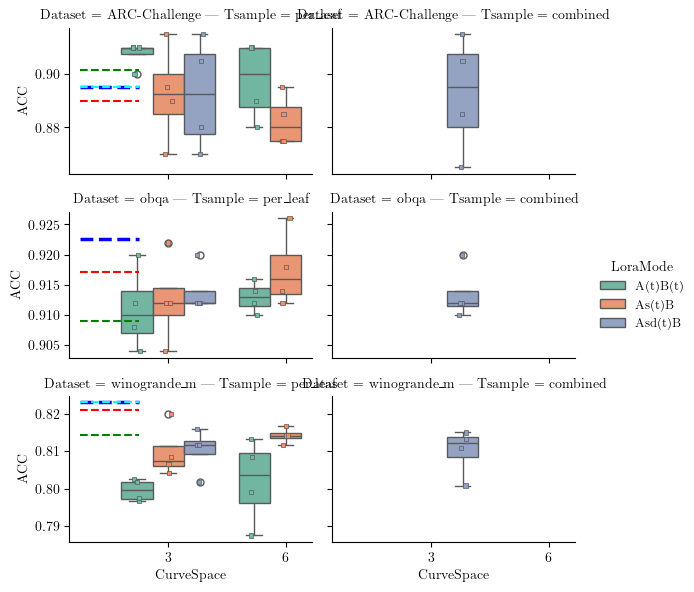

In [47]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['CurveSpace']==0]
hue_order = df_subset['LoraMode'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='CurveSpace', y='acc', hue='LoraMode', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            x='CurveSpace',
            y='acc',
            hue='LoraMode',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/73135356.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gr

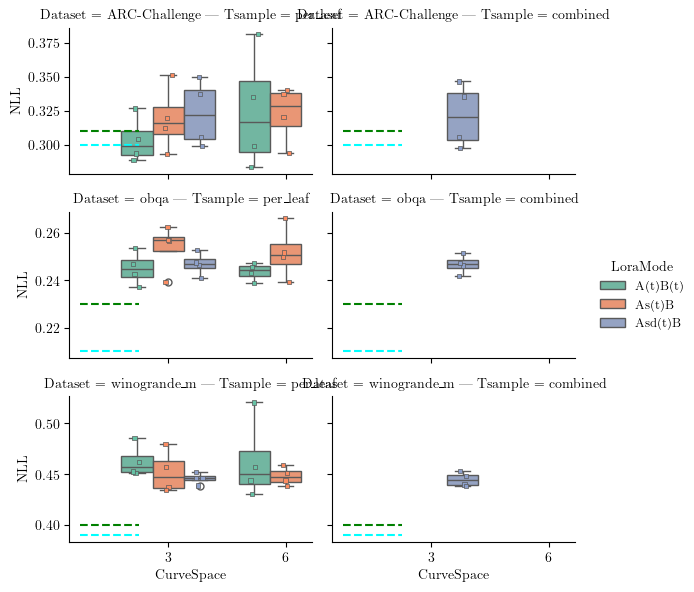

In [48]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='CurveSpace', y='nll', hue='LoraMode', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='CurveSpace',
        y='nll',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_12870/4214643291.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

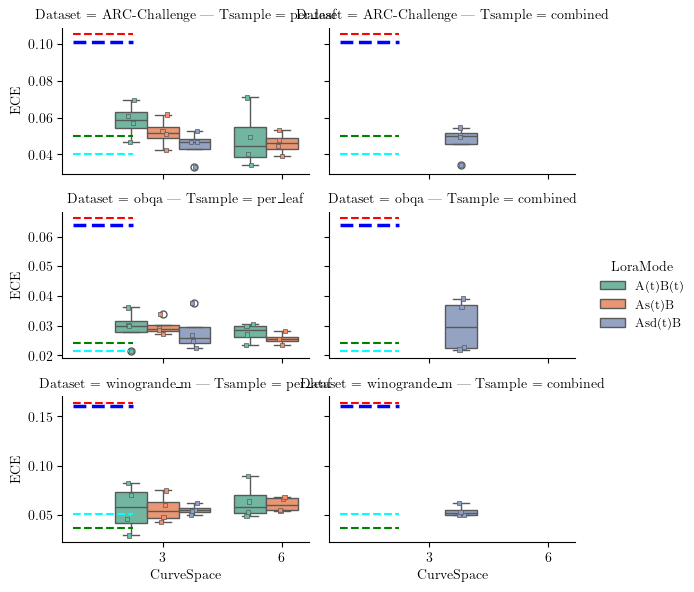

In [49]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='CurveSpace', y='ece', hue='LoraMode', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='CurveSpace',
        y='ece',
        hue='LoraMode',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
g.tight_layout()

### Flat-Lora 


In [3]:
api = wandb.Api()
results = []


for s in ["kvfhm79j",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
        
for s in ["r8fcpq9i",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)


for s in ["7mv3szwn",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        space = len(run.config['curve_params']['cp_fix'])
        if space == 1:
            acc=run.summary.get(f"cp_fixed_0_post_pred_test_mean_acc", 0)
            ece=run.summary.get(f"cp_fixed_0_post_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"cp_fixed_0_post_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
                acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
                ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
                nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
            else:
                acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
                ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
                nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            CurveSpace="MLE" if space == 1 else space,
            CpFix=str(run.config['curve_params']['cp_fix']),
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
df = pd.DataFrame(results)
df

r8fcpq9i:  32%|███▏      | 41/128 [00:00<00:00, 272.06it/s, polished-sweep-59]     

Skipping curious-sweep-112 because it is not finished
Skipping fragrant-sweep-111 because it is not finished
Skipping royal-sweep-110 because it is not finished
Skipping amber-sweep-107 because it is not finished
Skipping rare-sweep-101 because it is not finished
Skipping usual-sweep-100 because it is not finished
Skipping smart-sweep-85 because it is not finished


7mv3szwn: 100%|██████████| 48/48 [00:00<00:00, 551.96it/s, resilient-sweep-3]


Skipping crimson-sweep-48 because it is not finished


,Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,...,Tsample,LoraRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,x8ty9syr,3,"[0, 0, 0]",0,8,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.684416,0.604167,0.080447,0.644400,0.609044,0.009803,0.015307,0.599231
1,xppc5kt6,3,"[0, 0, 0]",0,4,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.132126,0.633333,0.117590,0.684474,0.514929,0.001808,0.004257,0.513083
2,2y9nyyo4,3,"[0, 0, 0]",0,2,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.205212,0.629167,0.111882,0.673053,0.520093,0.006122,0.007048,0.513918
3,nvc3xuad,3,"[0, 0, 0]",0,1,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,24.738529,0.623333,0.074753,0.642329,0.597374,0.002587,0.007921,0.594741
4,igymfd89,3,"[0, 0, 0]",0,8,0.01,winogrande_m,ppd,minibatch,classic,...,combined,0.5,25.781818,0.830833,0.060692,0.412952,0.326947,0.019140,0.031155,0.307601
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
243,rgz5er40,MLE,[1],0,8,0.01,winogrande_m,ppd,minibatch,classic,...,combined,0.1,0.000000,0.821667,0.058265,0.427552,-inf,-inf,-inf,-inf
244,px551eaj,MLE,[1],0,2,0.01,winogrande_m,ppd,minibatch,classic,...,combined,0.1,0.000000,0.785833,0.050470,0.461038,-inf,-inf,-inf,-inf
245,gt6ubwkt,MLE,[1],0,1,0.01,winogrande_m,ppd,minibatch,classic,...,combined,1.0,0.000000,0.618333,0.064730,0.636872,-inf,-inf,-inf,-inf
246,dzdpd9xm,MLE,[1],0,2,0.01,winogrande_m,ppd,minibatch,classic,...,combined,10.0,0.000000,0.625833,0.109175,0.700990,-inf,-inf,-inf,-inf


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,CurveSpace,CpFix,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [3 'MLE']
CpFix ['[0, 0, 0]' '[1]']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.01]
Dataset ['winogrande_m' 'ARC-Challenge' 'obqa']
Metric ['ppd']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [0]
NumSteps [5000]
LoraMode ['A(t)B(t)' 'Asd(t)B']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined' 'per_leaf']
LoraRho [ 1.    0.5   0.01  0.05  0.1  10.  ]

Experiment differs in ['CurveSpace', 'CpFix', 'Dataset', 'LoraMode', 'Tsample', 'LoraRho'] configs


array(['ARC-Challenge', 'obqa', 'winogrande_m'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']

df_subset['Config'] = df_subset.apply(lambda row: f"K={row['CurveSpace']} -- LM={row['LoraMode']}", axis=1)
# df_subset = df_subset[df_subset['Tsample'] == 'per_leaf']
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset','LoraMode', 'CurveSpace', 'Tsample', 'LoraRho'])[['acc', 'nll', 'ece']].mean()

acc       nll  \
Dataset       LoraMode CurveSpace Tsample  LoraRho                       
ARC-Challenge A(t)B(t) 3          combined 0.01     0.901250  0.333414   
                                           0.10     0.891250  0.349665   
                                           1.00     0.890000  0.322987   
                                           10.00    0.828750  0.561027   
                                  per_leaf 0.01     0.896250  0.334633   
...                                                      ...       ...   
winogrande_m  Asd(t)B  3          per_leaf 0.01     0.808958  0.459153   
                                           0.05     0.807292  0.456469   
                                           0.10     0.811042  0.447492   
                                           0.50     0.817083  0.436783   
                                           1.00     0.625000  0.663223   

                                                         ece  
Dataset       LoraMode CurveSpace Tsample  LoraRho            
ARC-Challenge A(t)B(t) 3          combined 0.01     0.056095  
                                           0.10     0.056760  
                                           1.00     0.050481  
                                           10.00    0.165513  
                                  per_leaf 0.01     0.050980  
...                                                      ...  
winogrande_m  Asd(t)B  3          per_leaf 0.01     0.065078  
                                           0.05     0.062514  
                                           0.10     0.061477  
                                           0.50     0.069225  
                                           1.00     0.092909  

[64 rows x 3 columns]

ARC-Challenge combined
ARC-Challenge per_leaf
obqa combined
obqa per_leaf
winogrande_m combined


/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


winogrande_m per_leaf


/tmp/ipykernel_37248/3085625595.py:41: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


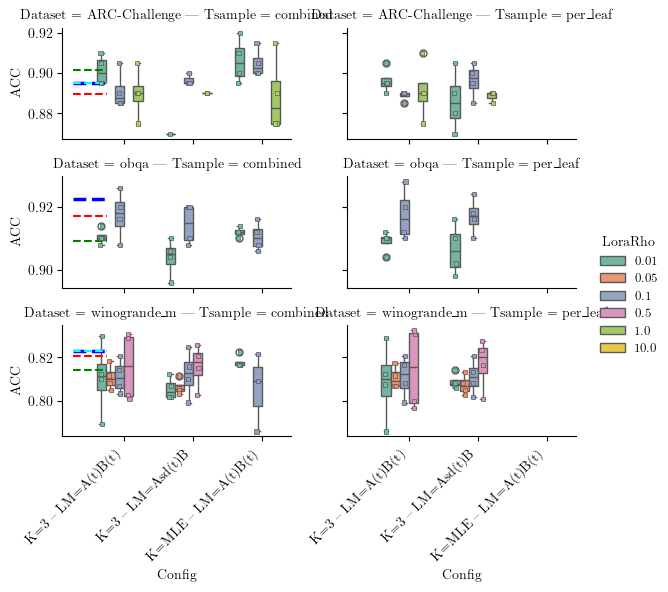

In [7]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

df_subset['LoraRho'] = df_subset['LoraRho'].astype(str)
numeric_rhos = sorted(df_subset['LoraRho'].astype(float).unique())
hue_order = [str(x) for x in numeric_rhos]

# Filter out bad runs with dataset-specific thresholds
min_acc = {
    'ARC-Easy': 0.85,
    'obqa': 0.83,
    'ARC-Challenge': 0.85,
    'boolq': 0.65,
    'winogrande_m': 0.7,
    'winogrande_s': 0.55
}
df_subset = df_subset[df_subset['acc'] > df_subset['Dataset'].map(min_acc).fillna(0)]

# # df_subset = df_subset[df_subset['Config']==0]
# hue_order = list(df_subset['LoraRho'].unique())
# hue_order.sort()
# # hue_order = None
# # hue_order = hue_order[::-1]


g = sns.catplot(data=df_subset, x='Config', y='acc', hue='LoraRho', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        ds = ax.get_title().split('=')[1].split('|')[0].strip()
        entropy_scale = ax.get_title().split('=')[2].strip()
        print(ds, entropy_scale)
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
            x='Config',
            y='acc',
            hue='LoraRho',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='gray',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )
g.set_ylabels('ACC')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_subset['DS_Sampling'].unique())

# Draw horizontal reference lines
for ax in g.axes[:,0].flatten():
    # Each subplot’s dataset name from its title
    # print(ax.get_title())
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    # print(dataset)
    if dataset not in ref_acc:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_acc[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_acc[dataset]['BLoB'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_acc[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_acc[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed
# g.set_xticklabels(rotation=90, ha='center')
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/3782151349.py:23: FutureWarning: Use "auto" to set automatic grayscale colors. From 

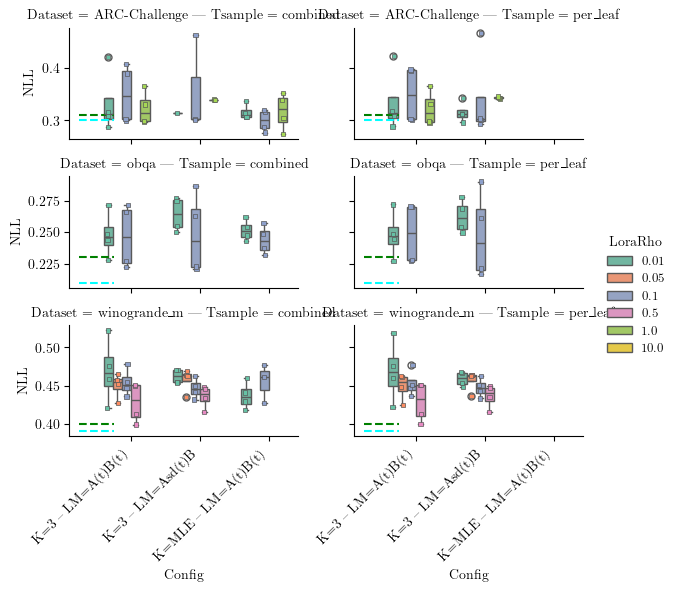

In [8]:
ref_nll = {
    'boolq': {
        'MLE': 0.25, 'MAP': 0.25, 'MC-Dropout': 0.25, 'Ensemble': 0.24, 'Laplace': 0.29, 'BLoB': 0.23, 'ScalaBL': 0.24 },
    'ARC-Easy': {
        'MLE': 0.44, 'MAP': 0.43, 'MC-Dropout': 0.43, 'Ensemble': 0.25, 'Laplace': 0.51, 'BLoB': 0.10, 'ScalaBL': 0.11 },
    'ARC-Challenge': {
        'MLE': 1.05, 'MAP': 1.05, 'MC-Dropout': 1.02, 'Ensemble': 0.75, 'Laplace': 0.80, 'BLoB': 0.30, 'ScalaBL': 0.31 },
    'obqa': {
        'MLE': 0.38, 'MAP': 0.39, 'MC-Dropout': 0.36, 'Ensemble': 0.27, 'Laplace': 0.23, 'BLoB': 0.21, 'ScalaBL': 0.23 },
    'winogrande_s': {
        'MLE': 1.94, 'MAP': 1.88, 'MC-Dropout': 1.90, 'Ensemble': 1.33, 'Laplace': 0.55, 'BLoB': 0.51, 'ScalaBL': 0.51 },
    'winogrande_m': {
        'MLE': 1.20, 'MAP': 1.27, 'MC-Dropout': 1.07, 'Ensemble': 0.74, 'Laplace': 0.44, 'BLoB': 0.39, 'ScalaBL': 0.40 }
}


g = sns.catplot(data=df_subset, x='Config', y='nll', hue='LoraRho', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='Config',
        y='nll',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('NLL')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_nll:
        continue

    tick = -0.5  # categorical position
    # ax.hlines(
    #     y=ref_nll[dataset]['MLE'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='blue',
    #     linestyles='--',
    #     lw=2.5,
    #     label='MLE (WD=0)'
    # )
    ax.hlines(
        y=ref_nll[dataset]['BLoB'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_nll[dataset]['ScalaBL'],
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    # ax.hlines(
    #     y=ref_nll[dataset]['MAP'],
    #     xmin=tick - 0.25,
    #     xmax=tick + 0.25,
    #     colors='red',
    #     linestyles='--',
    #     lw=1.5,
    #     label='MAP (WD=0.01)'
    # )

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_37248/2528788350.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

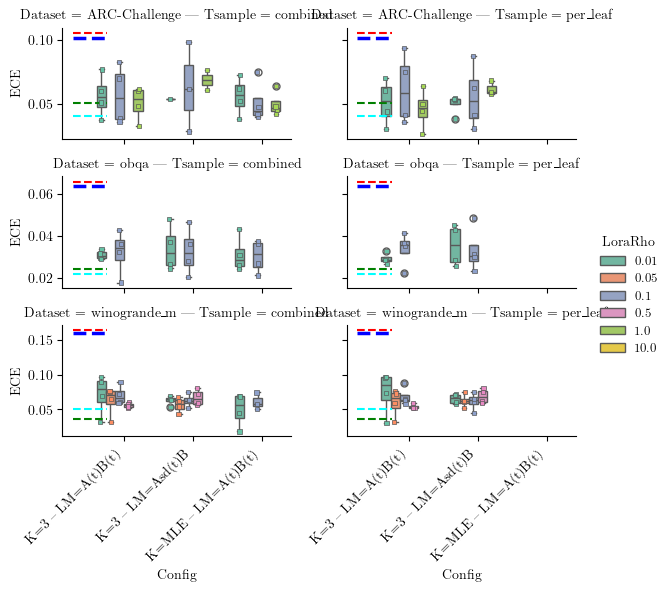

In [9]:
ref_ece = {
    'winogrande_s': { 'MLE': 20.14, 'MAP': 19.99, 'MC-Dropout': 20.15, 'Ensemble': 19.06, 'Laplace': 13.32, 'BLoB': 7.88, 'ScalaBL': 8.88 },
    'ARC-Challenge':{ 'MLE': 10.11, 'MAP': 10.54, 'MC-Dropout': 10.06, 'Ensemble': 10.13, 'Laplace': 37.90, 'BLoB': 4.03, 'ScalaBL': 5.03 },
    'ARC-Easy':     { 'MLE': 4.17, 'MAP': 4.08, 'MC-Dropout': 4.01, 'Ensemble': 3.75, 'Laplace': 33.80, 'BLoB': 1.60, 'ScalaBL': 1.78 },
    'winogrande_m': { 'MLE': 16.10, 'MAP': 16.42, 'MC-Dropout': 15.46, 'Ensemble': 13.65, 'Laplace': 4.81, 'BLoB': 5.08, 'ScalaBL': 3.64 },
    'obqa':         { 'MLE': 6.40, 'MAP': 6.61, 'MC-Dropout': 6.60, 'Ensemble': 4.96, 'Laplace': 1.90, 'BLoB': 2.16, 'ScalaBL': 2.43 },
    'boolq':        { 'MLE': 3.79, 'MAP': 3.81, 'MC-Dropout': 3.88, 'Ensemble': 2.61, 'Laplace': 1.18, 'BLoB': 1.40, 'ScalaBL': 1.96 },
}



g = sns.catplot(data=df_subset, x='Config', y='ece', hue='LoraRho', kind='box', row='Dataset', col='Tsample', sharey='row', palette='Set2', height=figsize[1], row_order=col_order, hue_order=hue_order, aspect=1.5)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].split('|')[0].strip()
    entropy_scale = ax.get_title().split('=')[2].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_subset[(df_subset['Dataset'] == ds) & (df_subset['Tsample'] == entropy_scale)],
        x='Config',
        y='ece',
        hue='LoraRho',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('ECE')

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].split('|')[0].strip()
    if dataset not in ref_ece:
        continue

    tick = -0.5  # categorical position
    ax.hlines(
        y=ref_ece[dataset]['MLE'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='blue',
        linestyles='--',
        lw=2.5,
        label='MLE (WD=0)'
    )
    ax.hlines(
        y=ref_ece[dataset]['BLoB'] / 100 ,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='cyan',
        linestyles='--',
        lw=1.5,
        label='BLoB'
    )
    ax.hlines(
        y=ref_ece[dataset]['ScalaBL'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='green',
        linestyles='--',
        lw=1.5,
        label='ScalaBL'
    )
    ax.hlines(
        y=ref_ece[dataset]['MAP'] / 100,
        xmin=tick - 0.25,
        xmax=tick + 0.25,
        colors='red',
        linestyles='--',
        lw=1.5,
        label='MAP (WD=0.01)'
    )

# Adjust legend placement if needed

for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()

### VI vs DE vs MLE vs Curve vs Flat-Lora


In [3]:
api = wandb.Api()
results = []


test_mean_entropy_ppd=0.
test_mutual_information_ppd=0.
std_entropy_along_curve=0.
mean_entropy_along_curve=0.

for s in ["0zkos614",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="MLE" if run.config['curve_params']['k'] == 0 else "Curve",
            CpFix="[1]",
            DegFreedom=run.config['curve_params']['k'] + 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample="combined",
            LoraRho=0.,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0),
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0),
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0),
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)
        # res = dict(Id=run.id,
        # #    CurveSpace=f"{run.config['curve_params']['k']}",
        #     CurveSpace=run.config['curve_params']['k'],
        #     Jitter=run.config['curve_params']['jitter_multiplier'],
        #     Seed=run.config['rng_seed'],
        #     WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
        #     Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        #     Metric="mean",
        #     DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
        #     DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        #     DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        #     EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
        #     NumSteps=run.config['curve_params'].get('num_steps', -1),
        #     LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
        #     CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
        #     LoraRank=run.config['lora_params'].get('r', -1),
        #     RegularizationMode=run.config['curve_params'].get('regularizer', False),
        #     Gravity=run.config['curve_params'].get('gravity', 0.),
        #     EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
        #     bezierLength=run.summary.get('Curve length', 0),
        #     acc=run.summary.get(f"post_pred_test_mean_acc", 0),
        #     ece=run.summary.get(f"post_pred_test_mean_ece", 0),
        #     nll=-run.summary.get(f"post_pred_test_mean_ll", 0),
        #     # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd_t1", -np.inf),
        #     # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd_t1", -np.inf),
        #     # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        #     # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        #     )
        # results.append(res)

for s in ["unb6x3vq",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            Model="DE",
            # CurveSpace=run.config['curve_params']['k'],
            CpFix="DE",
            DegFreedom=run.config['curve_params']['k'], #+ 1,
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode="minibatch",
            DS_WindowSize=-1,
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample="combined",
            LoraRho=0.,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_de_acc", 0),
            ece=run.summary.get(f"test_de_ece", 0),
            nll=-run.summary.get(f"test_de_ll", 0),
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
            # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
            # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
            # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
            )
        results.append(res)

t_run = tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"))
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    res = dict(Id=run.id,
    #    CurveSpace=f"{run.config['curve_params']['k']}",
        Model="ScalaBL",
        CpFix="ScalaBL",
        DegFreedom=1,
        Jitter=-1,
        Seed=run.config['seed'],
        WeightDecay=-1,
        Dataset=run.config['dataset'],
        Metric="ppd",
        DS_Sampling=-1,
        DS_Mode="minibatch",
        DS_WindowSize=-1,
        EntropyMaxScale=-1,
        NumSteps=run.config['max_train_steps'],
        LoraMode="AsB",
        CurveMode=-1,
        LoraRank=run.config['lora_r'],
        RegularizationMode=False,
        Gravity=-1,
        EnergyWeakening=-1,
        Tsample="combined",
        LoraRho=0.,
        bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"final_val_acc", 0),
        ece=run.summary.get(f"final_val_ece", 0),
        nll=run.summary.get(f"final_val_nll", 0),
        test_mean_entropy_ppd=test_mean_entropy_ppd,
        test_mutual_information_ppd=test_mutual_information_ppd,
        std_entropy_along_curve=std_entropy_along_curve,
        mean_entropy_along_curve=mean_entropy_along_curve,
        # test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf),
        # test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf),
        # std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf),
        # mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf),
        )
    results.append(res)

# Flat Lora
for s in ["kvfhm79j",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_k={len(run.config['curve_params']['cp_fix'])}",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)
        
for s in ["r8fcpq9i",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
            acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
            ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
            ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
            nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_k={len(run.config['curve_params']['cp_fix'])}",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)


for s in ["7mv3szwn",]: # expert training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        space = len(run.config['curve_params']['cp_fix'])
        if space == 1:
            acc=run.summary.get(f"cp_fixed_0_post_pred_test_mean_acc", 0)
            ece=run.summary.get(f"cp_fixed_0_post_pred_test_mean_ece", 0)
            nll=-run.summary.get(f"cp_fixed_0_post_pred_test_mean_ll", 0)  
            test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
            test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
            std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
            mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
        else:
            if run.config['curve_params'].get('curve_sampling_mode', 'None') == "per_leaf":
                acc=run.summary.get(f"approx_pred_test_mean_acc", 0)
                ece=run.summary.get(f"approx_pred_test_mean_ece", 0)
                nll=-run.summary.get(f"approx_pred_test_mean_ll", 0)  
                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_approx", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_approx", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_approx", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_approx", -np.inf)  
            else:
                acc=run.summary.get(f"post_pred_test_ppd_acc", 0)
                ece=run.summary.get(f"post_pred_test_ppd_ece", 0)
                nll=-run.summary.get(f"post_pred_test_ppd_ll", 0)

                test_mean_entropy_ppd=run.summary.get(f"test_mean_entropy_ppd", -np.inf)
                test_mutual_information_ppd=run.summary.get(f"test_mutual_information_ppd", -np.inf)
                std_entropy_along_curve=run.summary.get(f"std_entropy_along_curve", -np.inf)
                mean_entropy_along_curve=run.summary.get(f"mean_entropy_along_curve", -np.inf)
        res = dict(Id=run.id,
        #    CurveSpace=f"{run.config['curve_params']['k']}",
            DegFreedom=len(run.config['curve_params']['cp_fix']),
            CpFix=str(run.config['curve_params']['cp_fix']),
            Model=f"Flat_MLE",
            Jitter=run.config['curve_params']['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
            Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            Metric="ppd",
            DS_Sampling=list(run.config.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(run.config['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=run.config['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=run.config['curve_params'].get('entropy_maxim', -1),
            NumSteps=run.config['curve_params'].get('num_steps', -1),
            LoraMode=run.config['lora_params'].get('lora_mode', 'None'),
            CurveMode=run.config['curve_params'].get('curve_parameterization', 'Bezier'),
            LoraRank=run.config['lora_params'].get('r', -1),
            RegularizationMode=run.config['curve_params'].get('regularizer', False),
            Gravity=run.config['curve_params'].get('gravity', 0.),
            EnergyWeakening=run.config['curve_params'].get('energy_weakening', 0.),
            Tsample=run.config['curve_params'].get('curve_sampling_mode', 'None'),
            LoraRho=run.config['lora_params'].get('lora_rho', -1),
            bezierLength=run.summary.get('Curve length', 0),
            acc=acc,
            ece=ece,
            nll=nll,
            test_mean_entropy_ppd=test_mean_entropy_ppd,
            test_mutual_information_ppd=test_mutual_information_ppd,
            std_entropy_along_curve=std_entropy_along_curve,
            mean_entropy_along_curve=mean_entropy_along_curve,
            )
        results.append(res)

df = pd.DataFrame(results)
# df['CurveSpace'] = df['CurveSpace'].apply(lambda x: 'MLE' if x == 0 else f'Curve_{x}')
df.head()

0zkos614: 100%|██████████| 36/36 [00:00<00:00, 357.13it/s, swift-sweep-1]   


100%|██████████| 24/24 [00:00<00:00, 2283.55it/s, scalabl-obqa-sample40-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id]


Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-winogrande_s-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished
Skipping scalabl-obqa-sample10-eps0.05-kllr0.2-beta0.2-gamma8-seed0-id because it is not finished


r8fcpq9i:  77%|███████▋  | 98/128 [00:00<00:00, 453.13it/s, balmy-sweep-38]        

Skipping curious-sweep-112 because it is not finished
Skipping fragrant-sweep-111 because it is not finished
Skipping royal-sweep-110 because it is not finished
Skipping amber-sweep-107 because it is not finished
Skipping rare-sweep-101 because it is not finished
Skipping usual-sweep-100 because it is not finished
Skipping smart-sweep-85 because it is not finished


7mv3szwn: 100%|██████████| 48/48 [00:00<00:00, 532.62it/s, resilient-sweep-3]


Skipping crimson-sweep-48 because it is not finished


,Id,Model,CpFix,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,...,Tsample,LoraRho,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
0,dnjchqms,Curve,[1],6,0,8,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.431843,0.900,0.056942,0.337576,0.0,0.0,0.0,0.0
1,v6cifdaz,Curve,[1],6,0,4,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.490715,0.885,0.057138,0.332405,0.0,0.0,0.0,0.0
2,6emdndh6,Curve,[1],6,0,2,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.555595,0.900,0.049955,0.309974,0.0,0.0,0.0,0.0
3,vc1q3re4,Curve,[1],6,0,1,0.01,ARC-Challenge,ppd,minibatch,...,combined,0.0,24.410172,0.885,0.038748,0.317836,0.0,0.0,0.0,0.0
4,2owl9jlu,Curve,[1],6,0,8,0.01,obqa,ppd,minibatch,...,combined,0.0,24.375814,0.902,0.032790,0.270770,0.0,0.0,0.0,0.0


In [4]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,,,,,,,,,,,,,,,,,bezierLength,acc,ece,nll,test_mean_entropy_ppd,test_mutual_information_ppd,std_entropy_along_curve,mean_entropy_along_curve
Id,Model,CpFix,DegFreedom,Jitter,Seed,WeightDecay,Dataset,Metric,DS_Sampling,DS_Mode,DS_WindowSize,EntropyMaxScale,NumSteps,LoraMode,CurveMode,LoraRank,RegularizationMode,Gravity,EnergyWeakening,Tsample,LoraRho,,,,,,,,


In [5]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
Model ['Curve' 'MLE' 'DE' 'ScalaBL' 'Flat_k=3' 'Flat_MLE']
CpFix ['[1]' 'DE' 'ScalaBL' '[0, 0, 0]']
DegFreedom [ 6  3  1 10]
Jitter [ 0 -1]
Seed [8 4 2 1 0 7 6]
WeightDecay [ 0.01 -1.  ]
Dataset ['ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'ARC-Easy']
Metric ['ppd']
DS_Sampling ['minibatch' 'None' -1]
DS_Mode ['classic' 'minibatch']
DS_WindowSize [-1]
EntropyMaxScale [ 0 -1]
NumSteps [5000]
LoraMode ['As(t)B' 'A(t)B' 'AsB' 'A(t)B(t)' 'Asd(t)B']
CurveMode ['Bezier' -1 'bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [ 0 -1]
EnergyWeakening [ 1 -1]
Tsample ['combined' 'per_leaf']
LoraRho [ 0.    1.    0.5   0.01  0.05  0.1  10.  ]

Experiment differs in ['Model', 'CpFix', 'DegFreedom', 'Jitter', 'WeightDecay', 'Dataset', 'DS_Sampling', 'DS_Mode', 'EntropyMaxScale', 'LoraMode', 'CurveMode', 'Gravity', 'EnergyWeakening', 'Tsample', 'LoraRho'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc compare Entropy Scale

In [6]:
# df_subset = df_clean
df_subset = df_clean[df_clean['Metric']=='ppd']
df_subset = df_subset[df_subset['Dataset']!='ARC-Easy']
df_subset = df_subset[df_subset['Dataset']!='winogrande_s']
df_subset = df_subset[(df_subset['LoraRho']==0.) | (df_subset['LoraRho']==0.1) | (df_subset['LoraRho']==0.5)]
df_subset = df_subset[((df_subset['Tsample']=='per_leaf') &  (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraMode'] == "A(t)B(t)")) | (~(df_subset['Model'].str.startswith("Flat_k")))]
df_subset = df_subset[~((df_subset['Dataset'] == "winogrande_m") & (df_subset['Model'].str.startswith("Flat_k")) & (df_subset['LoraRho'] == 0.1))]
# df_subset = df_subset[df_subset['EntropyMaxScale']!=2.5]
# df_subset = df_subset[df_subset['CurveSpace']==5]
# df_subset = df_subset[df_subset['LoraMode']=='As(t)B']
# df_subset = df_subset[df_subset['NumSteps']==3000]
# df_subset = df_subset[df_subset['Dataset'].isin(['ARC-Challenge', 'winogrande_m', 'obqa'])]

col_order = df_subset['Dataset'].unique()
col_order.sort()
col_order
df_subset.groupby(['Dataset', 'Model', 'DegFreedom'])[['acc', 'nll', 'ece']].mean()

acc       nll       ece
Dataset       Model    DegFreedom                              
ARC-Challenge Curve    3           0.883750  0.337572  0.048529
                       6           0.892500  0.324448  0.050696
              DE       3           0.901250  0.300610  0.525800
                       6           0.898750  0.301807  0.524635
                       10          0.895000  0.298854  0.519306
              Flat_MLE 1           0.905000  0.300189  0.050950
              Flat_k=3 3           0.888750  0.348918  0.061379
              MLE      1           0.886250  0.326249  0.060490
              ScalaBL  1           0.902027  0.297852  0.041976
obqa          Curve    3           0.915000  0.244980  0.028358
                       6           0.906000  0.264976  0.029702
              DE       3           0.917500  0.228231  0.469771
                       6           0.920500  0.222564  0.472848
                       10          0.923500  0.223299  0.475908
              Flat_MLE 1           0.910500  0.243741  0.030390
              Flat_k=3 3           0.917500  0.248904  0.033798
              MLE      1           0.917000  0.244404  0.024823
              ScalaBL  1           0.915000  0.224854  0.023838
winogrande_m  Curve    3           0.804583  0.437815  0.038768
                       6           0.811042  0.435443  0.040568
              DE       3           0.828125  0.395557  0.167246
                       6           0.825625  0.396008  0.168026
                       10          0.828542  0.391048  0.168740
              Flat_MLE 1           0.805556  0.455224  0.061081
              Flat_k=3 3           0.815000  0.428739  0.054342
              MLE      1           0.811250  0.434169  0.062158
              ScalaBL  1           0.816653  0.393066  0.038685

In [7]:
df_subset = df_subset.loc[:, ["Seed", 'Model', 'DegFreedom', 'Dataset', 'LoraRho', 'acc', 'nll', 'ece']].melt(id_vars=['Seed', 'Model', 'DegFreedom', 'Dataset', 'LoraRho'], var_name="Metric")

model_order = ['MLE', 'Curve', 'DE', 'ScalaBL', 'Flat_MLE', 'Flat_k=3']
df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

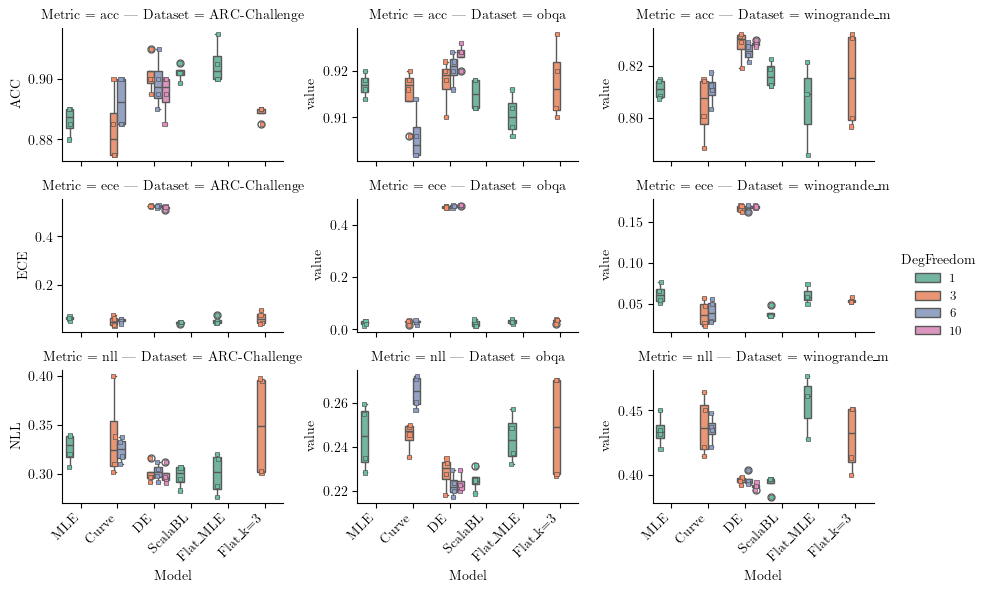

In [10]:
# Reference accuracy values from table 2
ref_acc = {
    'winogrande_s':       {'MLE': 78.86, 'MAP': 78.94, 'MC-Dropout': 78.57, 'Ensemble': 79.09, 'Laplace': 77.28, 'BLoB': 78.66, 'ScalaBL': 78.64},
    'ARC-Challenge':      {'MLE': 89.53, 'MAP': 88.98, 'MC-Dropout': 89.44, 'Ensemble': 89.44, 'Laplace': 85.25, 'BLoB': 89.53, 'ScalaBL': 90.16},
    'ARC-Easy':           {'MLE': 95.60, 'MAP': 95.73, 'MC-Dropout': 95.77, 'Ensemble': 95.73, 'Laplace': 95.34, 'BLoB': 96.54, 'ScalaBL': 96.26},
    'winogrande_m':       {'MLE': 82.30, 'MAP': 82.09, 'MC-Dropout': 82.72, 'Ensemble': 83.23, 'Laplace': 81.99, 'BLoB': 82.30, 'ScalaBL': 81.42},
    'obqa':               {'MLE': 92.25, 'MAP': 91.72, 'MC-Dropout': 91.80, 'Ensemble': 92.70, 'Laplace': 91.68, 'BLoB': 91.72, 'ScalaBL': 90.90},
    'boolq':              {'MLE': 89.06, 'MAP': 89.04, 'MC-Dropout': 88.99, 'Ensemble': 89.13, 'Laplace': 87.77, 'BLoB': 89.05, 'ScalaBL': 88.48},
}

# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])


g = sns.catplot(data=df_subset, x='Model', y='value', hue='DegFreedom', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset[(df_subset['Metric'] == row_name) & (df_subset['Dataset'] == col_name)],
            x='Model',
            y='value',
            hue='DegFreedom',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            palette='Set2',
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())



# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()


/tmp/ipykernel_51909/1676404820.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
/tmp/ipykernel_51909/1676404820.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)


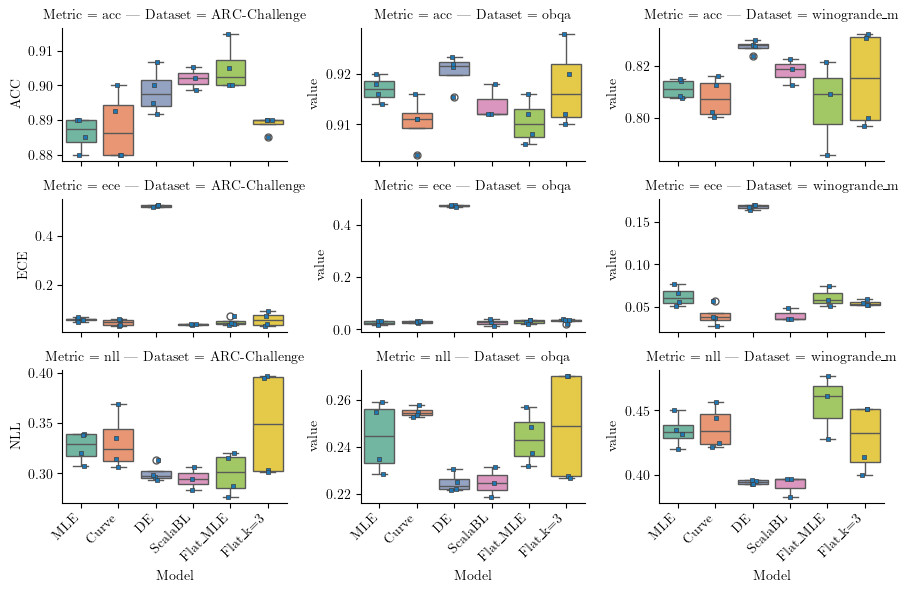

In [9]:
# Reference accuracy values from table 2
# df_subset = df_subset[df_subset['Model']==0]
hue_order = df_subset['DegFreedom'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]
# hue_order = []

df_subset2 = df_subset.groupby(['Dataset', 'Model', 'Seed', 'Metric']).mean().reset_index()
# Sort by Model order (MLE, Curve, DE, ScalaBL) and DegFreedom
# model_order = ['MLE', 'Curve', 'DE', 'ScalaBL']
# df_subset['Model'] = pd.Categorical(df_subset['Model'], categories=model_order, ordered=True)
# df_subset = df_subset.sort_values(['Model', 'Dataset', 'Metric'])

g = sns.catplot(data=df_subset2, x='Model', y='value', kind='box', col='Dataset', row='Metric', palette='Set2', height=figsize[1], sharey=False, col_order=col_order, aspect=1.5)
for ax_row in g.axes:
    for ax in ax_row:
        row_name = ax.get_title().split('=')[1].split('|')[0].strip()
        col_name = ax.get_title().split('=')[2].strip()
        # 3. Draw the stripplot onto the current axes (ax)
        # Use the axes-level function `sns.stripplot` here.
        sns.stripplot(
            data=df_subset2[(df_subset2['Metric'] == row_name) & (df_subset2['Dataset'] == col_name)],
            x='Model',
            y='value',
            ax=ax,  # <-- Tell the stripplot which axis to draw on
            dodge=True, # <-- Aligns points with the dodged boxes
            edgecolor='auto',
            linewidth=0.5,
            size=3,
            marker="s",
            hue_order=hue_order,
            legend=False  # <-- Avoid drawing a second legend
        )

for ax in g.axes[:,0].flatten():
    row_name = ax.get_title().split('=')[1].split('|')[0].strip()
    ax.set_ylabel(row_name.upper())

# Adjust legend placement if needed
for ax in g.axes[-1,].flat:
    ax.tick_params(axis='x', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
g.tight_layout()
